# Coloured cluster flows: see the shifts

## Main t-SNE baseline
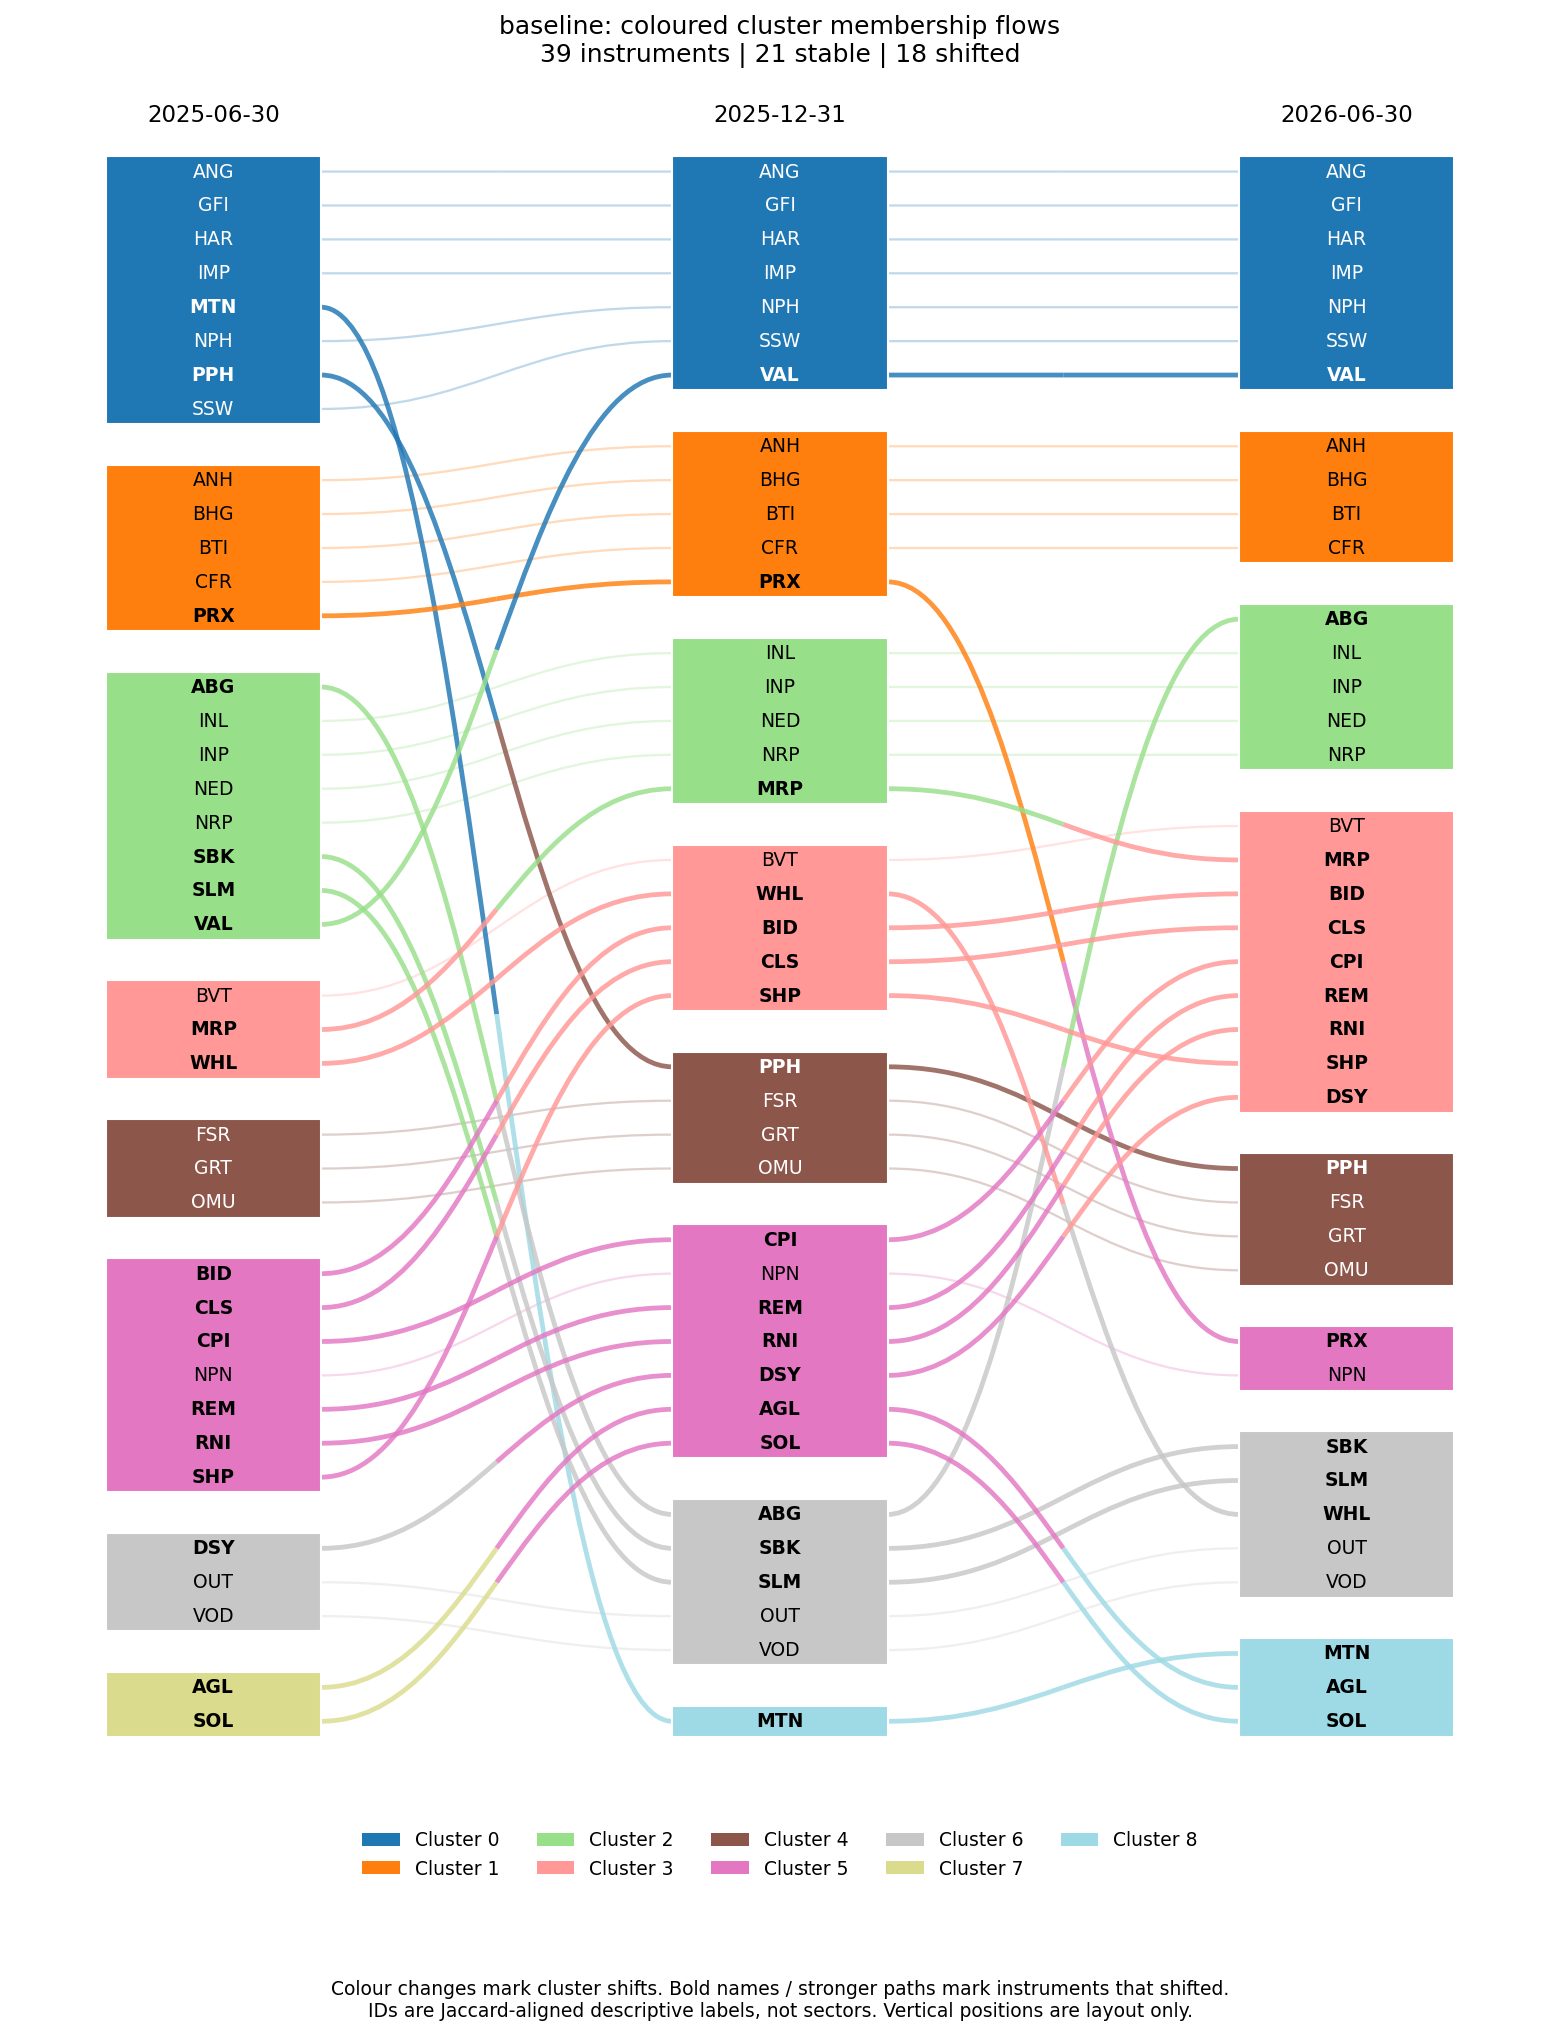

## Fixed UMAP comparison
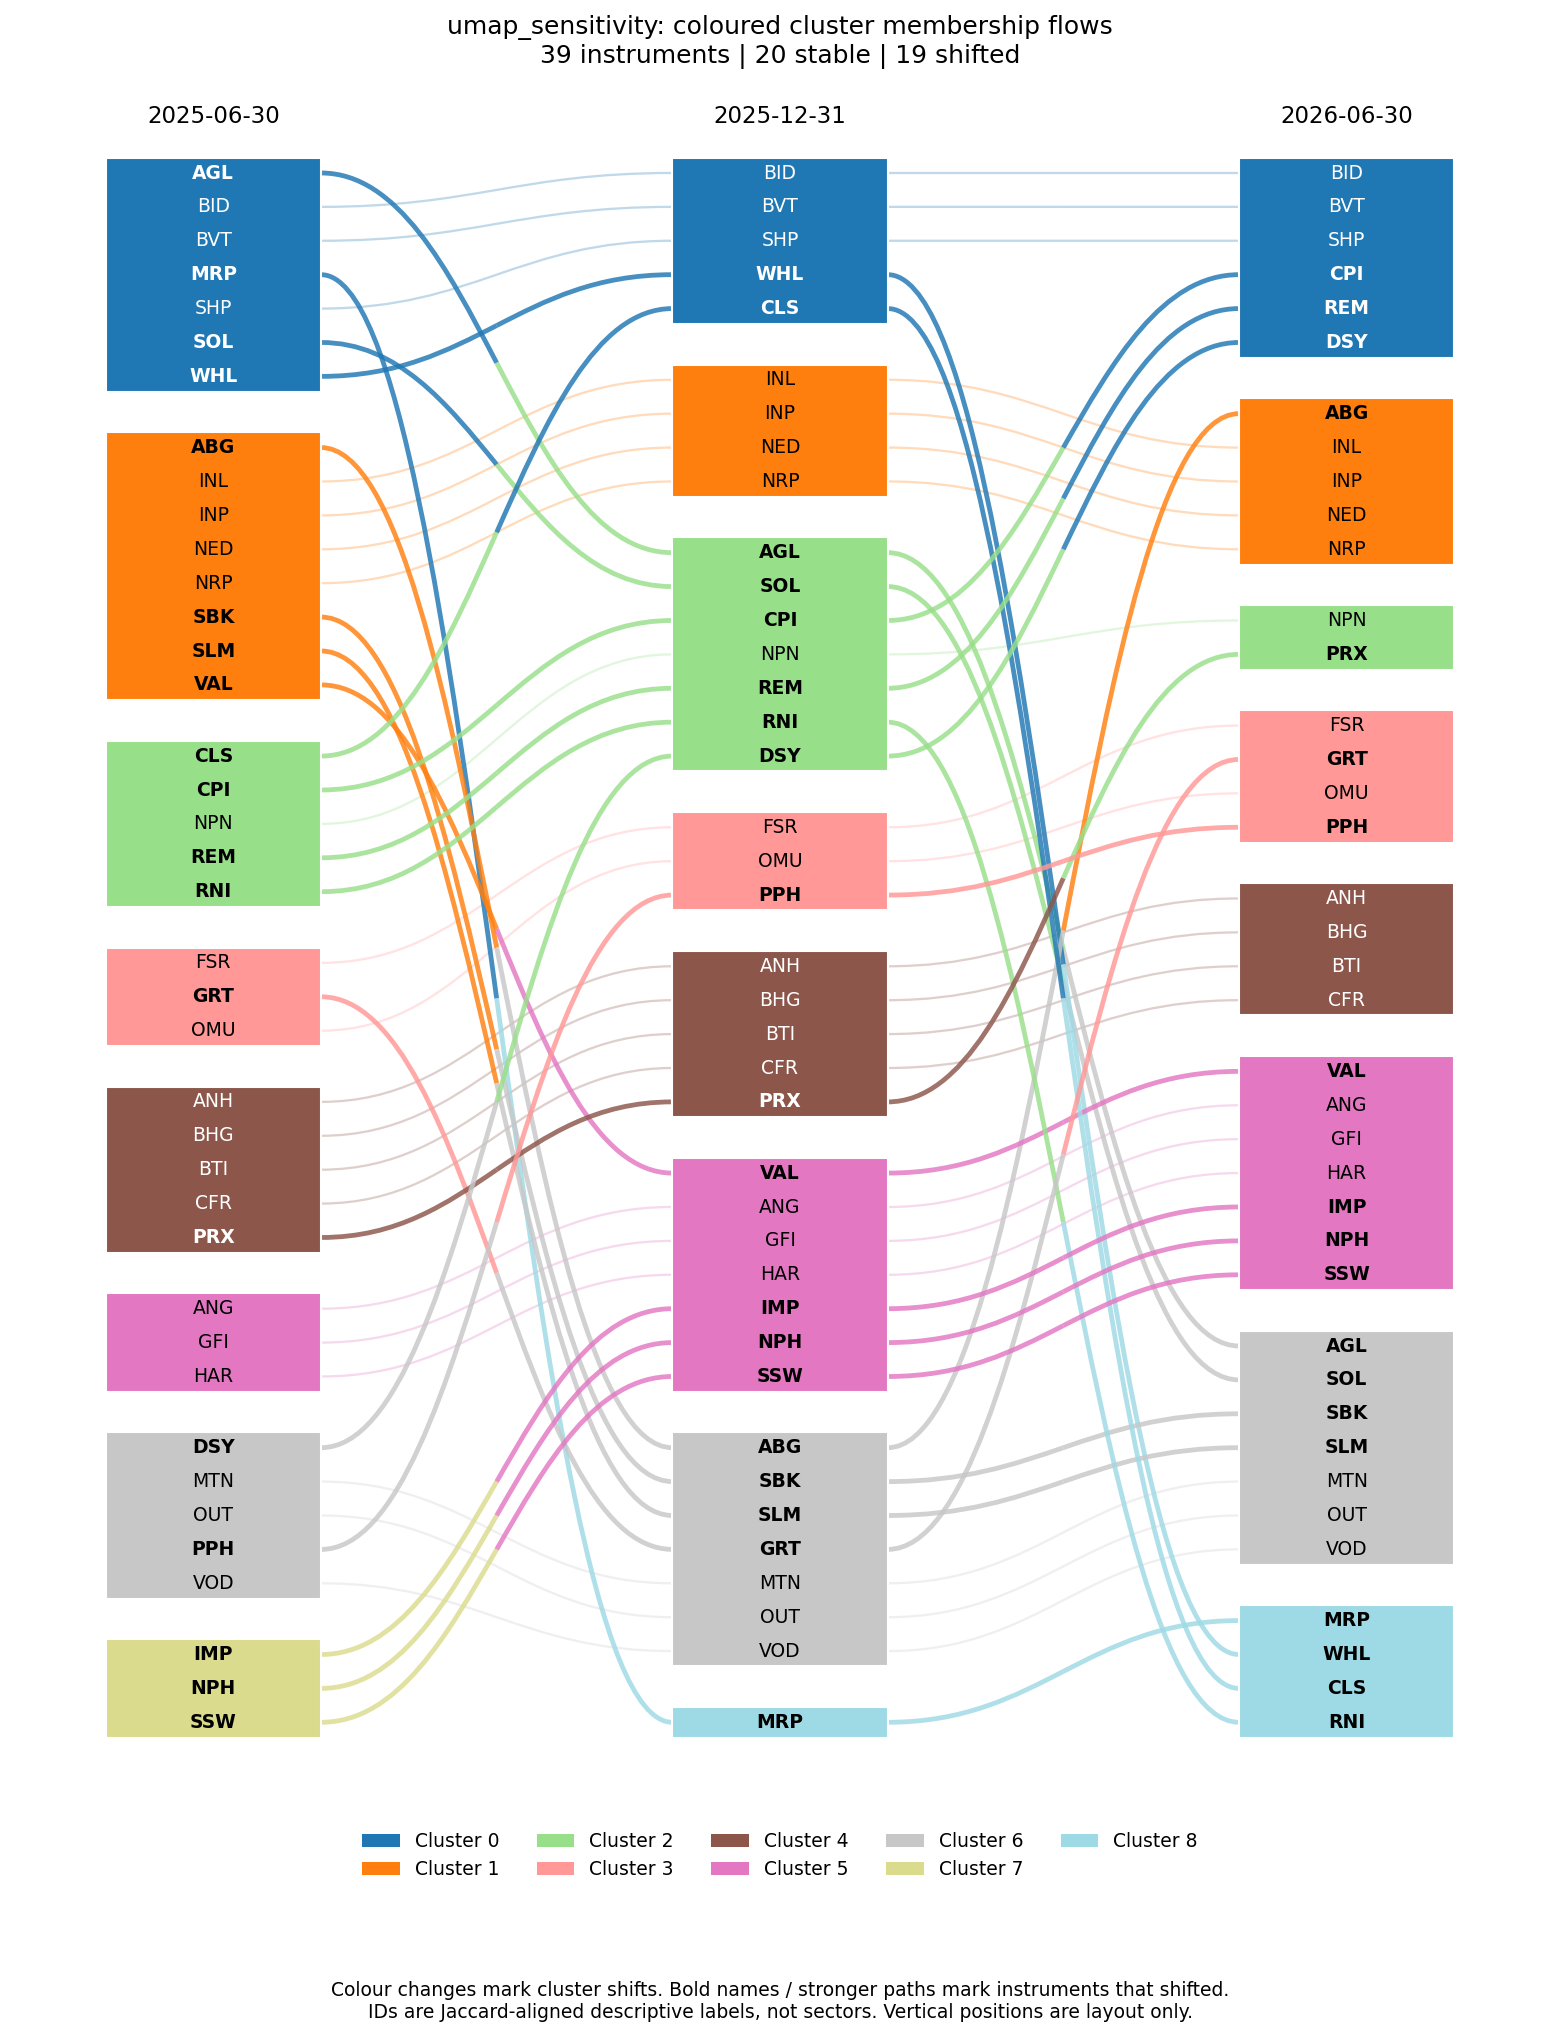

Each labelled strand follows one instrument across the three dates. **A colour change marks a cluster-membership shift.** Bold names and stronger paths mark instruments that shifted at least once. Vertical position is layout only. Cluster IDs are descriptive Jaccard-aligned labels, not sectors.

The actual Jaccard similarity heatmaps and full analysis follow below.

# Jaccard plots

## Main model: t-SNE baseline

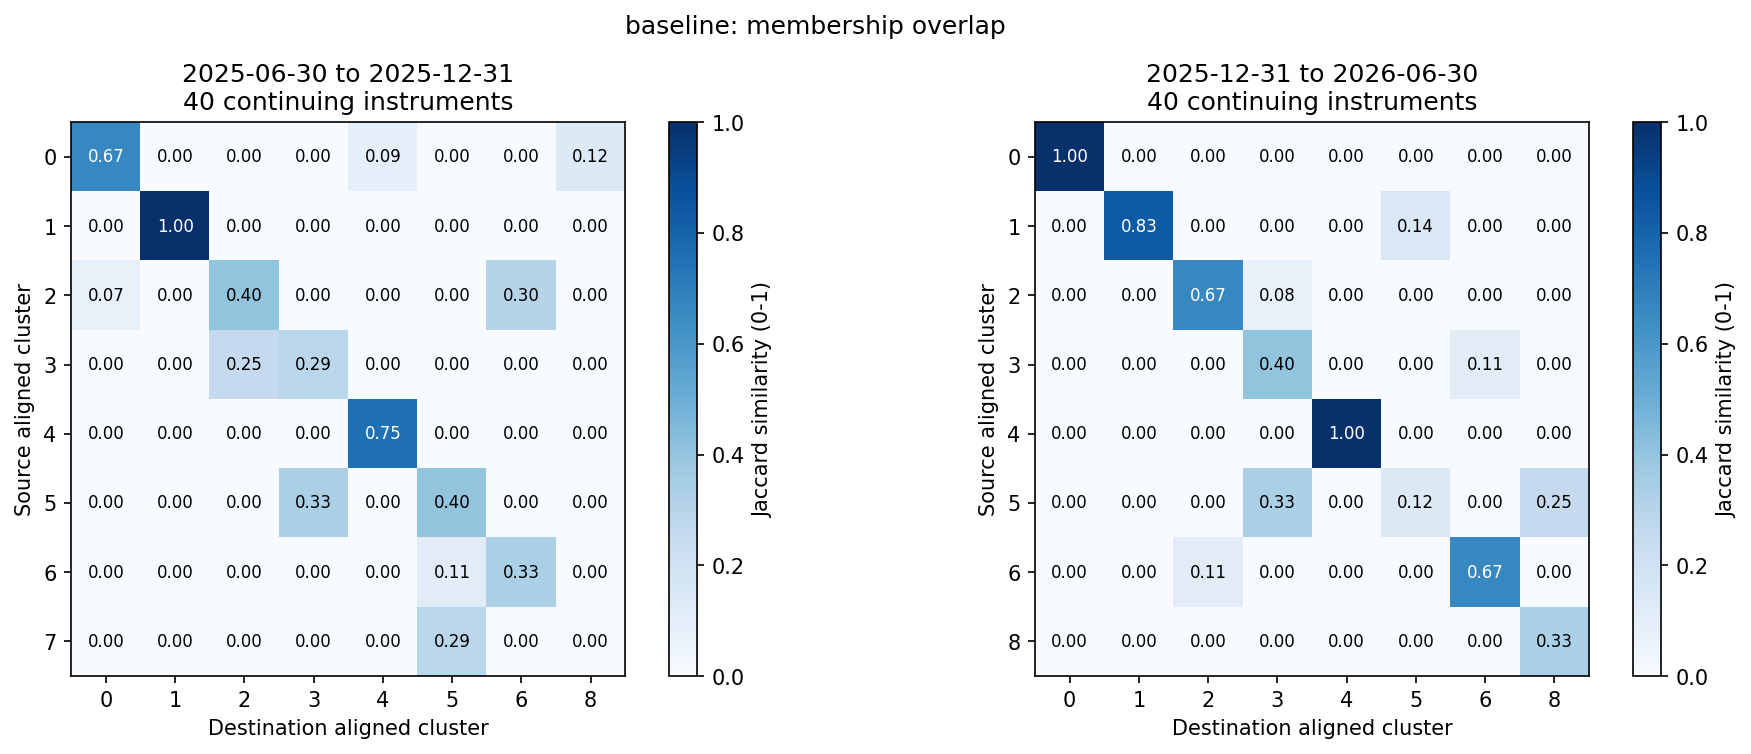

## Fixed UMAP comparison

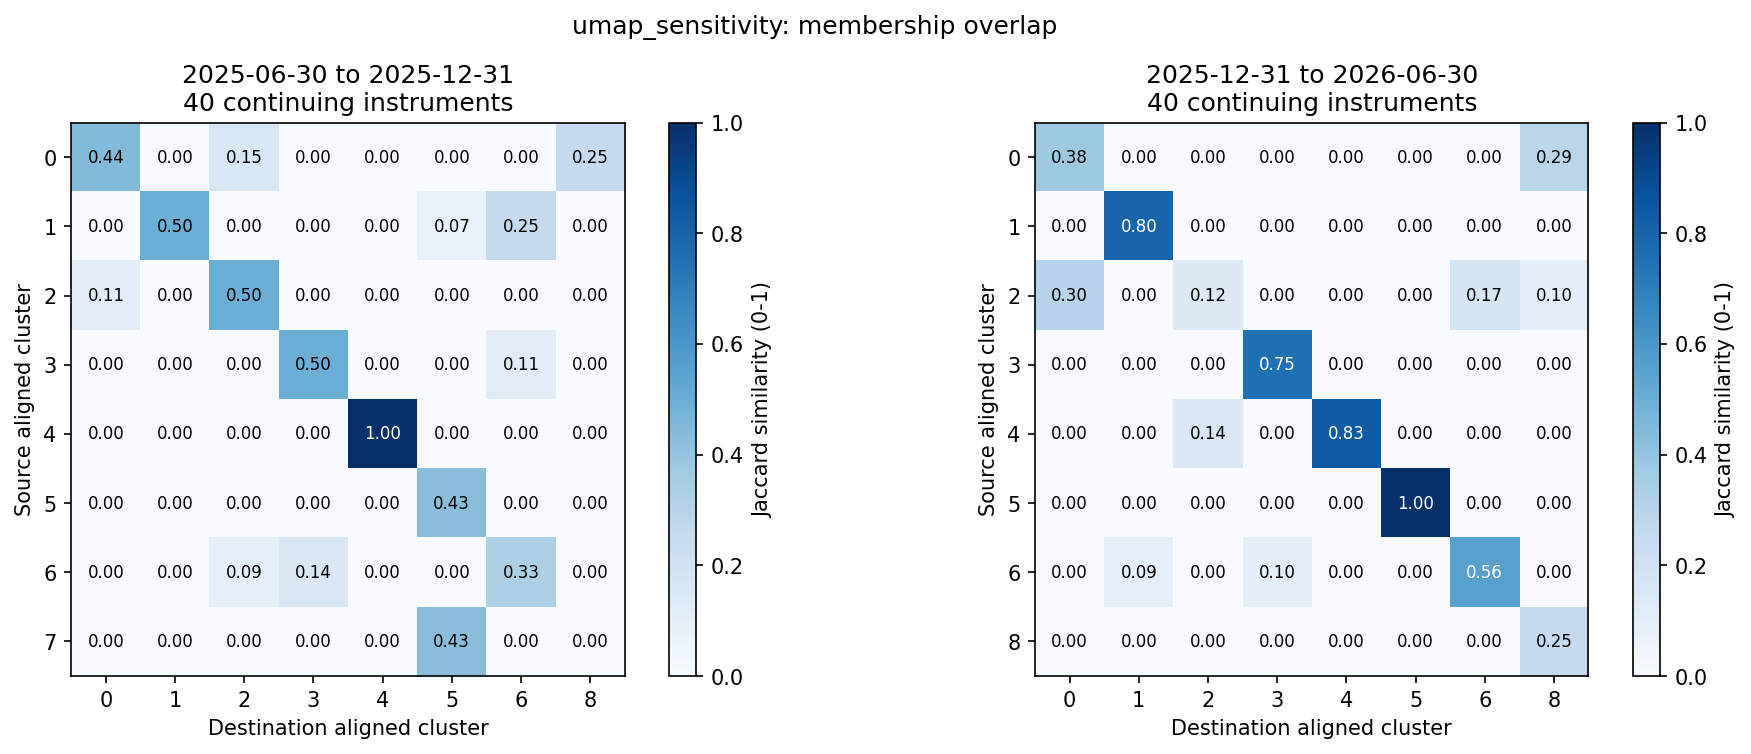

**Read the panels left to right:** June?December 2025, then December 2025?June 2026. Each comparison uses the 40 continuing instruments. Scores range from **0 (no overlap)** to **1 (identical membership)**. These are membership similarities, not movement counts or transition probabilities.

The full analysis, cluster histories and movement counts follow below.

# Three Cross Sections: enriched reporting review

The **original t-SNE baseline and fixed UMAP comparison** are retained. This read-only notebook brings across useful Paper Experiments reporting without adopting the PCA winner, searching parameters or fitting any model.

Source: completed `three-cross-section-population-clarified-02`. Supplementary charts: `reports/three_cross_section_enriched_20261108`.

The editable full workflow remains `notebooks/three_cross_section_study.ipynb`. This preview reads its earlier saved partitions and explanations; it does not rerun that workflow.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd() if (Path.cwd() / "scripts").is_dir() else Path.cwd().parent
SOURCE = ROOT / "experiments/runs/three-cross-section-population-clarified-02"
REPORT = ROOT / "reports/three_cross_section_enriched_20261108"
DATES = ["2025-06-30", "2025-12-31", "2026-06-30"]
MODELS = {"baseline": "models", "umap_sensitivity": "umap_sensitivity"}
def show(path):
    display(Image(filename=str(path)))
print("Reading saved models only:", SOURCE)

FLOW_REPORT = ROOT / "reports/three_cross_section_history_flows_20261108"


Reading saved models only: C:\Users\HP\Documents\GitHub\JSE-Top-40-Clustering\experiments\runs\three-cross-section-population-clarified-02


## Jaccard plots: start here

### Main model: t-SNE baseline
Each panel compares cluster membership at two consecutive dates: **June?December 2025** and **December 2025?June 2026**. Values are actual Jaccard similarities from **0 to 1**, calculated on the 40 continuing instruments in each pair. They are not instrument counts or transition probabilities.

[Open the full-size baseline Jaccard plot](three_cross_section_enriched_20261108/baseline/jaccard_heatmaps.png).

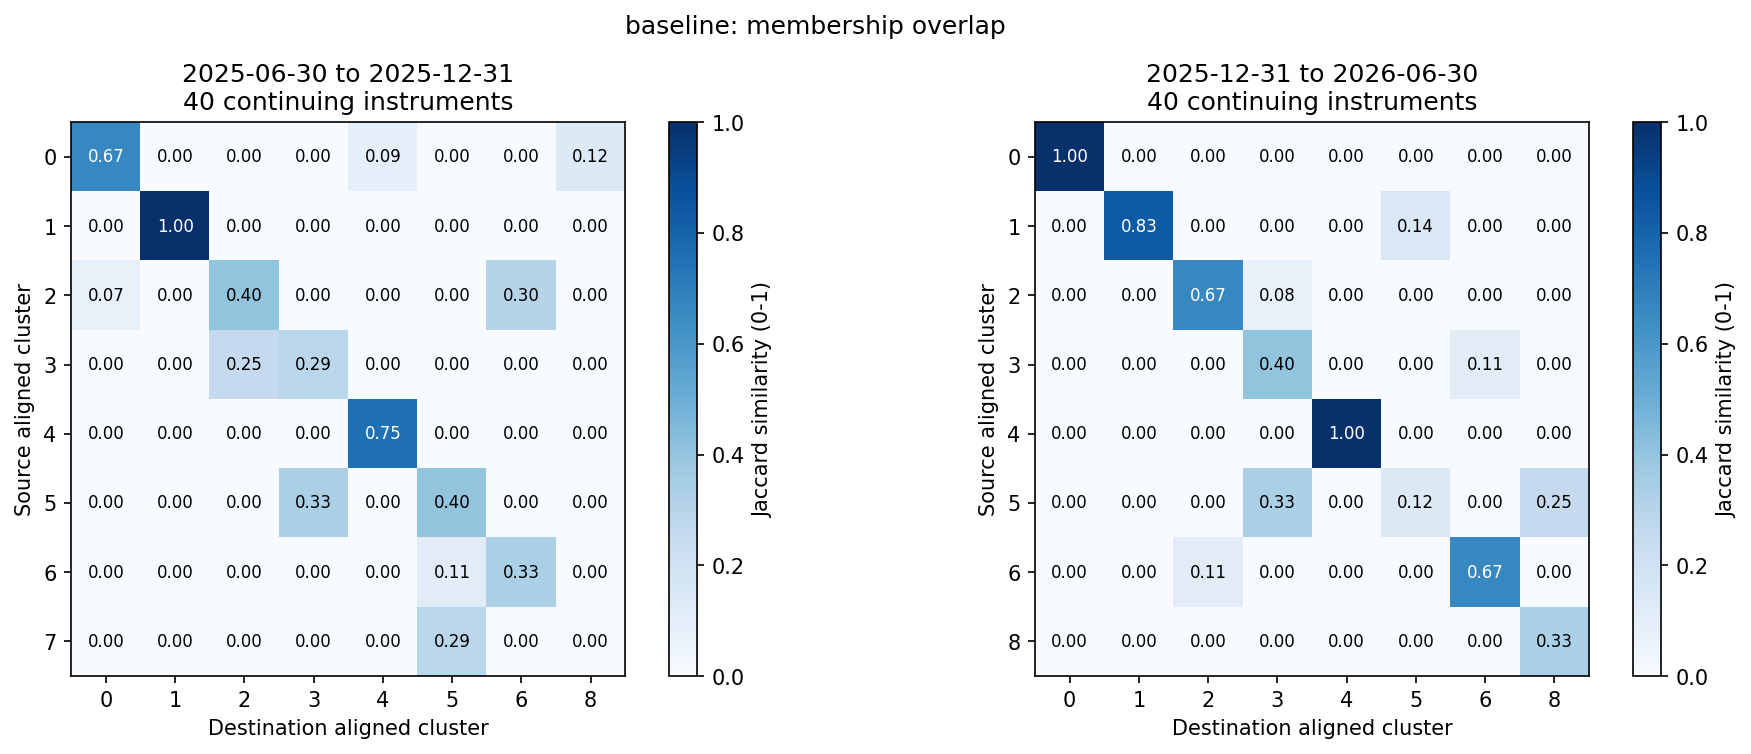

In [2]:
show(REPORT / "baseline/jaccard_heatmaps.png")

### Comparison model: fixed UMAP sensitivity
The same dates and 0-1 scale, using the saved UMAP partitions.

[Open the full-size UMAP Jaccard plot](three_cross_section_enriched_20261108/umap_sensitivity/jaccard_heatmaps.png).

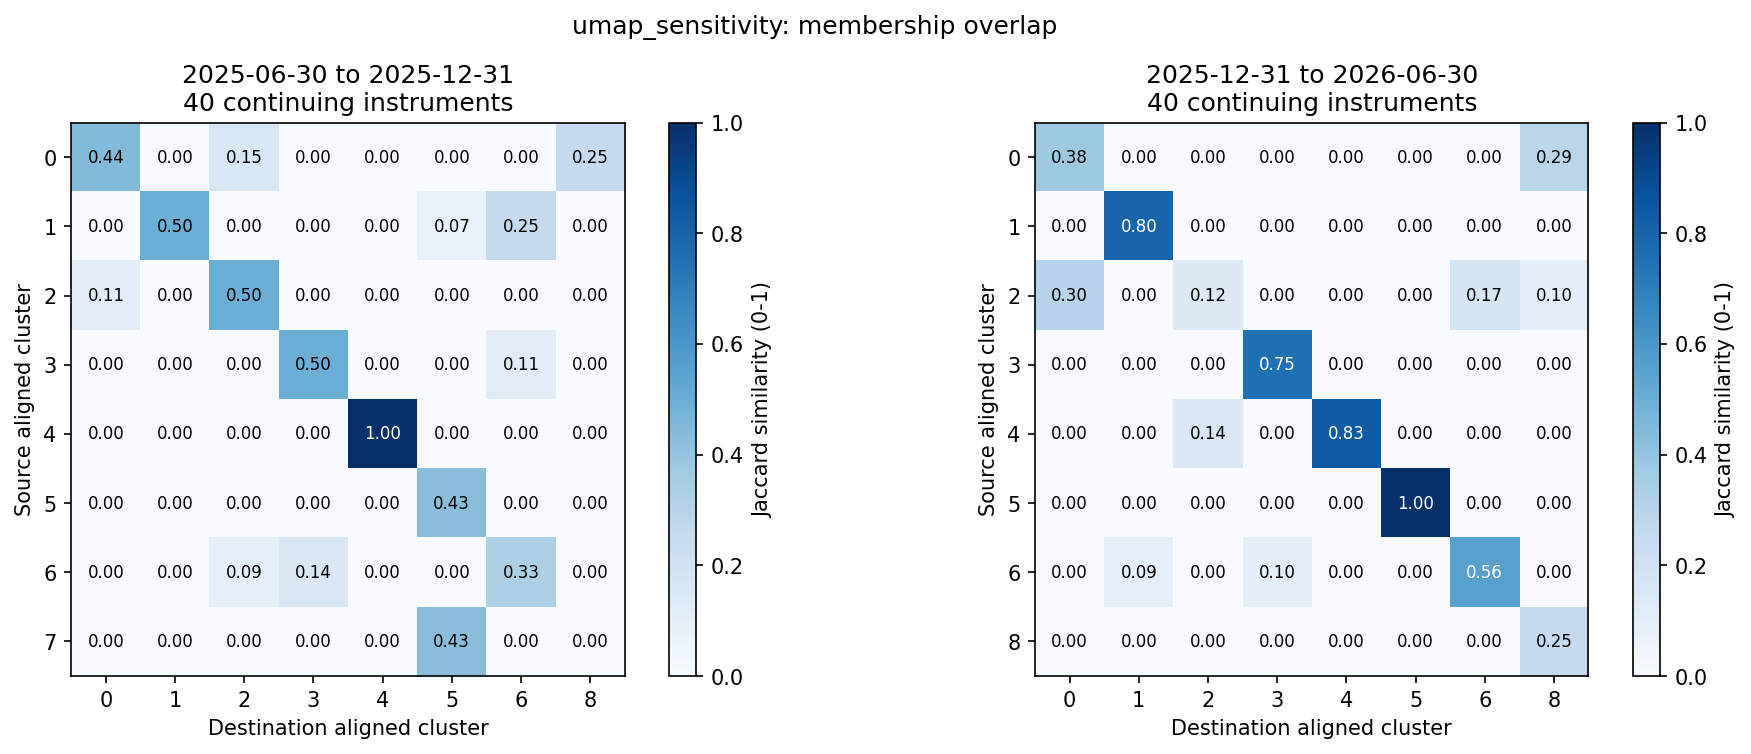

In [3]:
show(REPORT / "umap_sensitivity/jaccard_heatmaps.png")

## Population and sector context
40 economic groups / 41 listed instruments at each snapshot. INL and INP remain distinct instruments within one Investec DLC group. Repeated cross-sections overlap; index entries/exits are not ordinary cluster changes.

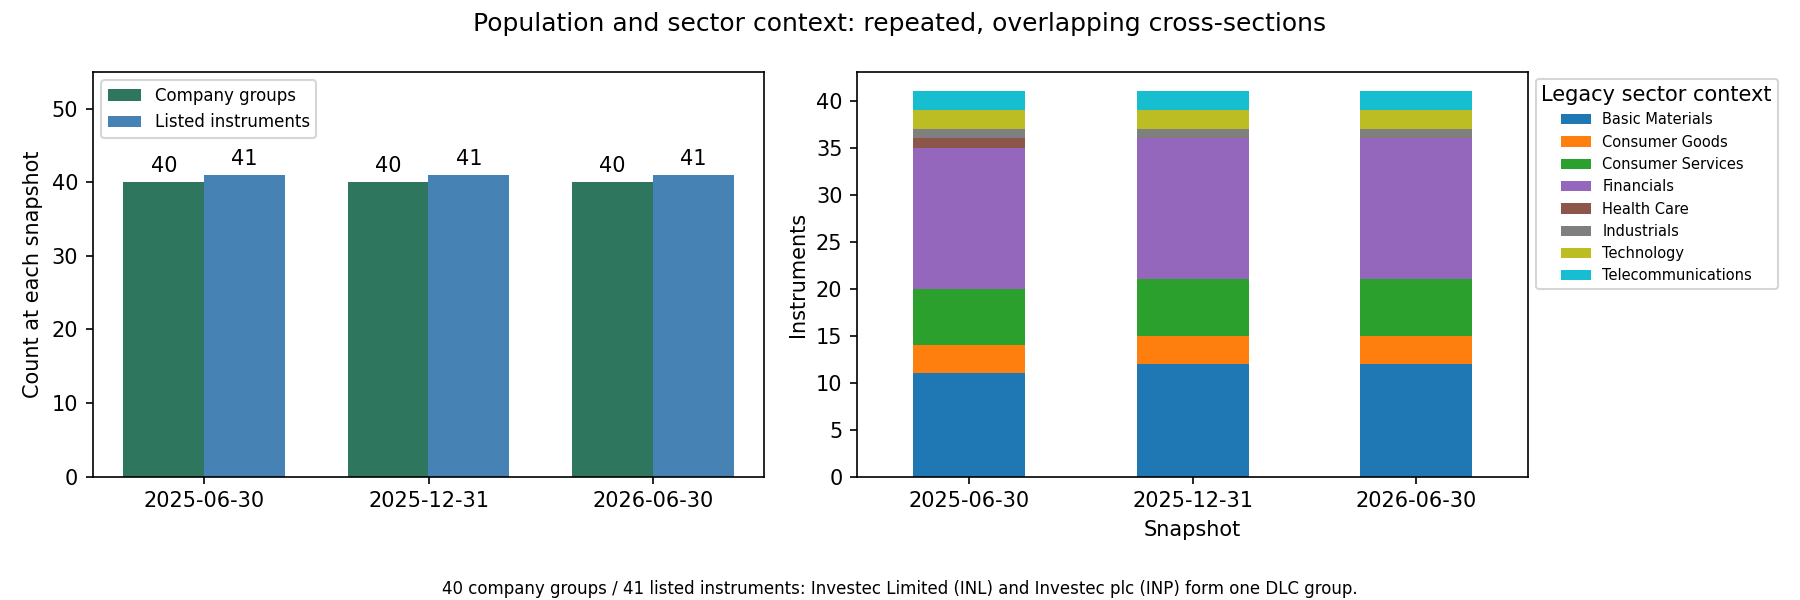

,decision_date,instruments,distinct_tickers,fundamental_imputations,volume_imputations,economic_groups
0,2025-06-30,41,41,1,1,40
1,2025-12-31,41,41,1,1,40
2,2026-06-30,41,41,1,0,40


,decision_date,feature,raw_missing,model_missing
1,2025-06-30,average_daily_volume_1y_model,1,0
5,2025-06-30,revenue_zar_model,1,0
6,2025-06-30,eps_zar_model,1,0
9,2025-06-30,earnings_yield_model_clipped,1,0
11,2025-12-31,average_daily_volume_1y_model,1,0
15,2025-12-31,revenue_zar_model,1,0
16,2025-12-31,eps_zar_model,1,0
19,2025-12-31,earnings_yield_model_clipped,1,0
25,2026-06-30,revenue_zar_model,1,0
26,2026-06-30,eps_zar_model,1,0


,decision_date,field,status,n
0,2025-06-30,membership_evidence,VERIFIED,41
1,2025-12-31,membership_evidence,VERIFIED,41
2,2026-06-30,membership_evidence,VERIFIED,41
3,2025-06-30,fundamentals_evidence,DATED_ISSUER_RELEASE,40
4,2025-06-30,fundamentals_evidence,UNRESOLVED_IMPUTED_FOR_MODEL,1
5,2025-12-31,fundamentals_evidence,DATED_ISSUER_RELEASE,40
6,2025-12-31,fundamentals_evidence,UNRESOLVED_IMPUTED_FOR_MODEL,1
7,2026-06-30,fundamentals_evidence,DATED_ISSUER_RELEASE,40
8,2026-06-30,fundamentals_evidence,UNRESOLVED_IMPUTED_FOR_MODEL,1
9,2025-06-30,market_evidence,RETROSPECTIVE_VENDOR_DAILY_HISTORY,41


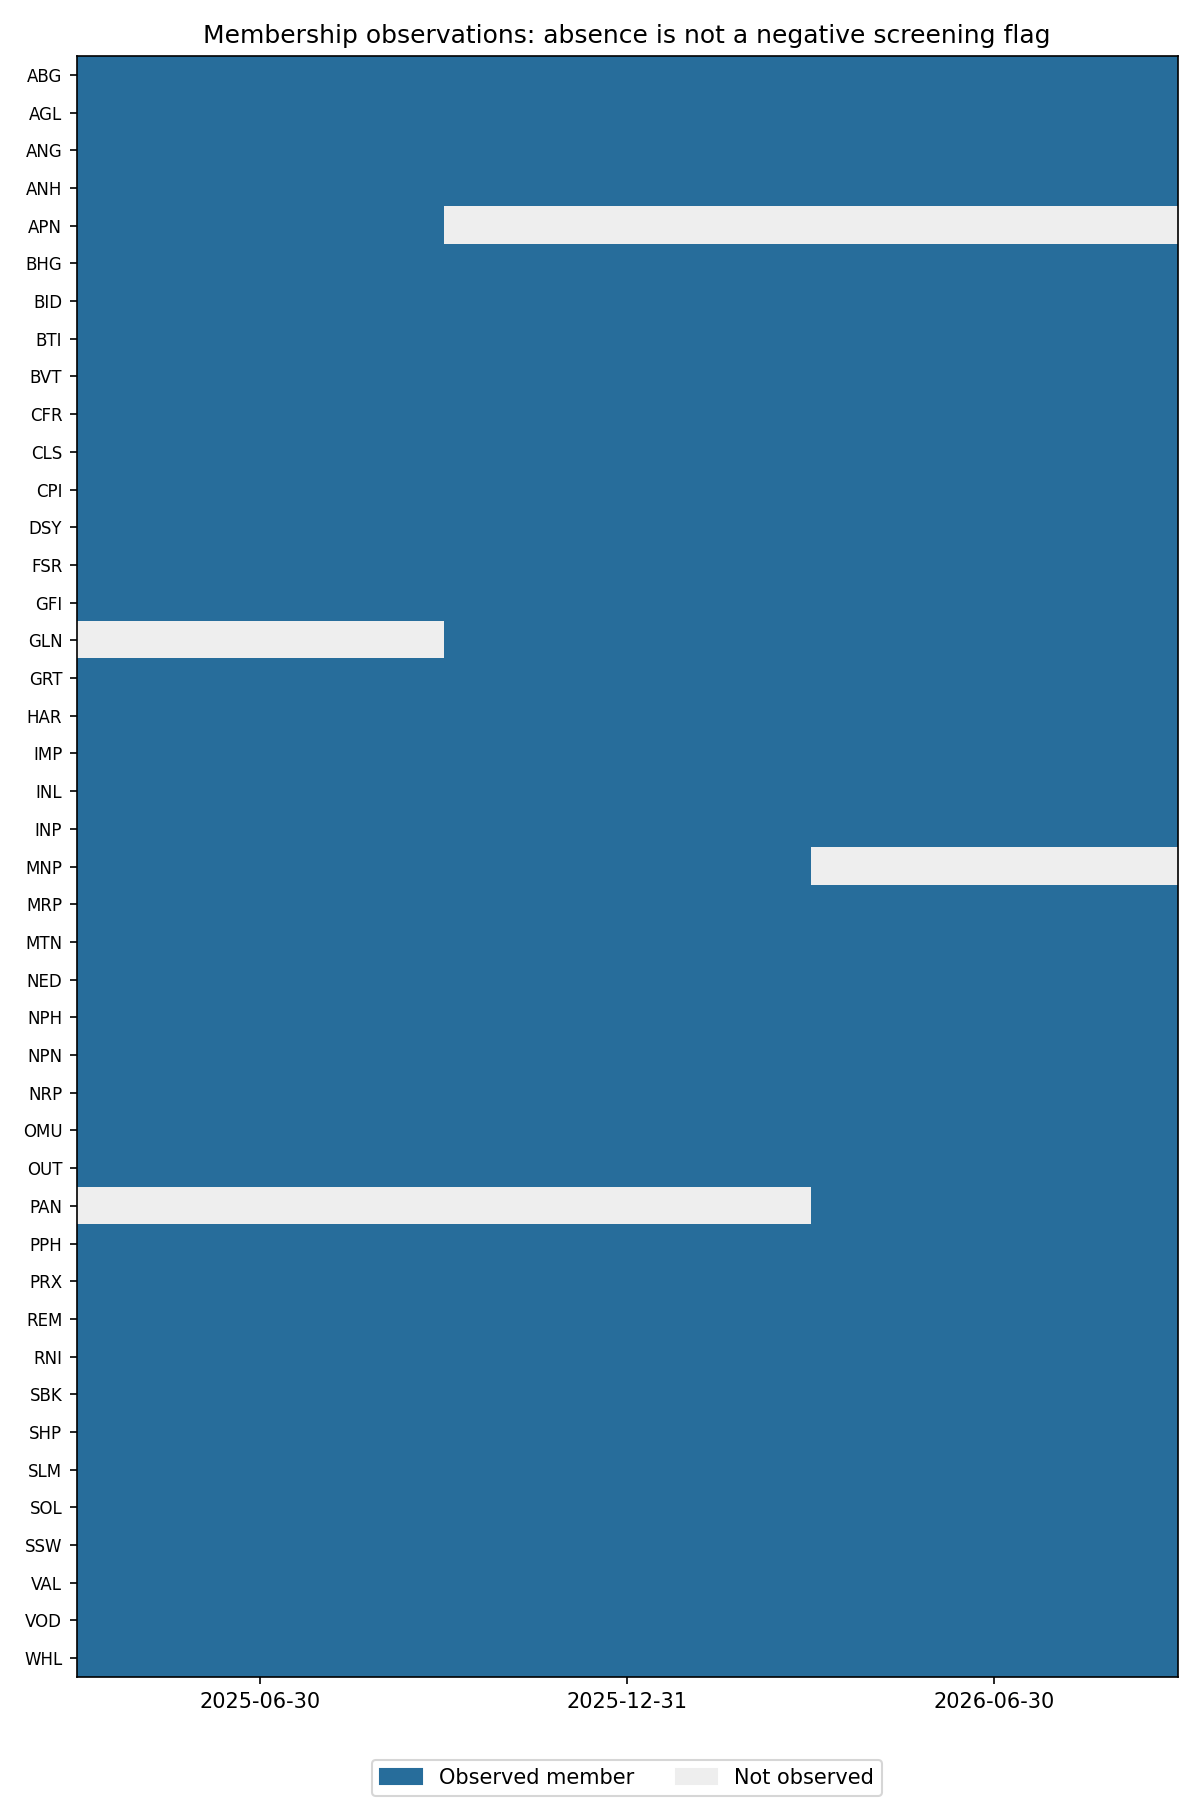

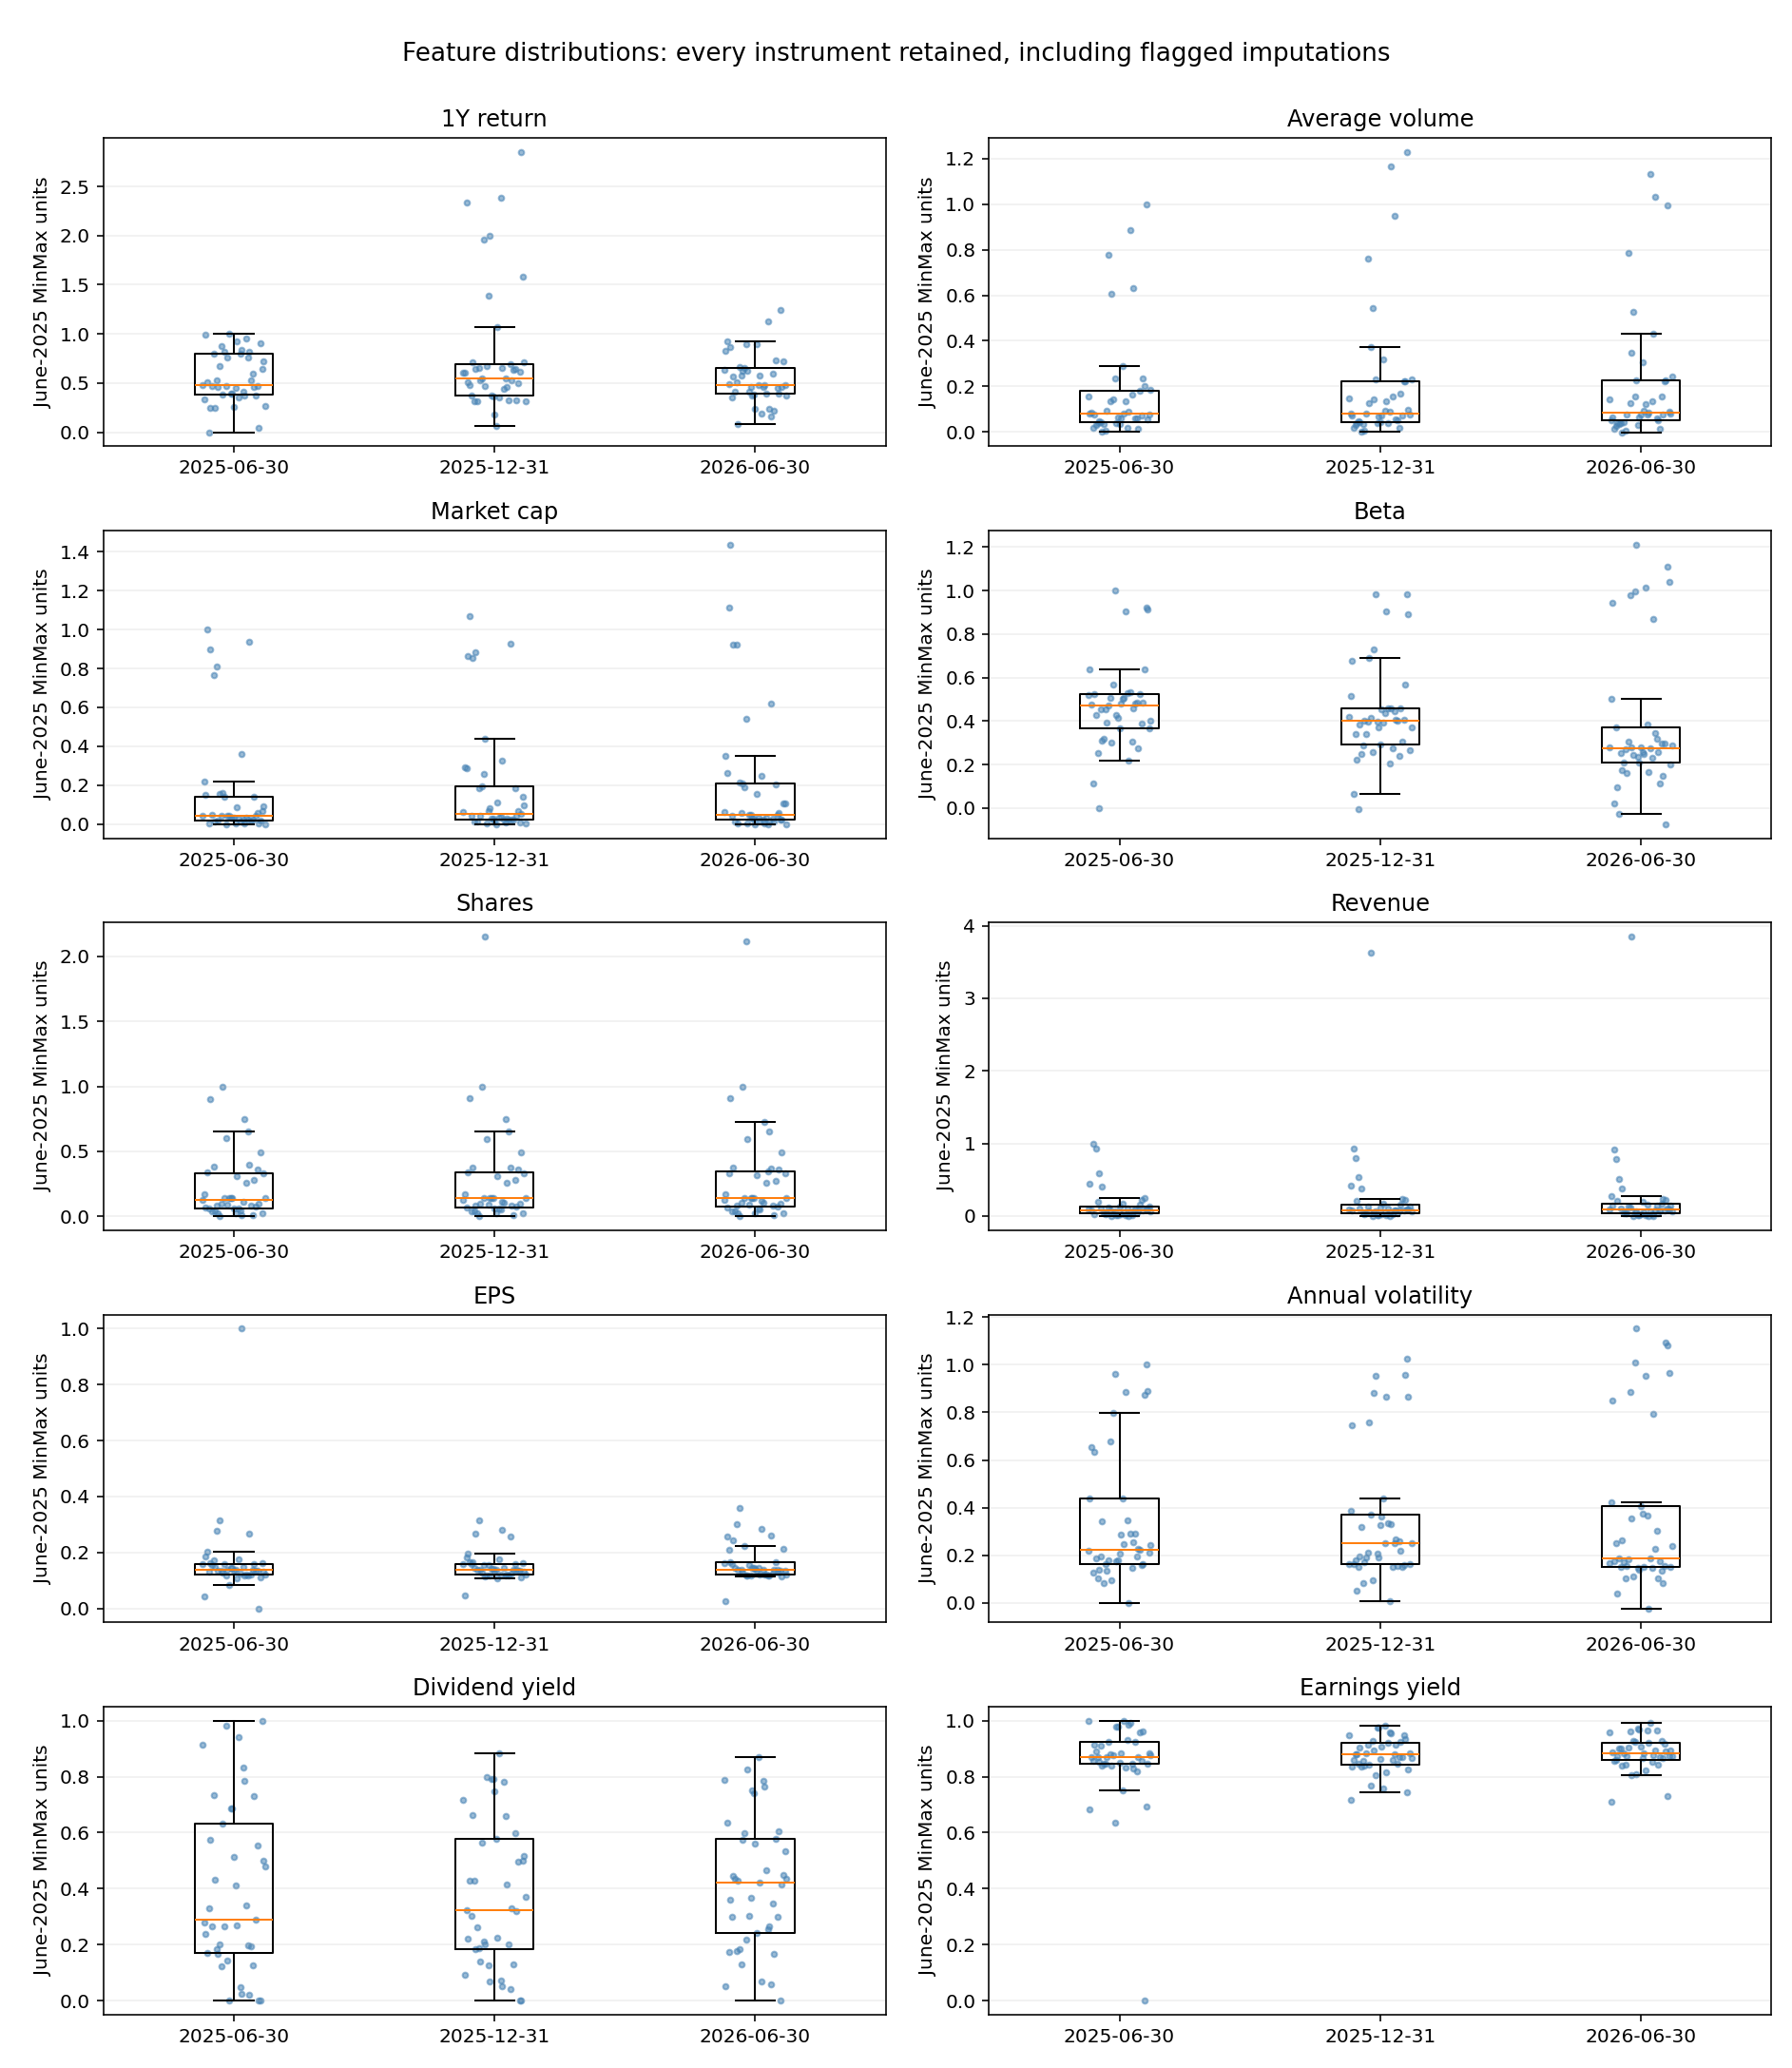

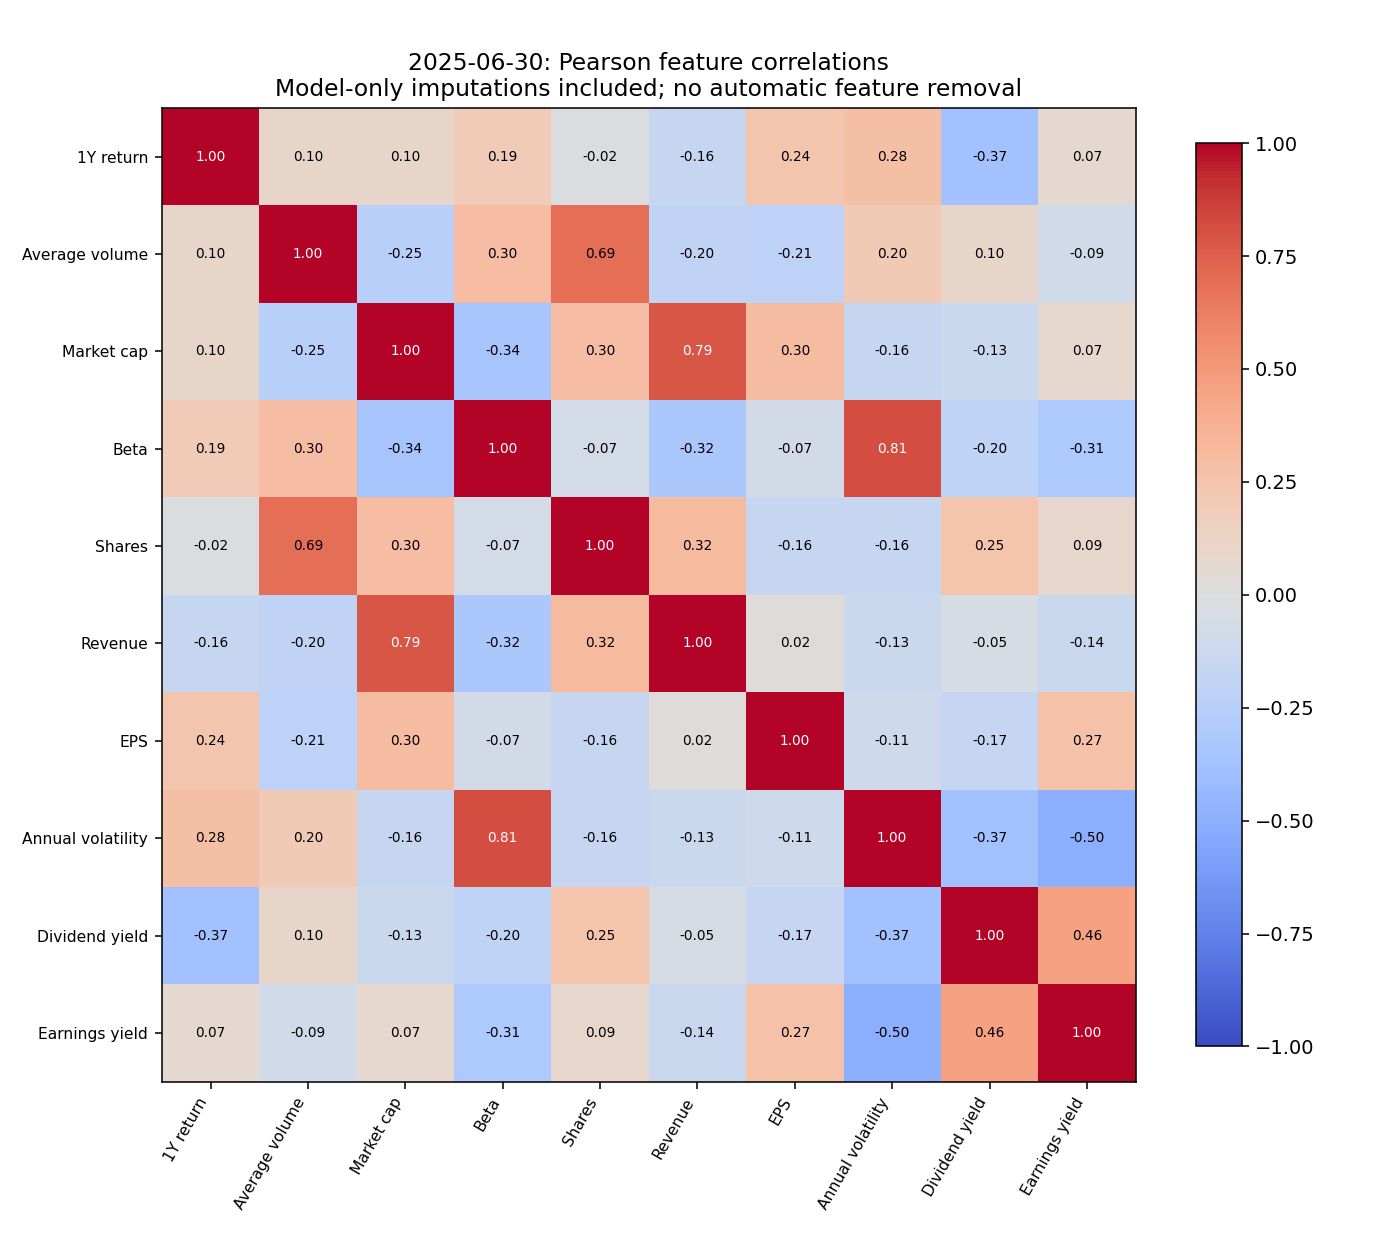

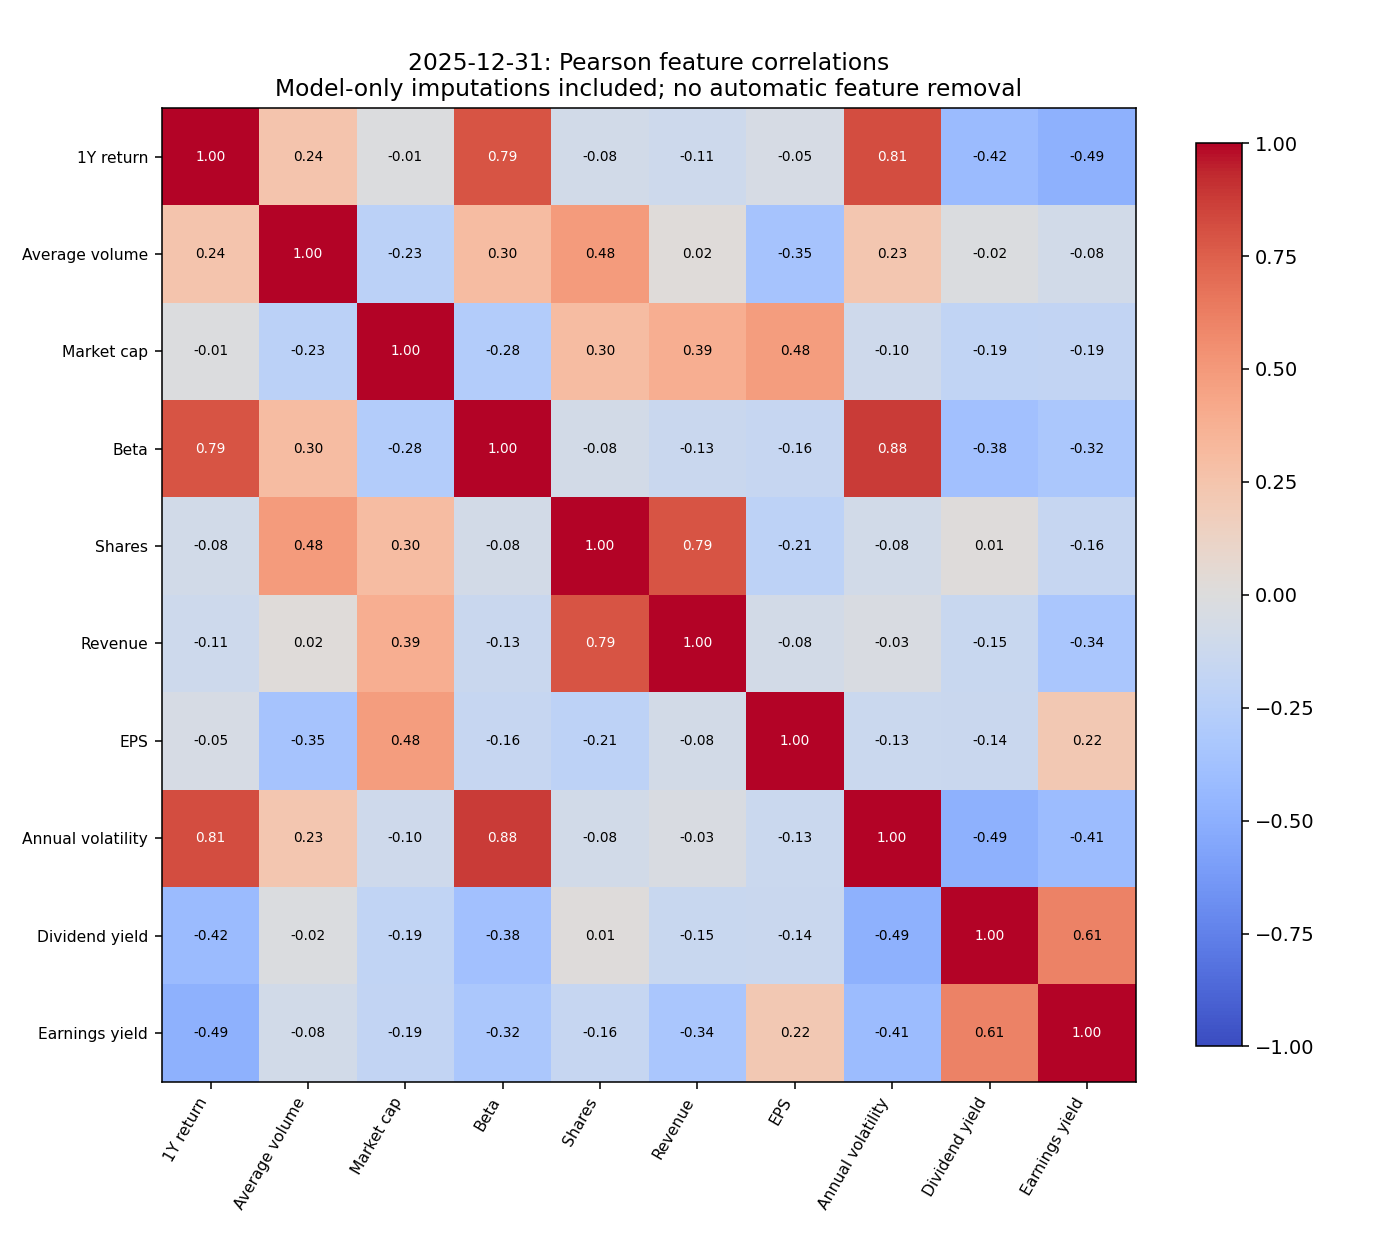

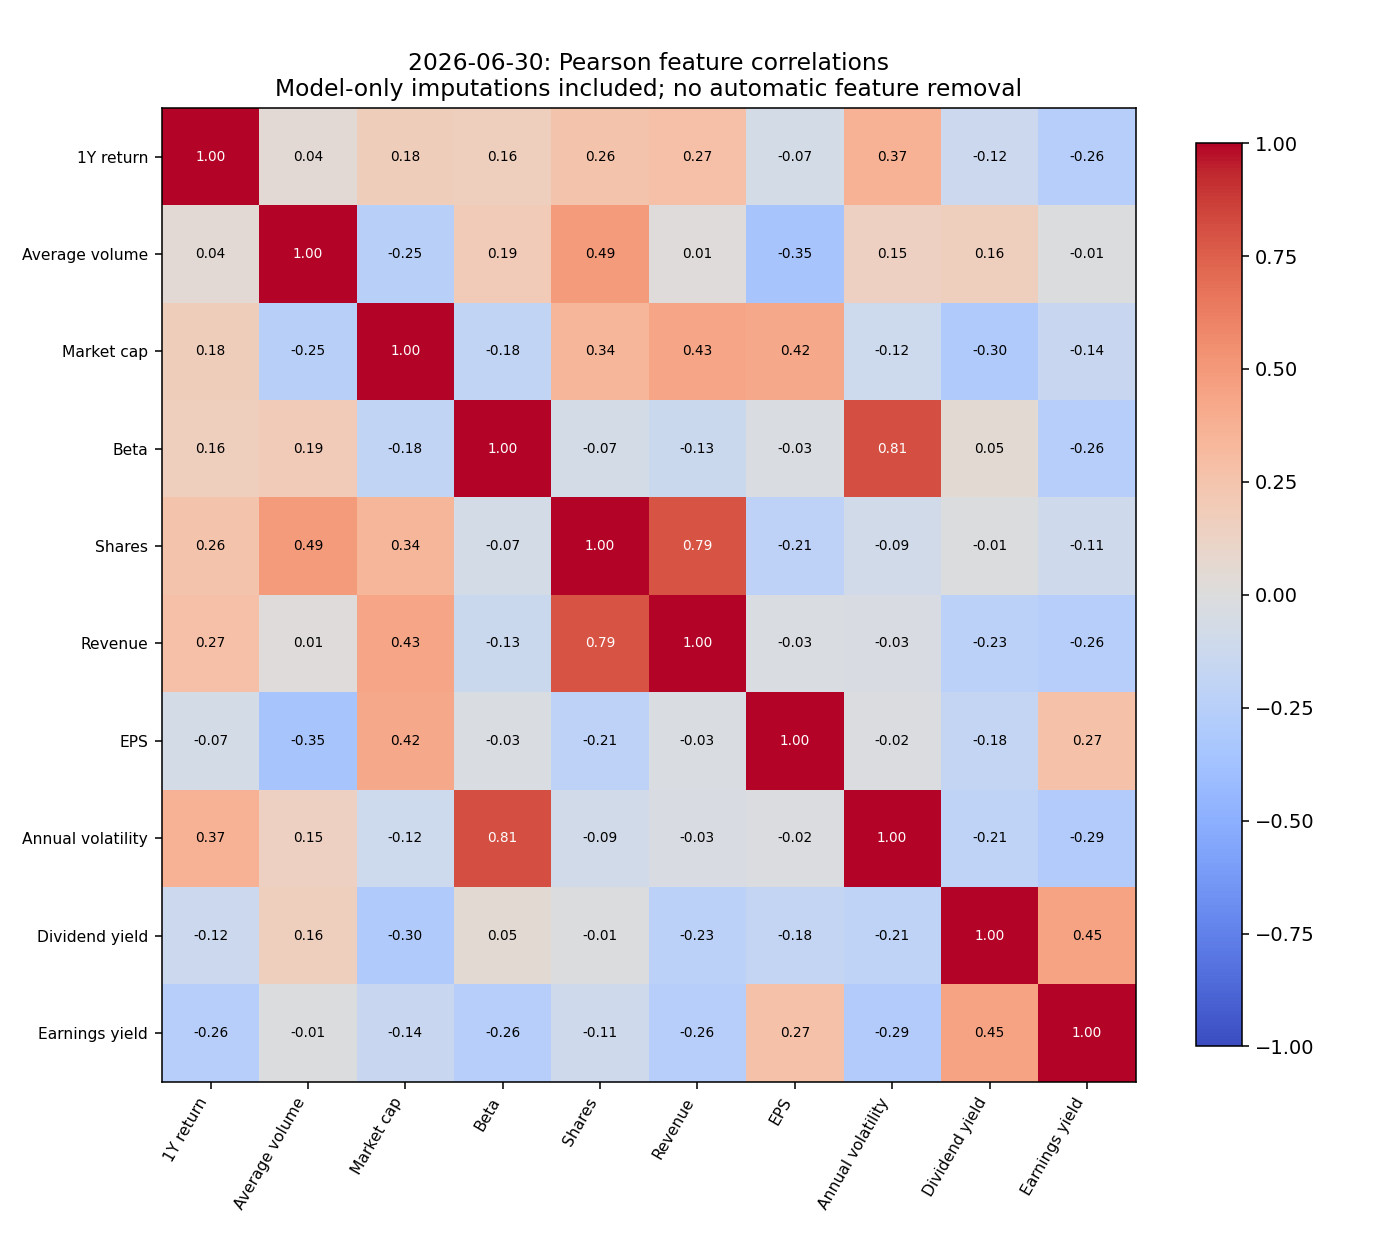

In [4]:
show(REPORT / "population_and_sectors.png")
display(pd.read_csv(SOURCE / "eda/population.csv"))
display(pd.read_csv(SOURCE / "eda/missingness.csv").query("raw_missing > 0"))
display(pd.read_csv(SOURCE / "eda/evidence.csv"))
show(SOURCE / "eda/membership_presence.png")
show(SOURCE / "eda/feature_distributions.png")
for date in DATES:
    show(SOURCE / f"eda/correlation_{date}.png")


## Models, quality and stability
The t-SNE average-linkage Manhattan baseline remains the main model. UMAP is the fixed sensitivity. Balanced appearance alone does not validate either partition. Retain original feature/embedding scores, all seed comparisons and fidelity limitations.

,decision_date,model,n_clusters,noise_count,coverage,silhouette_metric,davies_bouldin_geometry,silhouette_embedding,silhouette_features,davies_bouldin_embedding,...,sector_nmi,clustering_geometry,davies_bouldin_features,study_model,in_sample_accuracy,oof_accuracy,oof_status,minimum_cluster_size,shap_max_additivity_error,mean_seed_ari
0,2025-06-30,tsne_hierarchical,8,0,1.0,euclidean,euclidean embedding centroids,0.5709,0.1817,0.4291,...,0.5235,manhattan embedding,1.0972,baseline,1.0,0.5366,estimated,2,0.0,0.7274
1,2025-12-31,tsne_hierarchical,8,0,1.0,euclidean,euclidean embedding centroids,0.5981,0.1767,0.4472,...,0.5417,manhattan embedding,1.0142,baseline,1.0,NaN,not estimable: singleton cluster,1,0.0,0.9202
2,2026-06-30,tsne_hierarchical,8,0,1.0,euclidean,euclidean embedding centroids,0.6414,0.2230,0.4071,...,0.6013,manhattan embedding,1.1103,baseline,1.0,0.7317,estimated,2,0.0,0.9342
3,2025-06-30,umap_fixed_sensitivity,8,0,1.0,euclidean,euclidean embedding centroids,0.7465,0.2094,0.2998,...,0.5286,manhattan embedding,1.1099,umap_sensitivity,1.0,0.6098,estimated,3,0.0,0.8143
4,2025-12-31,umap_fixed_sensitivity,8,0,1.0,euclidean,euclidean embedding centroids,0.7327,0.2024,0.3463,...,0.5735,manhattan embedding,1.0327,umap_sensitivity,1.0,0.6341,estimated,2,0.0,0.9105
5,2026-06-30,umap_fixed_sensitivity,8,0,1.0,euclidean,euclidean embedding centroids,0.7005,0.2011,0.3708,...,0.5893,manhattan embedding,1.2276,umap_sensitivity,1.0,0.7073,estimated,2,0.0,0.7643


,decision_date,model,n_clusters,noise_count,coverage,silhouette_metric,davies_bouldin_geometry,silhouette_embedding,silhouette_features,davies_bouldin_embedding,sector_ari,sector_nmi,clustering_geometry,davies_bouldin_features
0,2025-06-30,pca_hierarchical,8,0,1.0000,euclidean,euclidean embedding centroids,0.4264,0.1767,0.4158,0.3118,0.5355,manhattan embedding,0.9809
1,2025-06-30,pca_kmeans,8,0,1.0000,euclidean,euclidean embedding centroids,0.3974,0.0725,0.5554,0.1564,0.4897,euclidean embedding,1.4014
2,2025-06-30,pca_dbscan,2,9,0.7805,euclidean,euclidean embedding centroids,0.5397,0.3929,0.4313,0.0296,0.1521,euclidean standardized embedding,0.8840
3,2025-06-30,tsne_hierarchical,8,0,1.0000,euclidean,euclidean embedding centroids,0.5709,0.1817,0.4291,0.2364,0.5235,manhattan embedding,1.0972
4,2025-06-30,tsne_kmeans,8,0,1.0000,euclidean,euclidean embedding centroids,0.5289,0.1774,0.5573,0.2094,0.5195,euclidean embedding,1.2749
5,2025-06-30,tsne_dbscan,4,0,1.0000,euclidean,euclidean embedding centroids,0.3382,0.2941,0.6616,0.1516,0.3696,euclidean standardized embedding,1.0799
6,2025-06-30,umap_hierarchical,8,0,1.0000,euclidean,euclidean embedding centroids,0.4064,0.1167,0.6890,0.2462,0.5605,manhattan embedding,1.1901
7,2025-06-30,umap_kmeans,8,0,1.0000,euclidean,euclidean embedding centroids,0.4208,0.1249,0.6967,0.2327,0.5257,euclidean embedding,1.4210
8,2025-06-30,umap_dbscan,4,2,0.9512,euclidean,euclidean embedding centroids,0.2874,0.2022,0.6805,0.0846,0.3613,euclidean standardized embedding,1.1505
9,2025-12-31,pca_hierarchical,8,0,1.0000,euclidean,euclidean embedding centroids,0.4980,0.2853,0.3715,0.2192,0.3933,manhattan embedding,1.0238


mean_ari  min_ari  mean_nmi
study_model      decision_date                             
baseline         2025-06-30       0.7274   0.5258    0.8716
                 2025-12-31       0.9202   0.8831    0.9593
                 2026-06-30       0.9342   0.8356    0.9675
umap_sensitivity 2025-06-30       0.8143   0.7292    0.9084
                 2025-12-31       0.9105   0.8452    0.9549
                 2026-06-30       0.7643   0.5989    0.8944

### baseline: saved maps, profiles and trees

**2025-06-30**

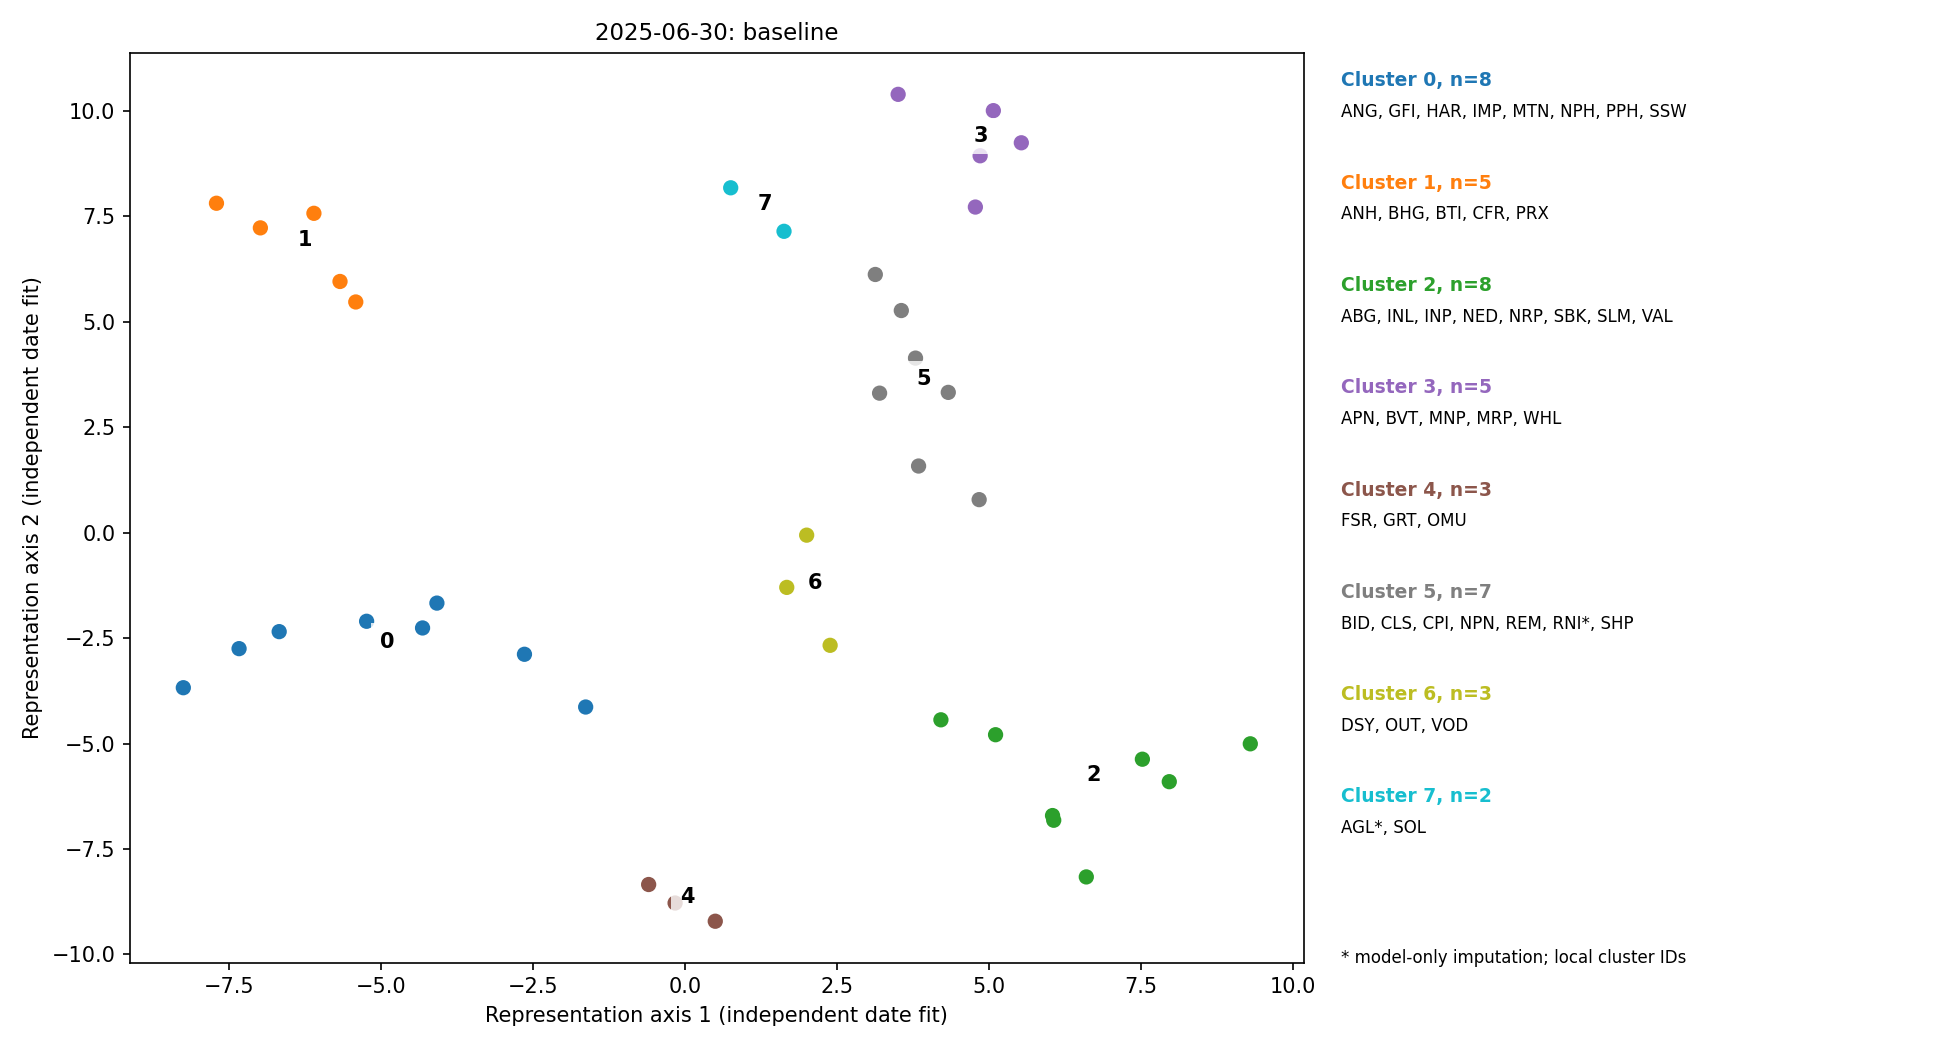

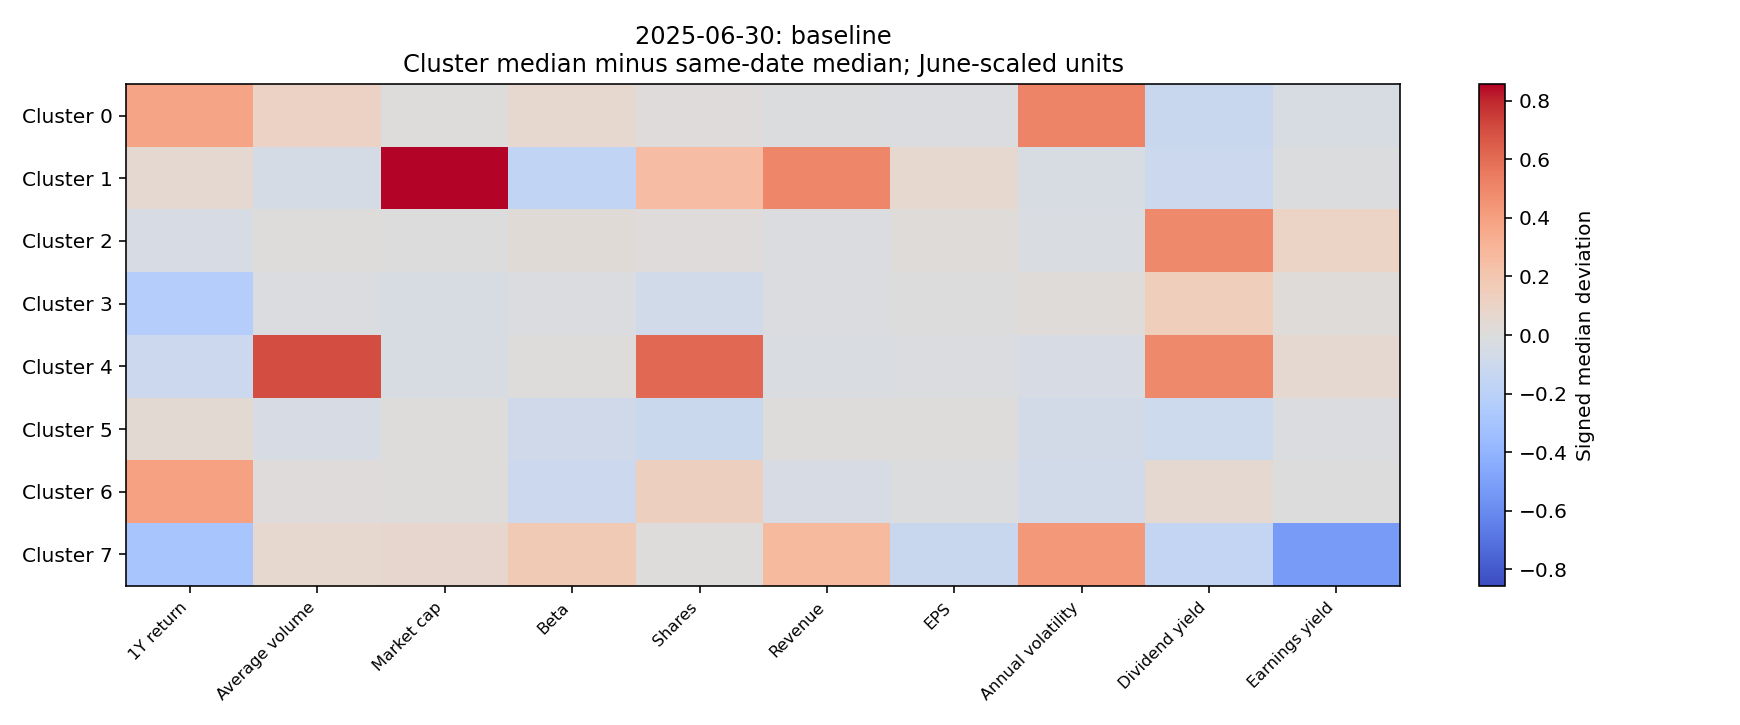

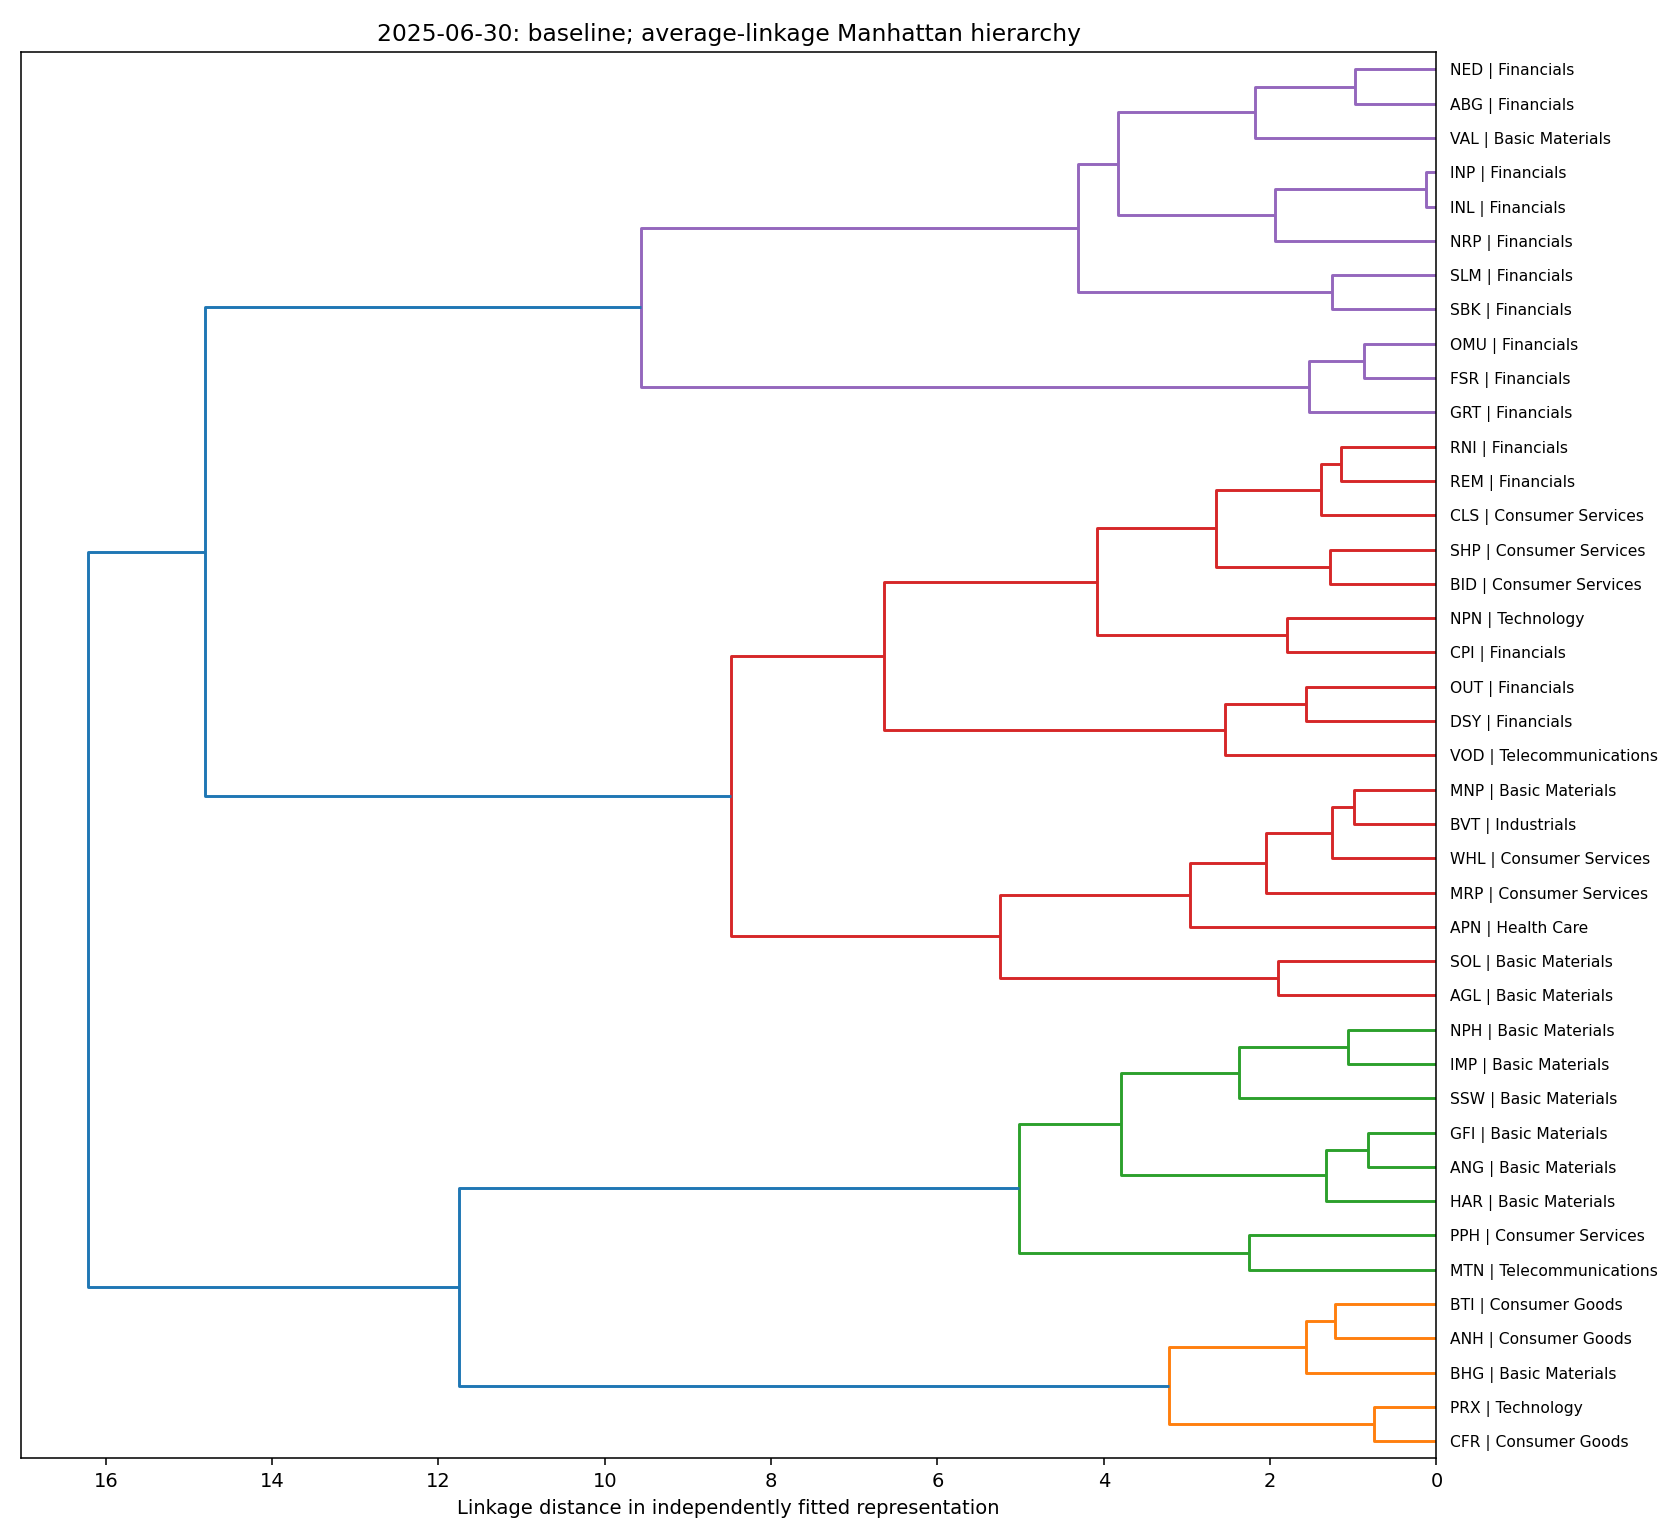

**2025-12-31**

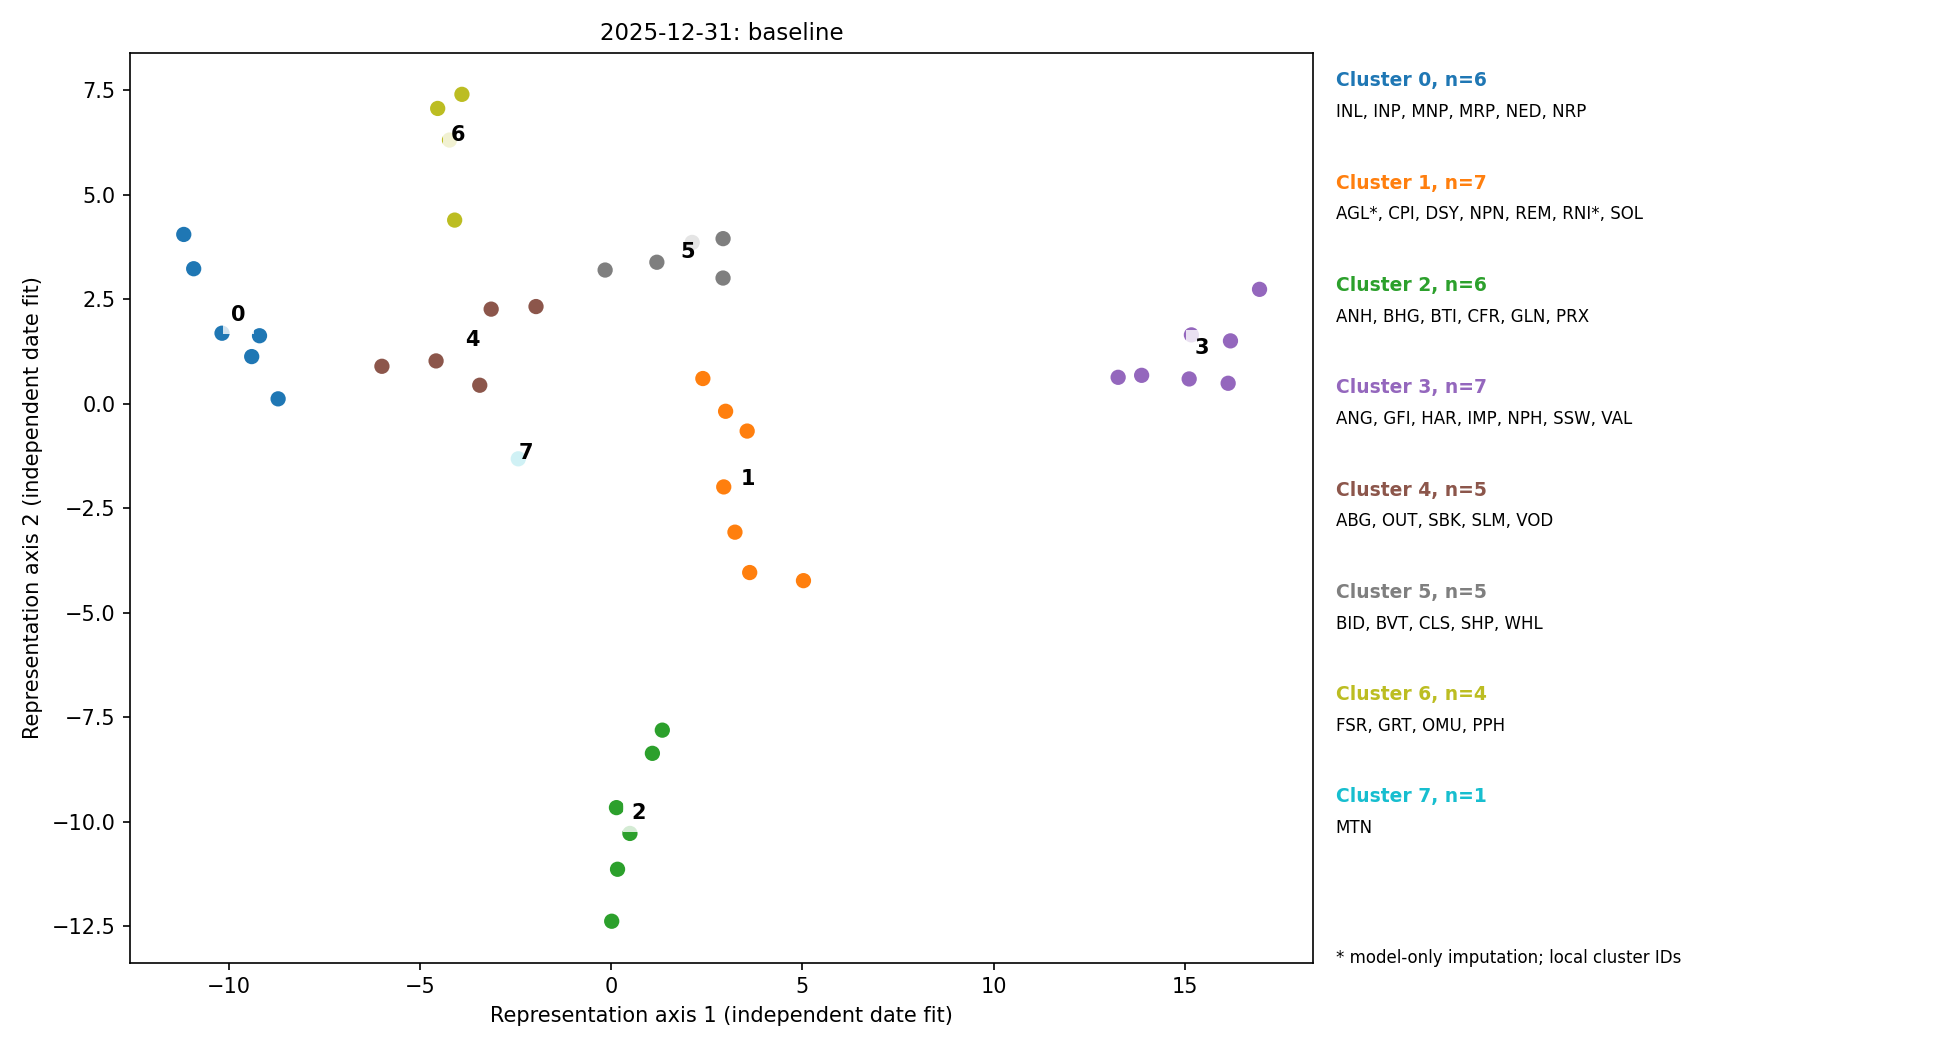

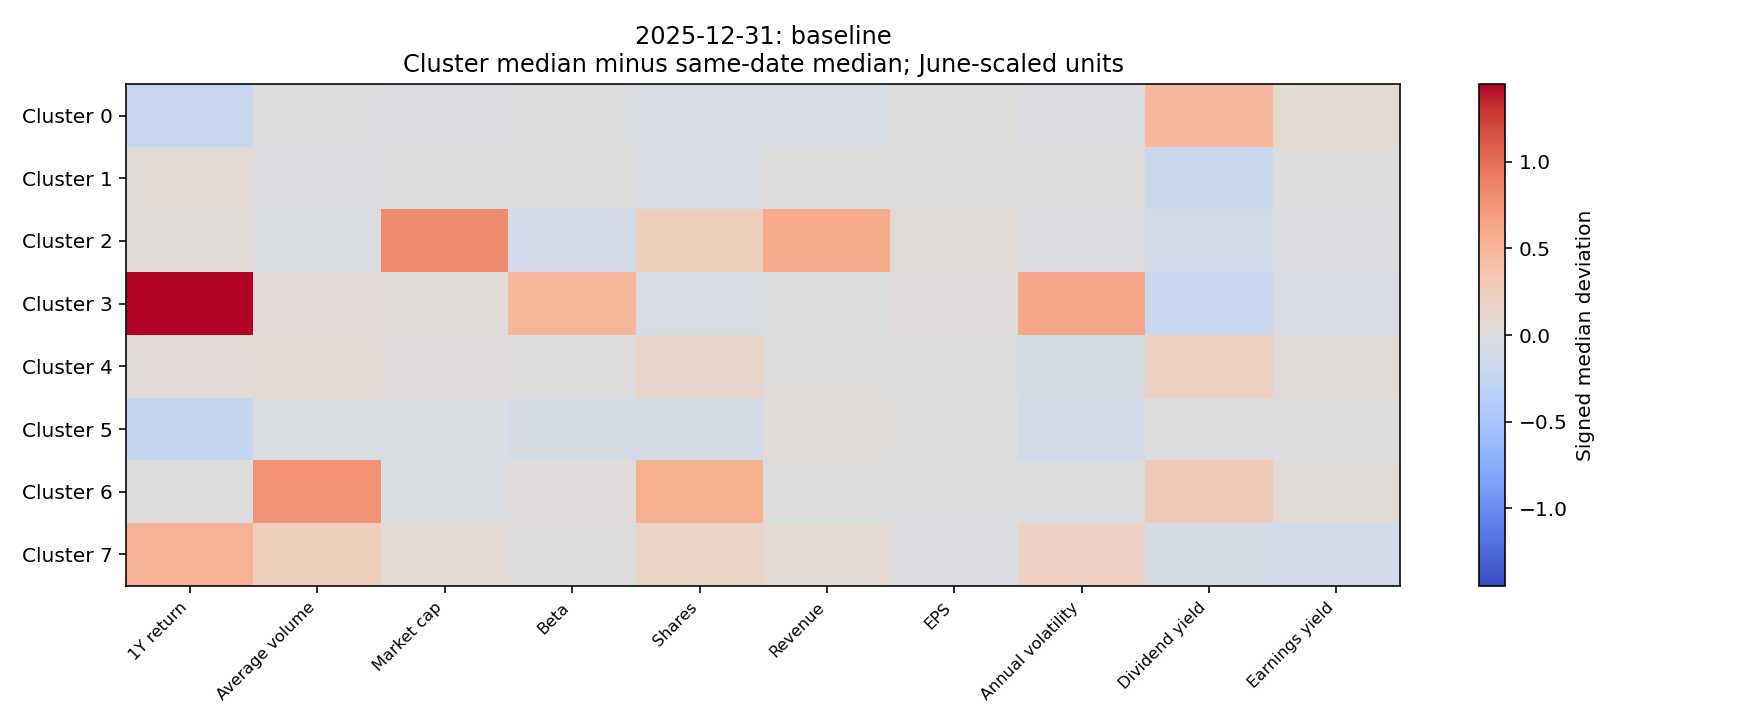

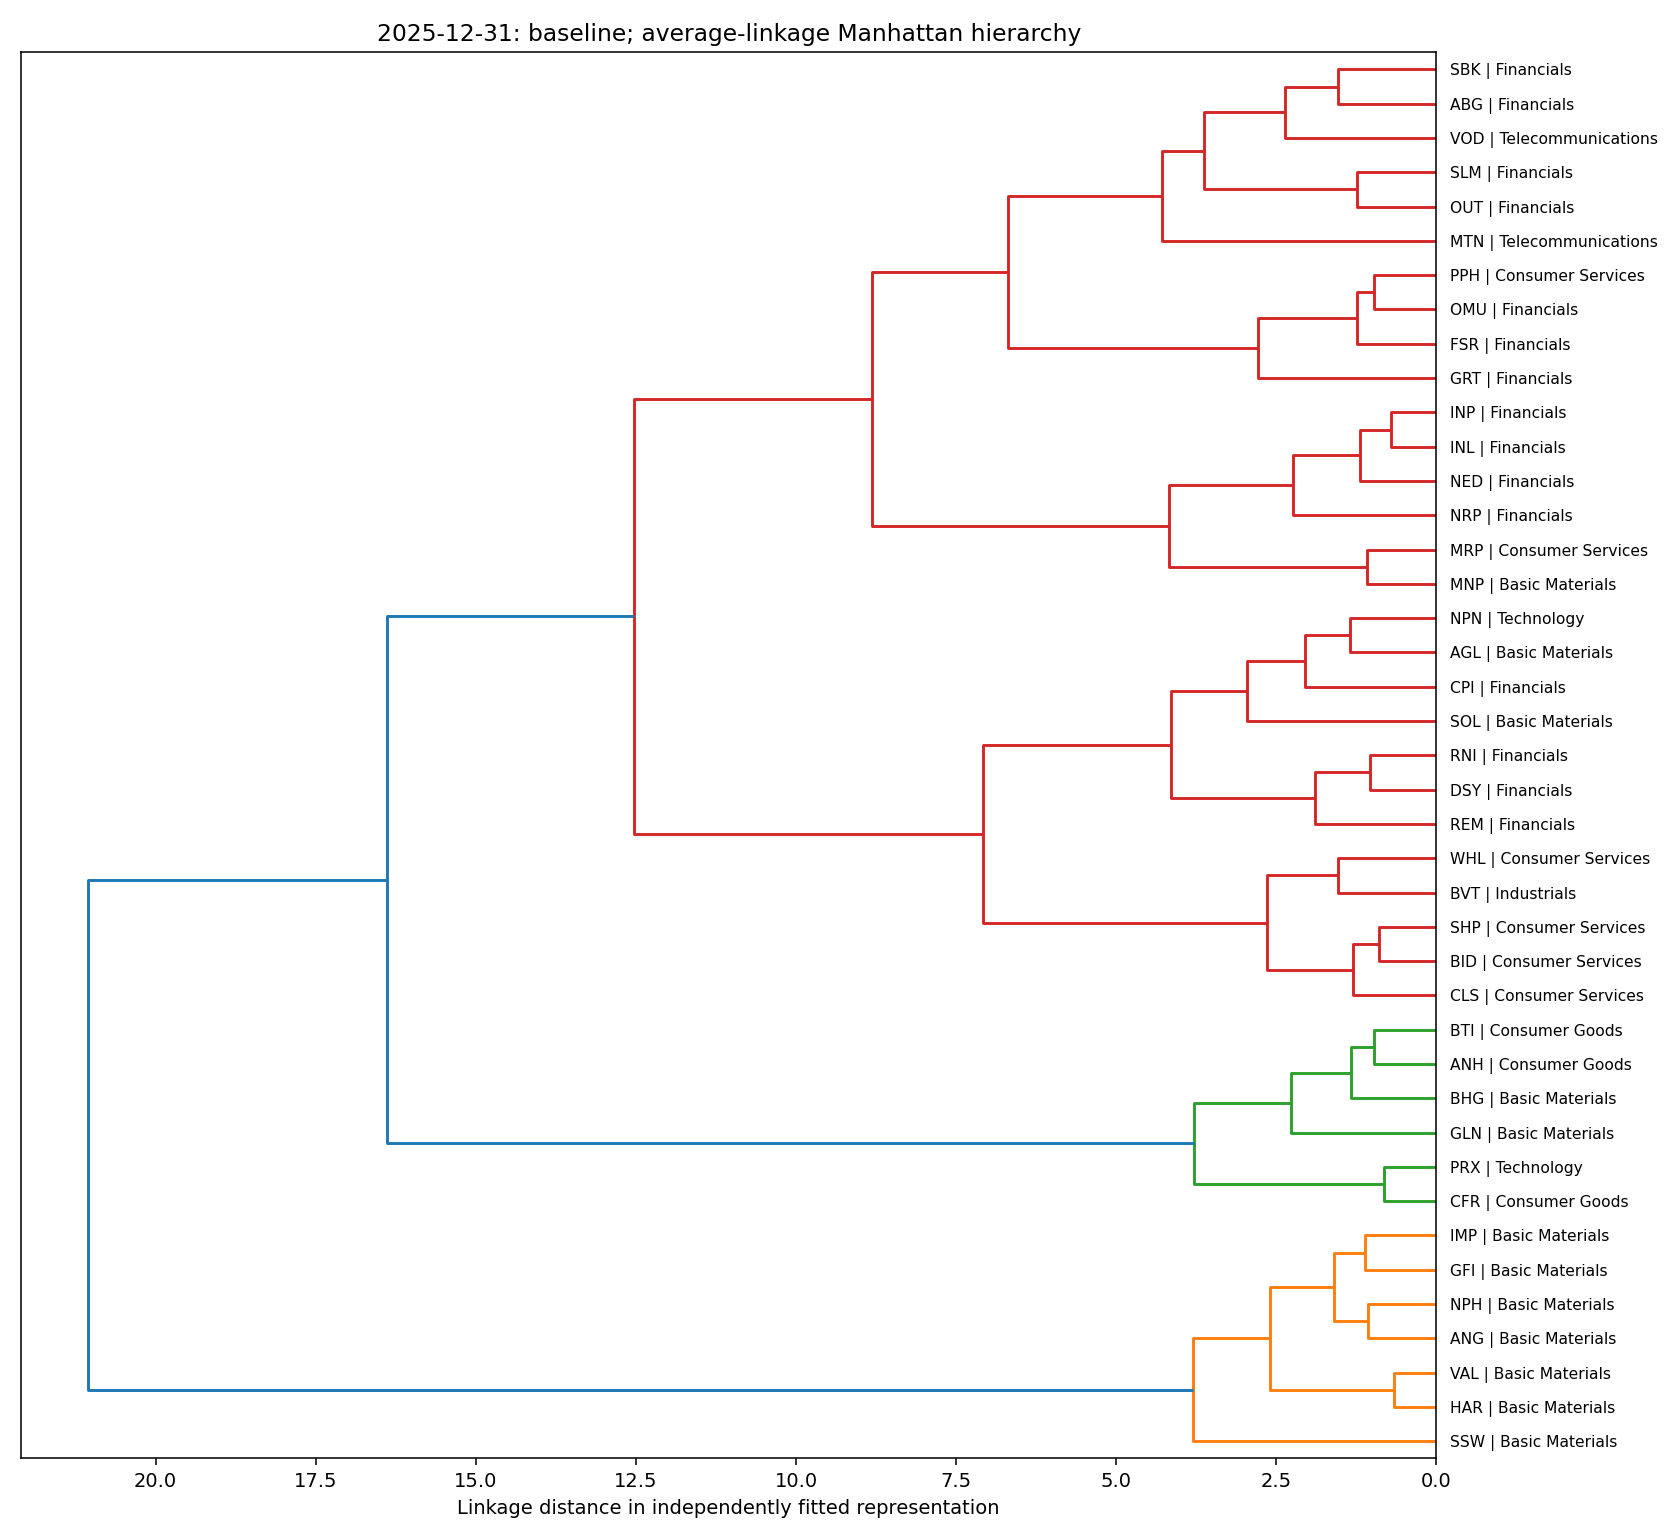

**2026-06-30**

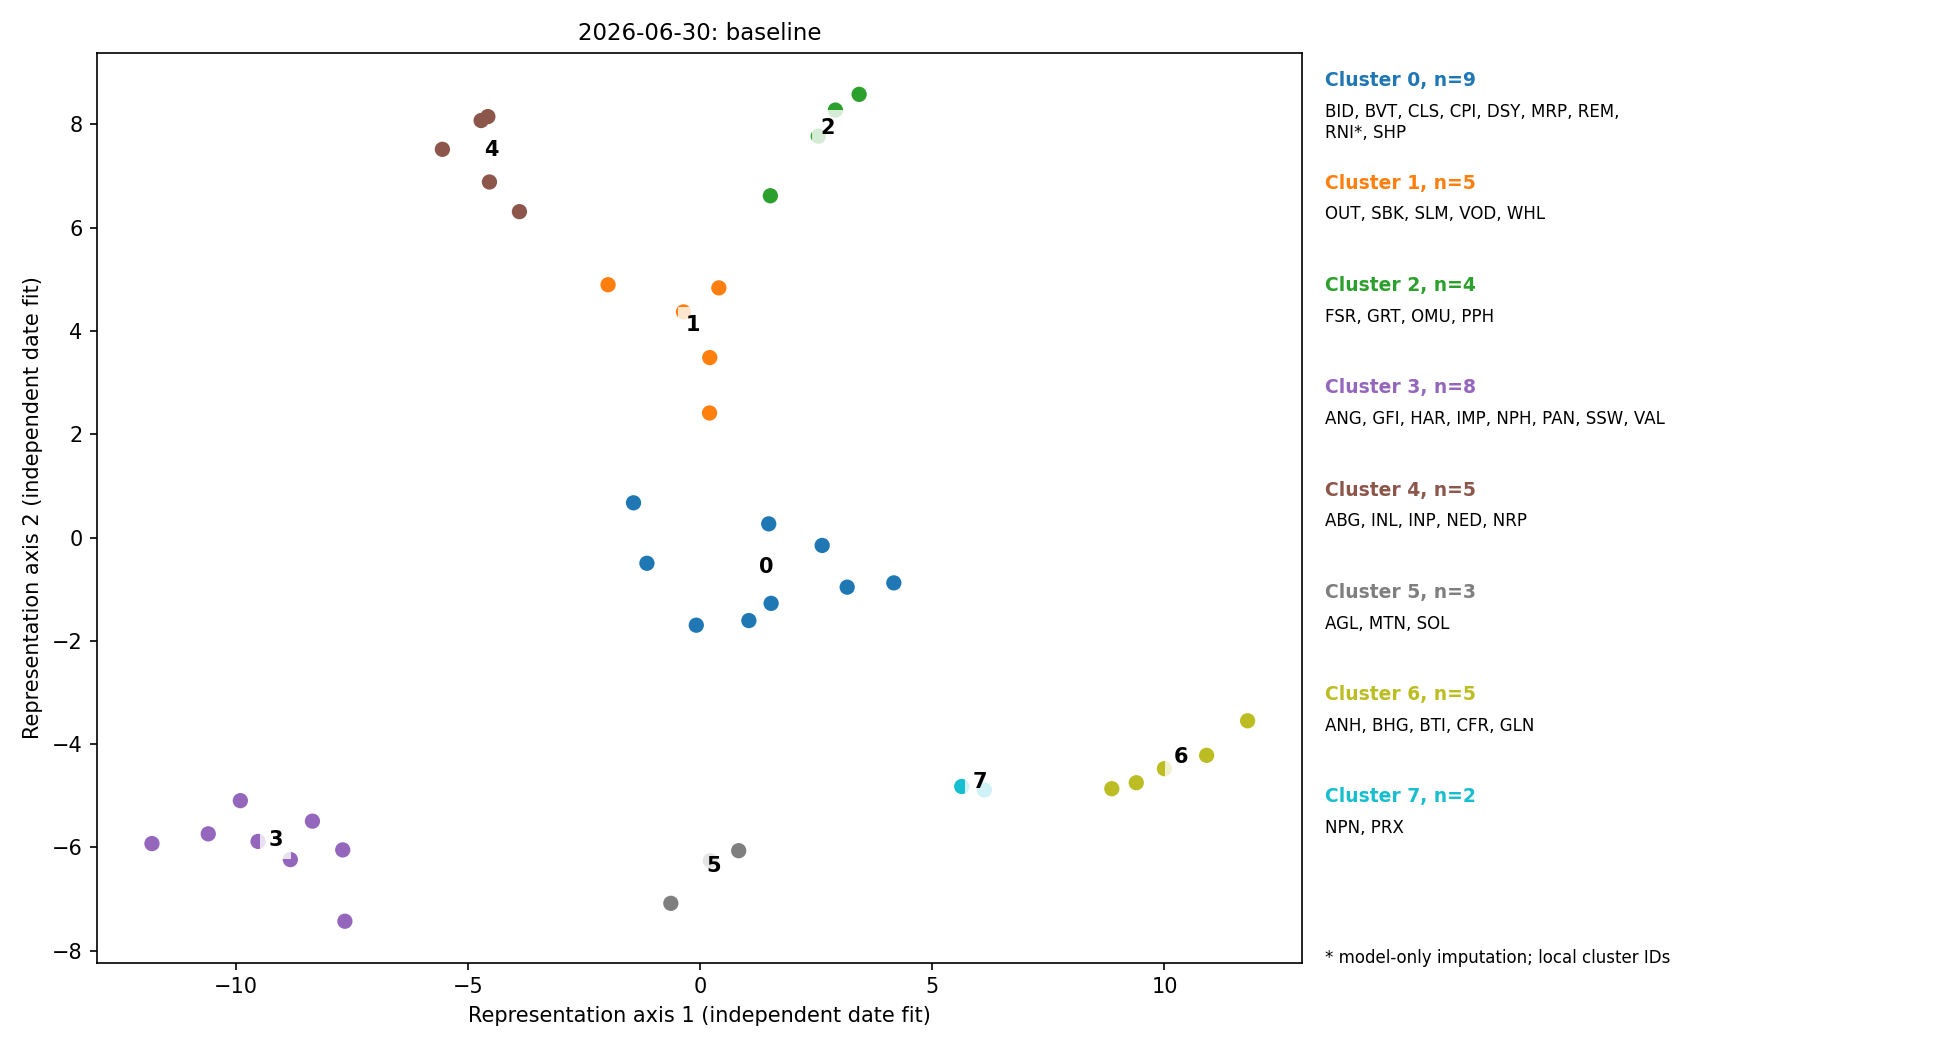

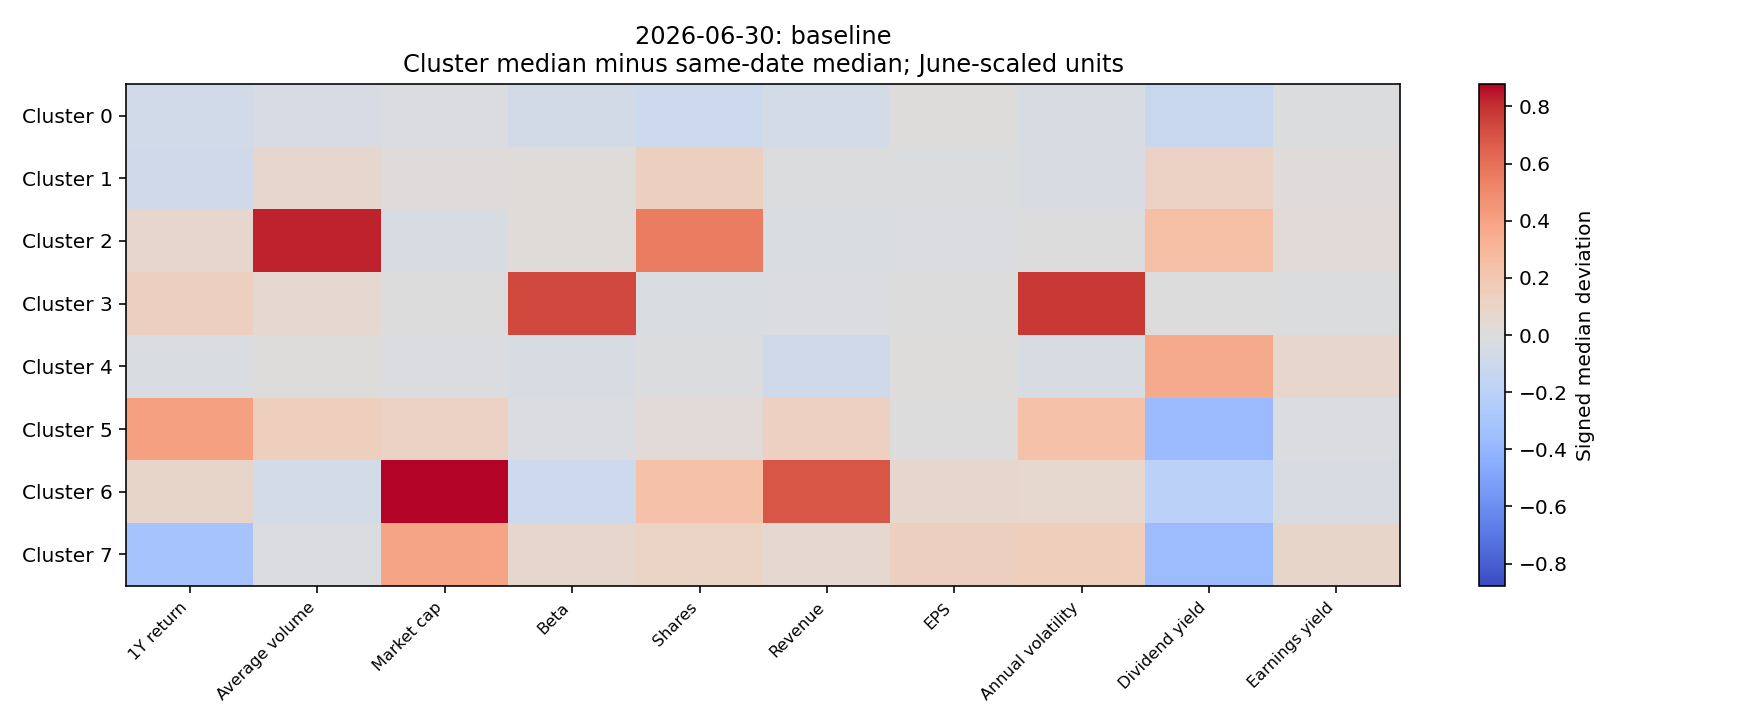

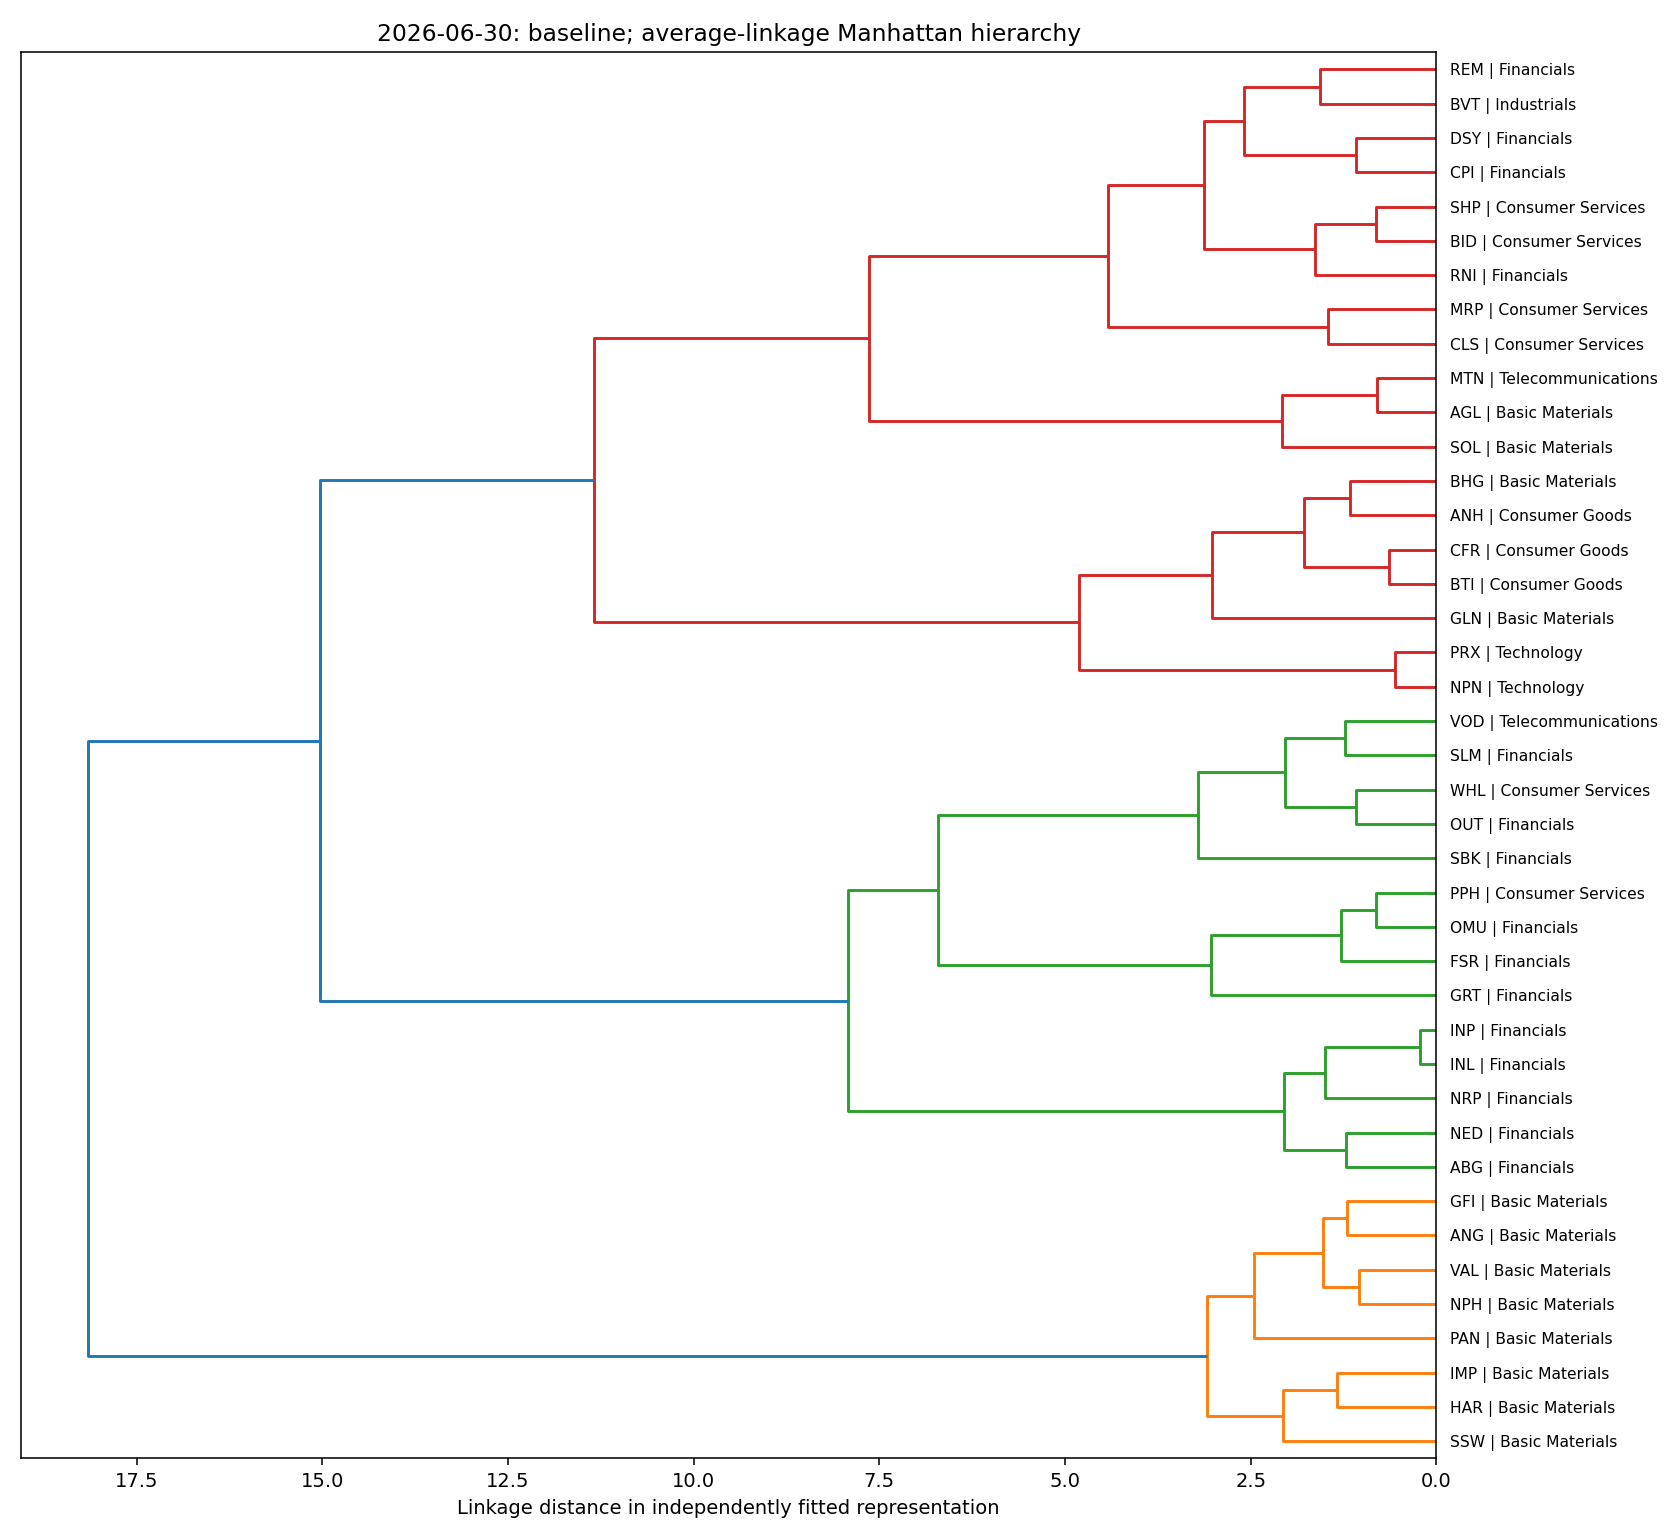

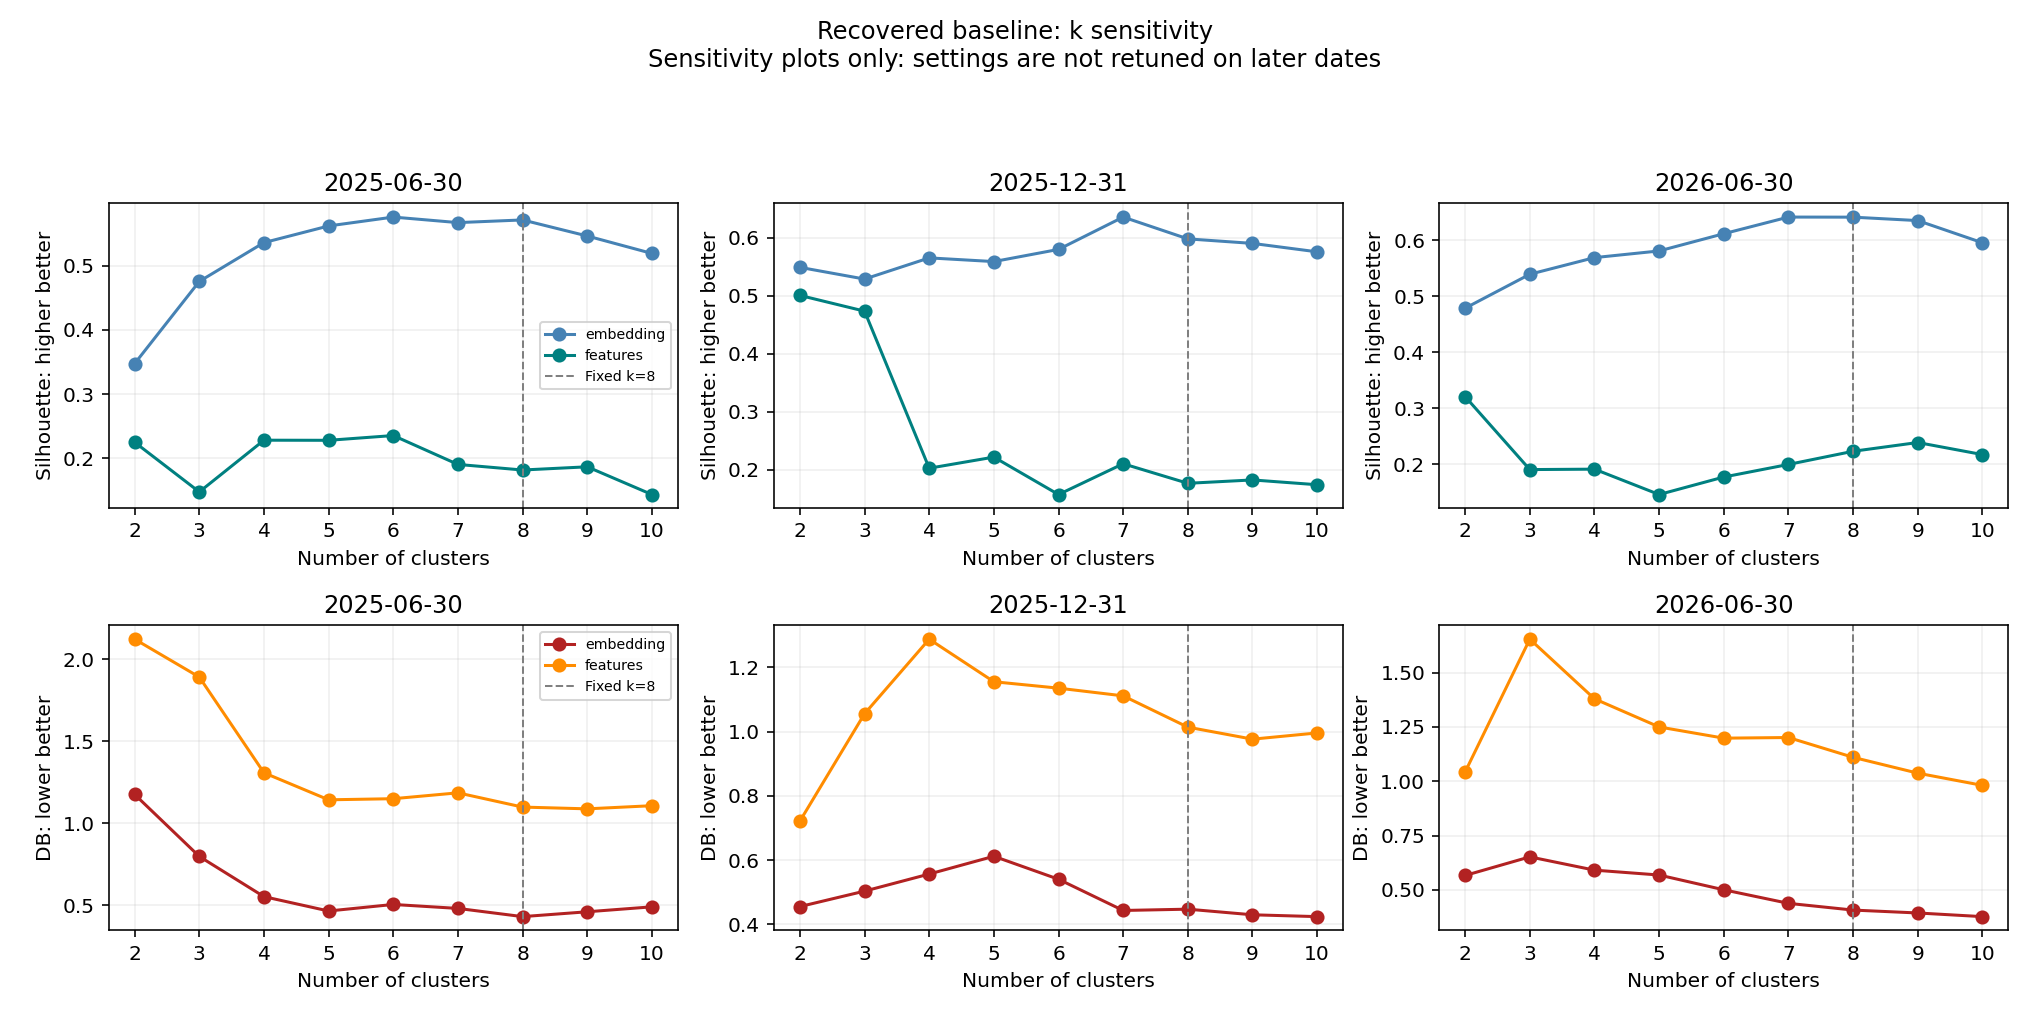

### umap_sensitivity: saved maps, profiles and trees

**2025-06-30**

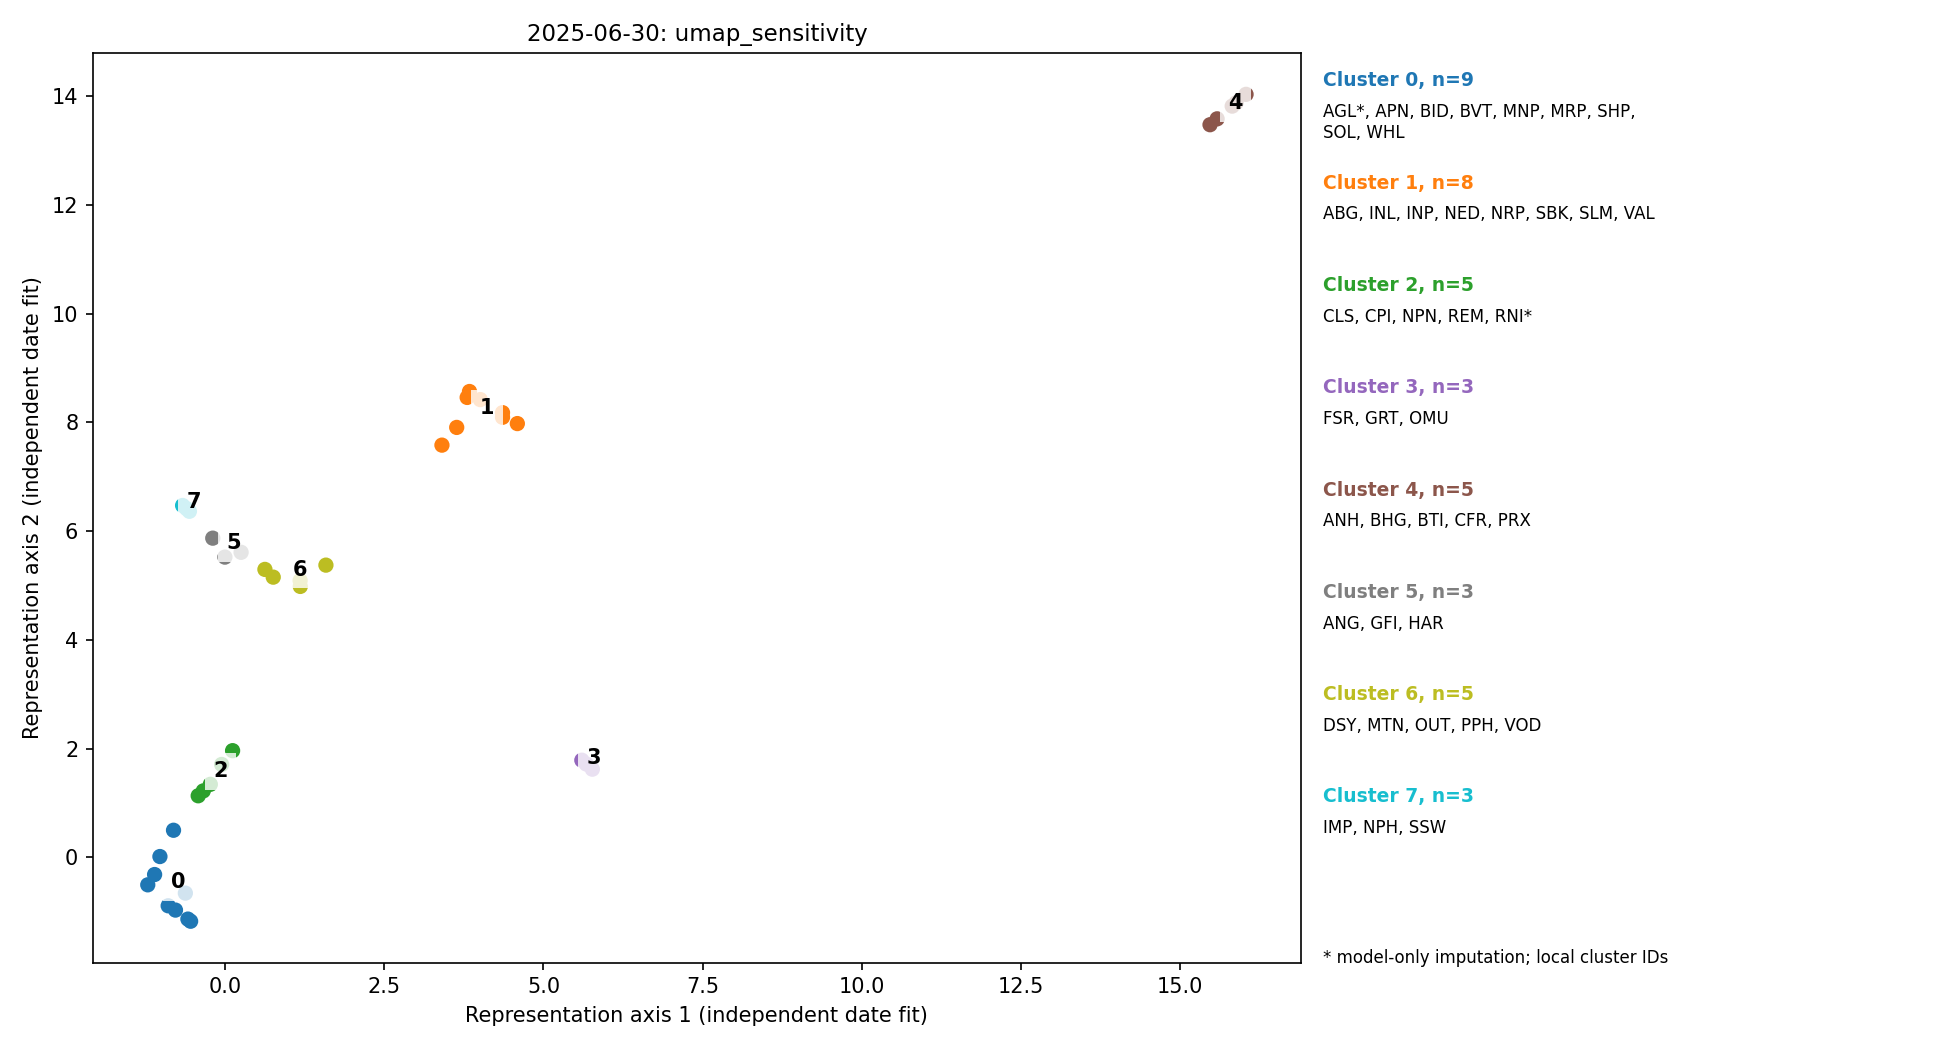

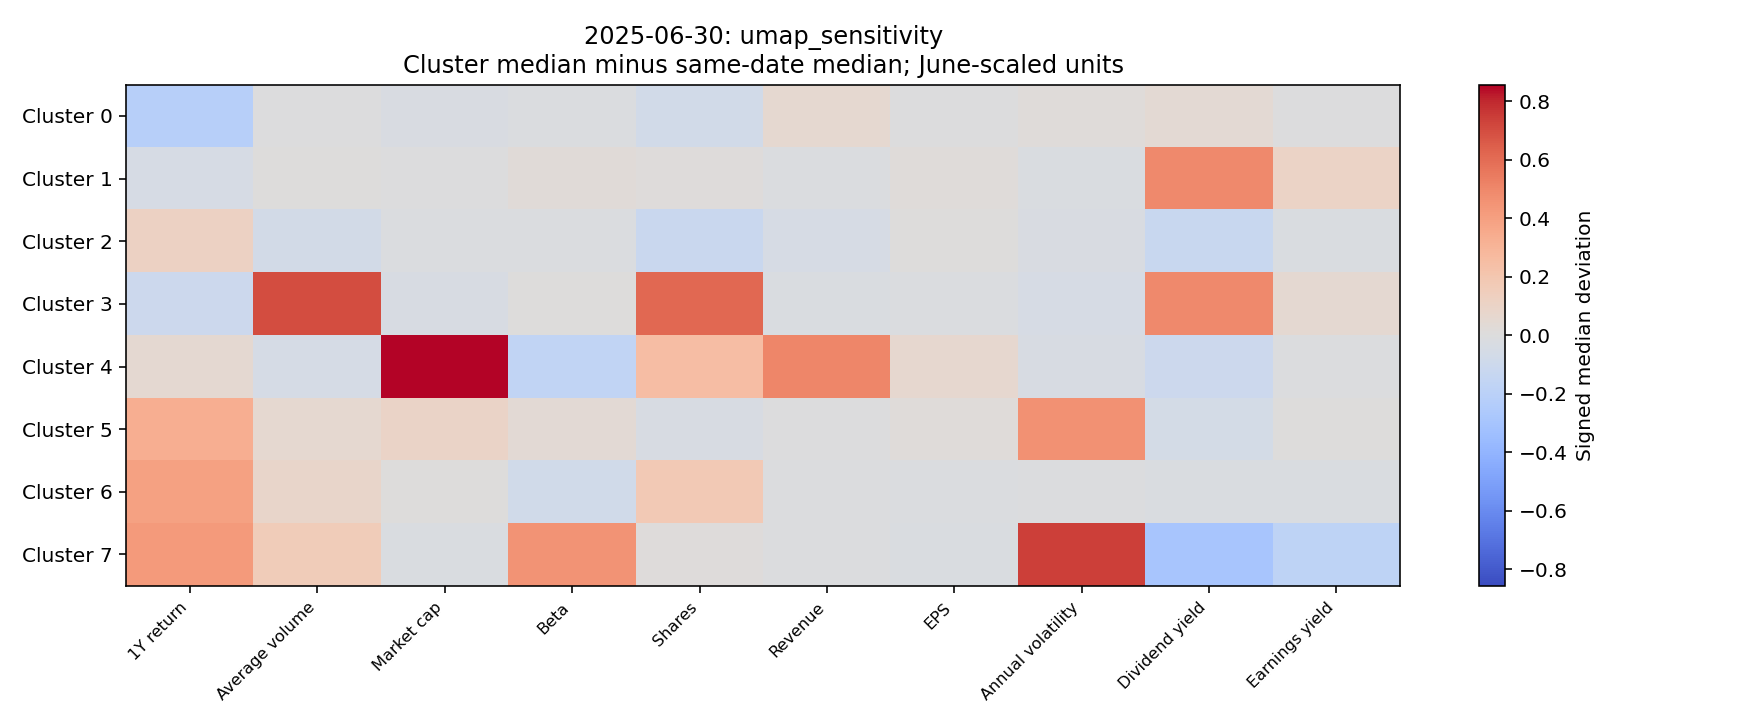

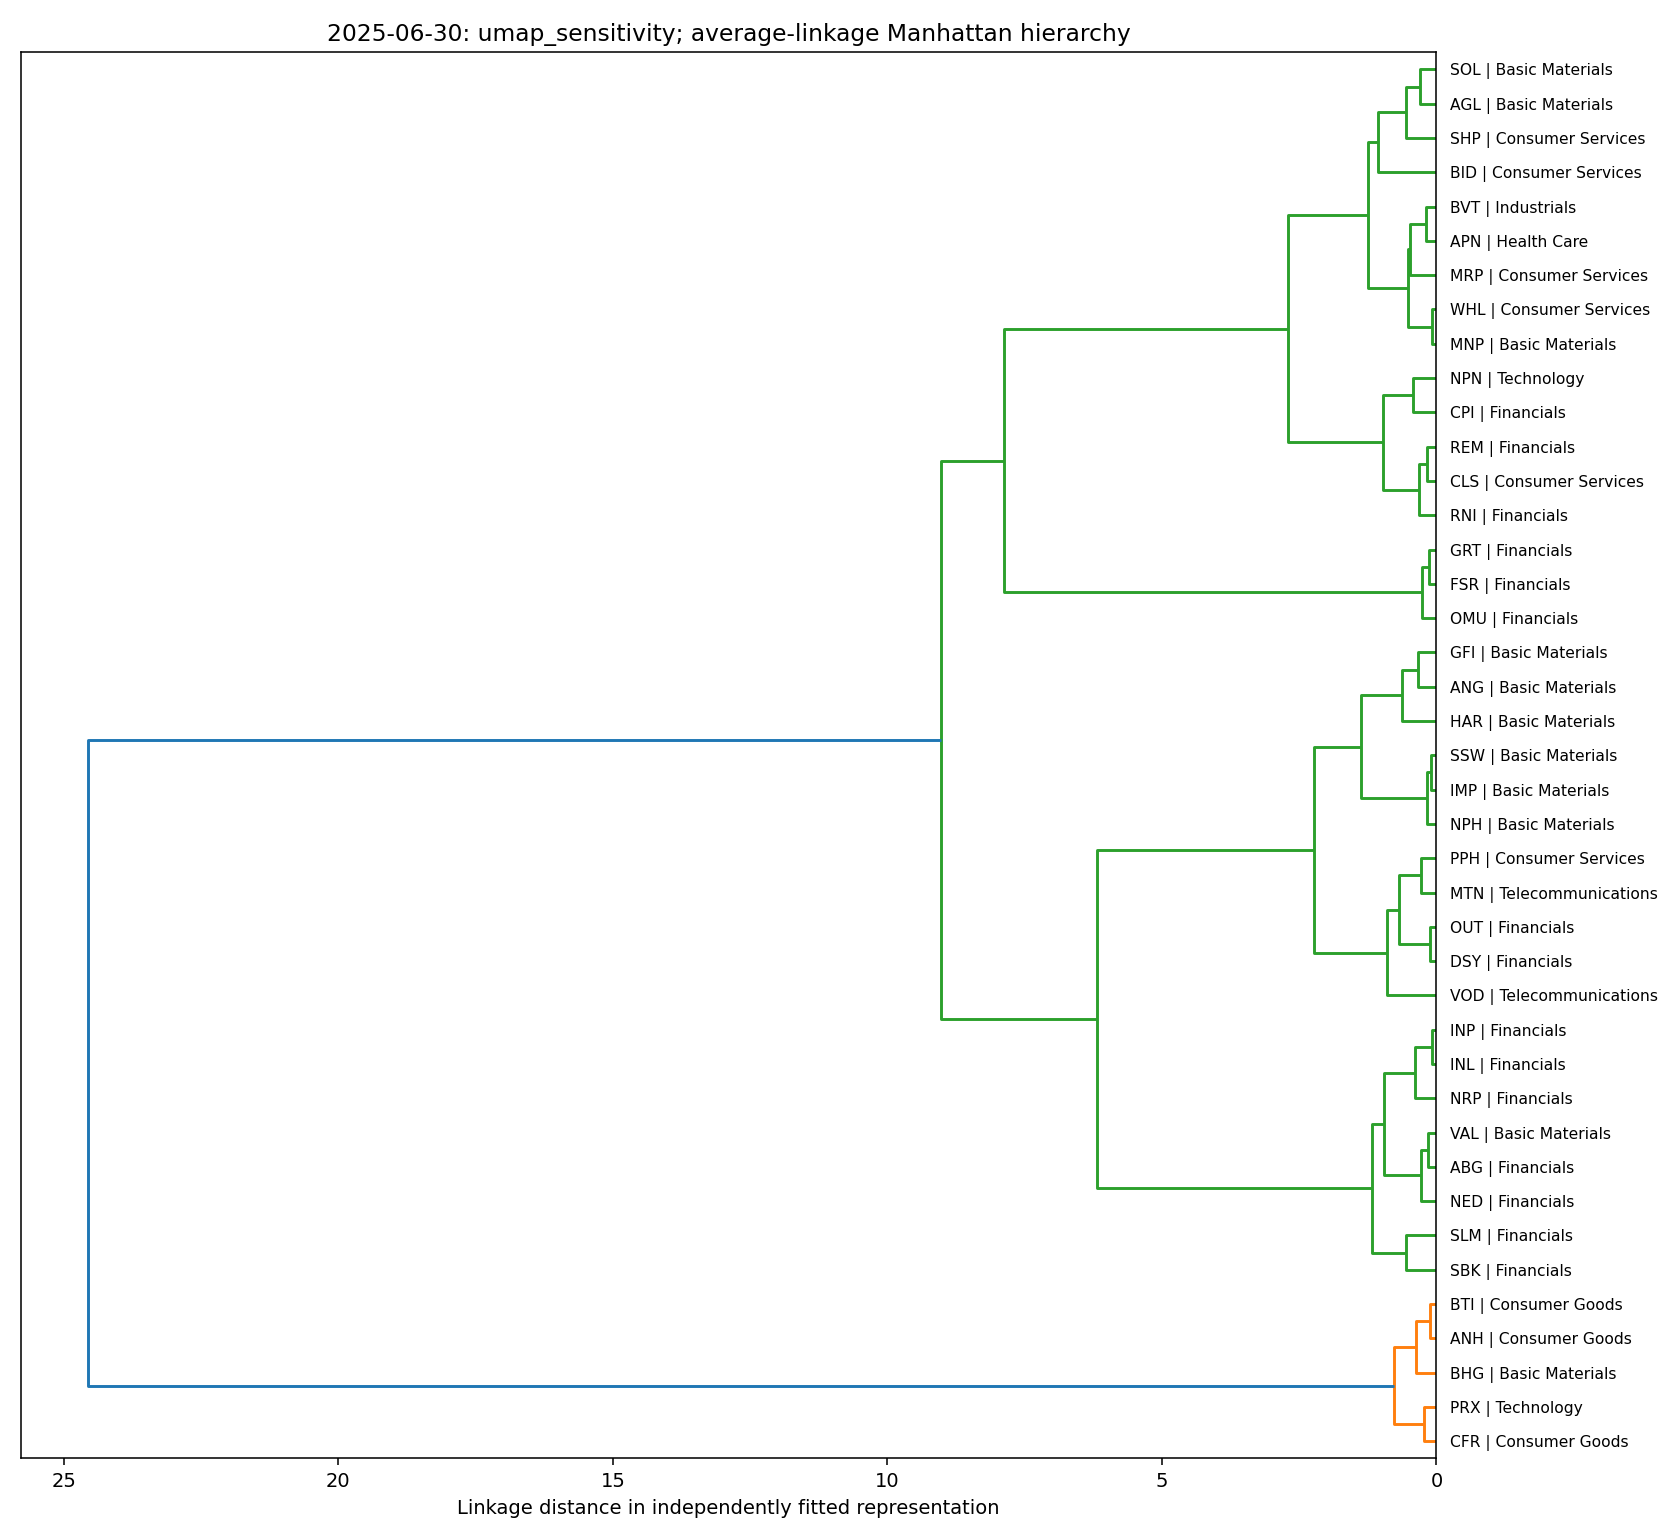

**2025-12-31**

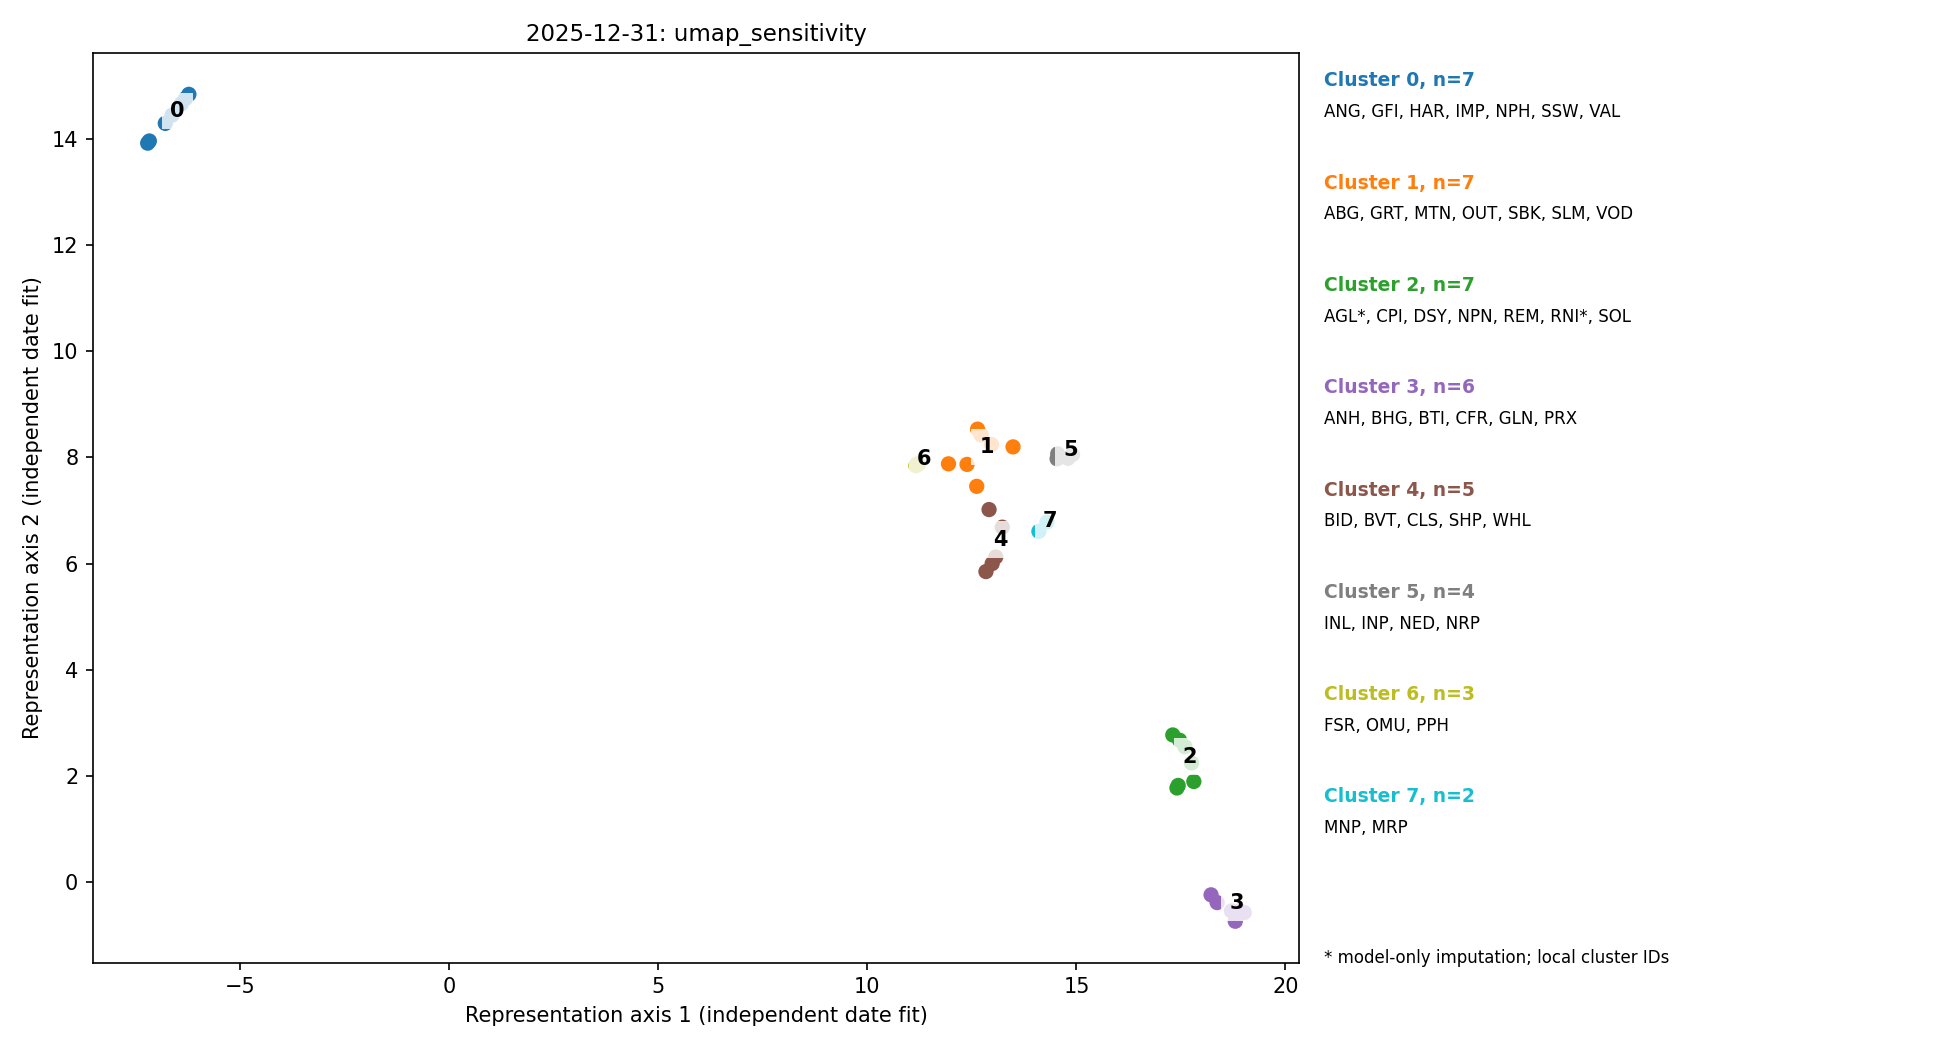

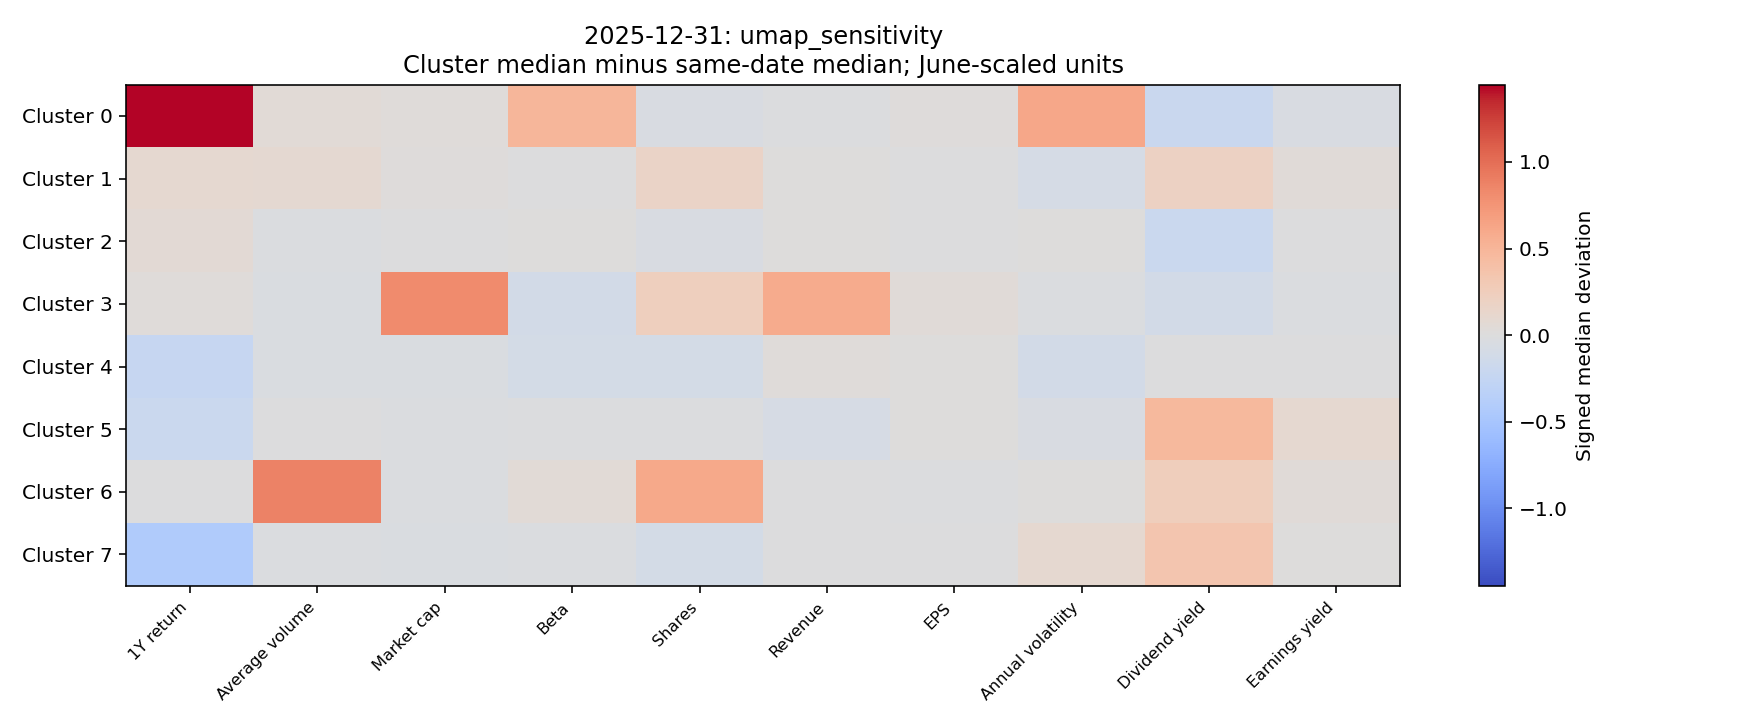

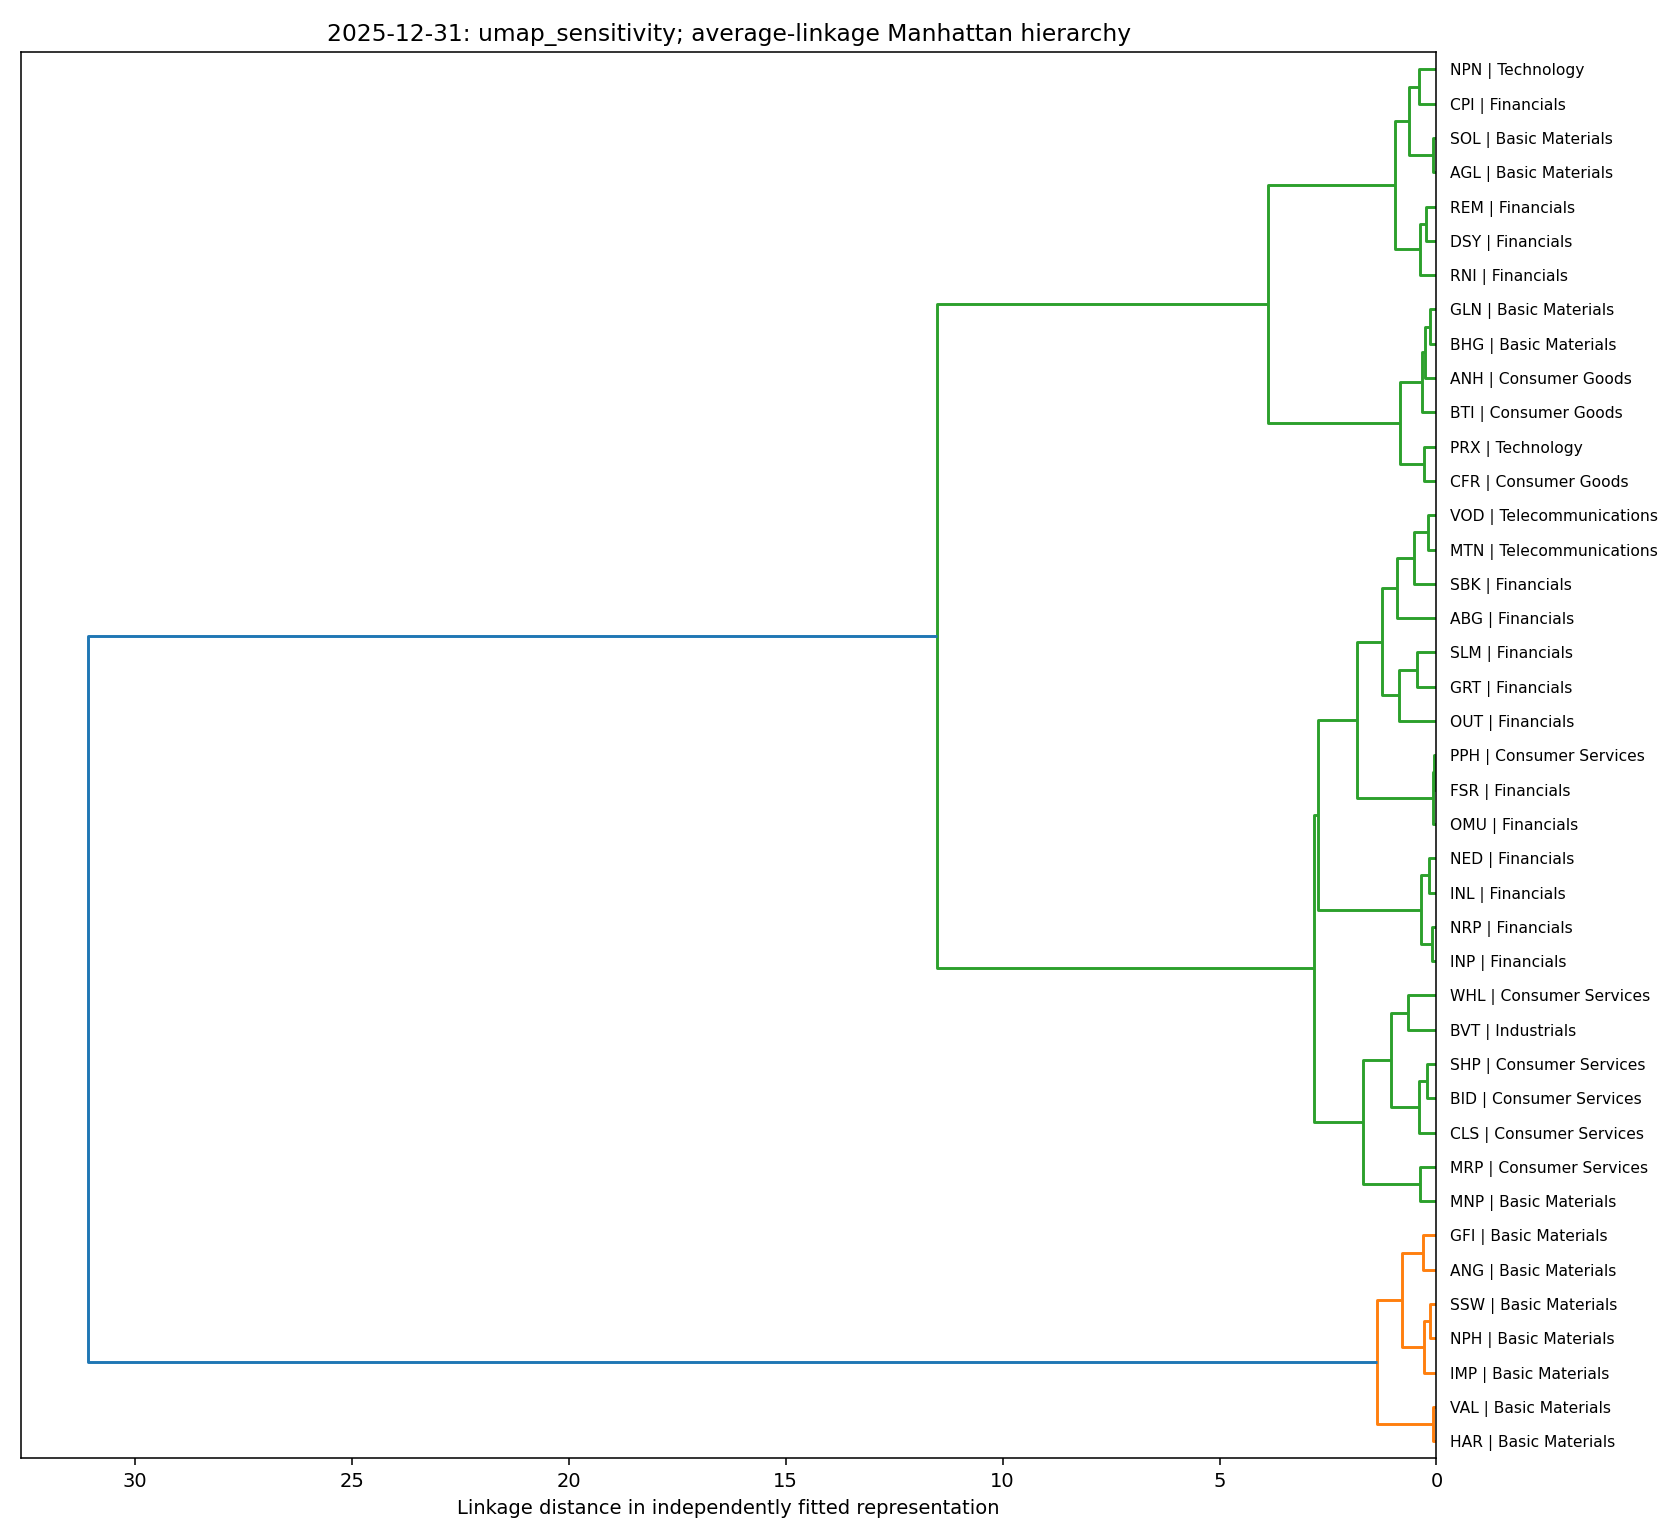

**2026-06-30**

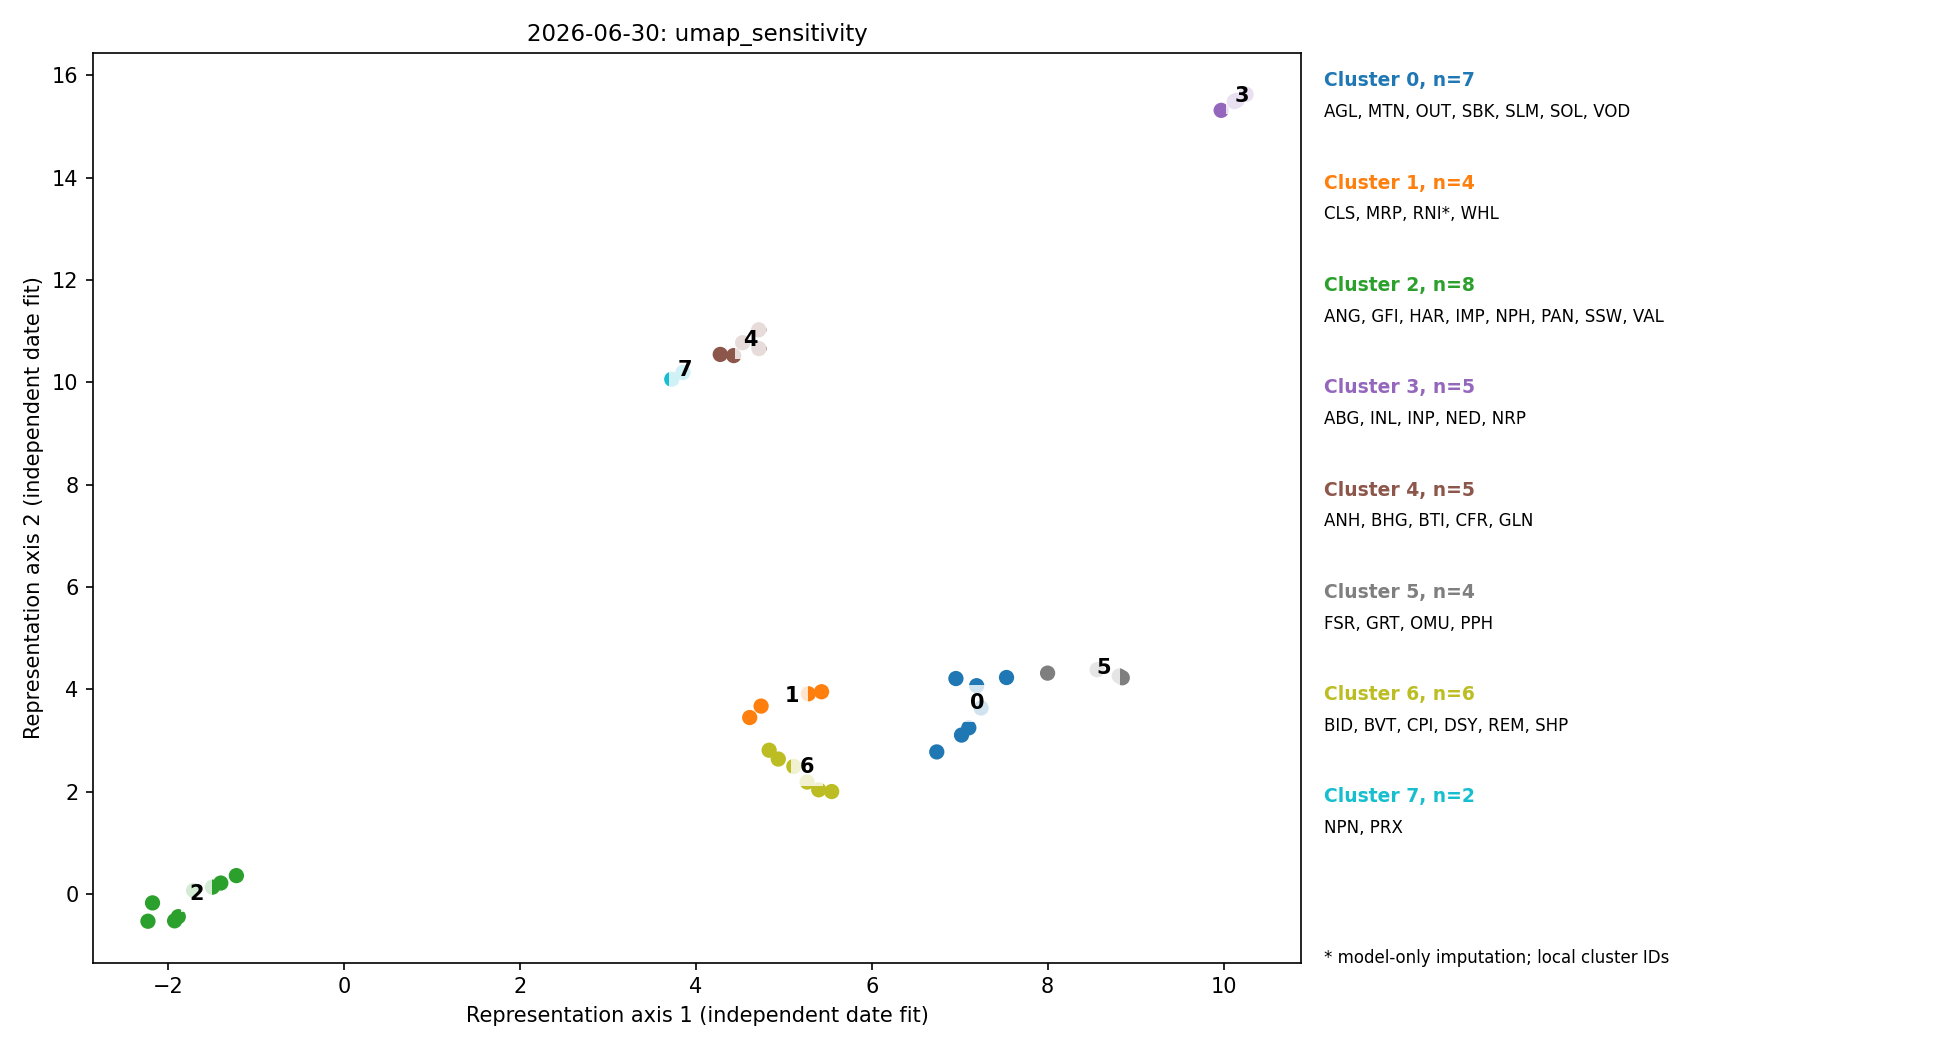

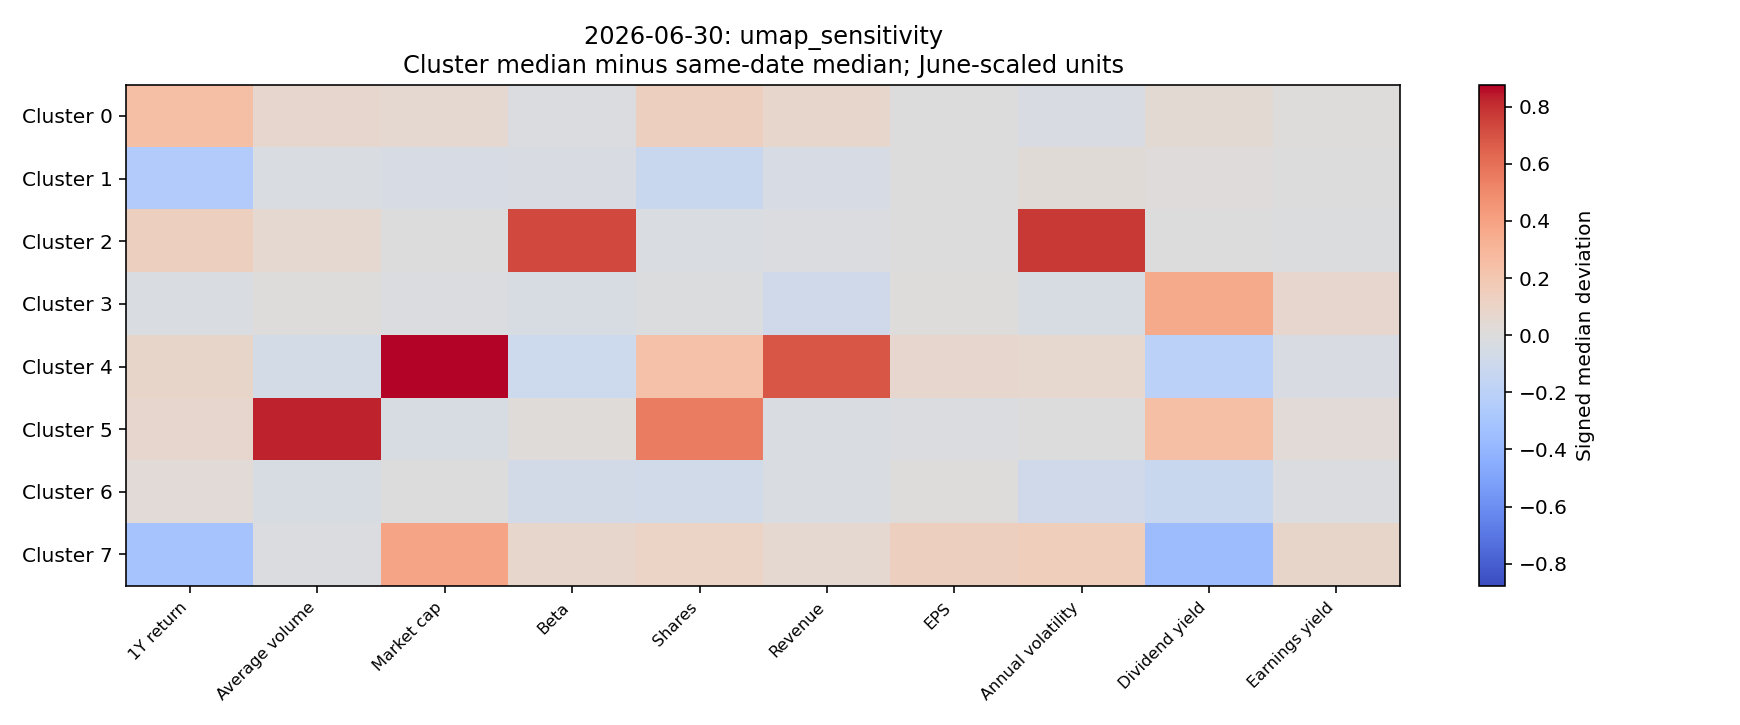

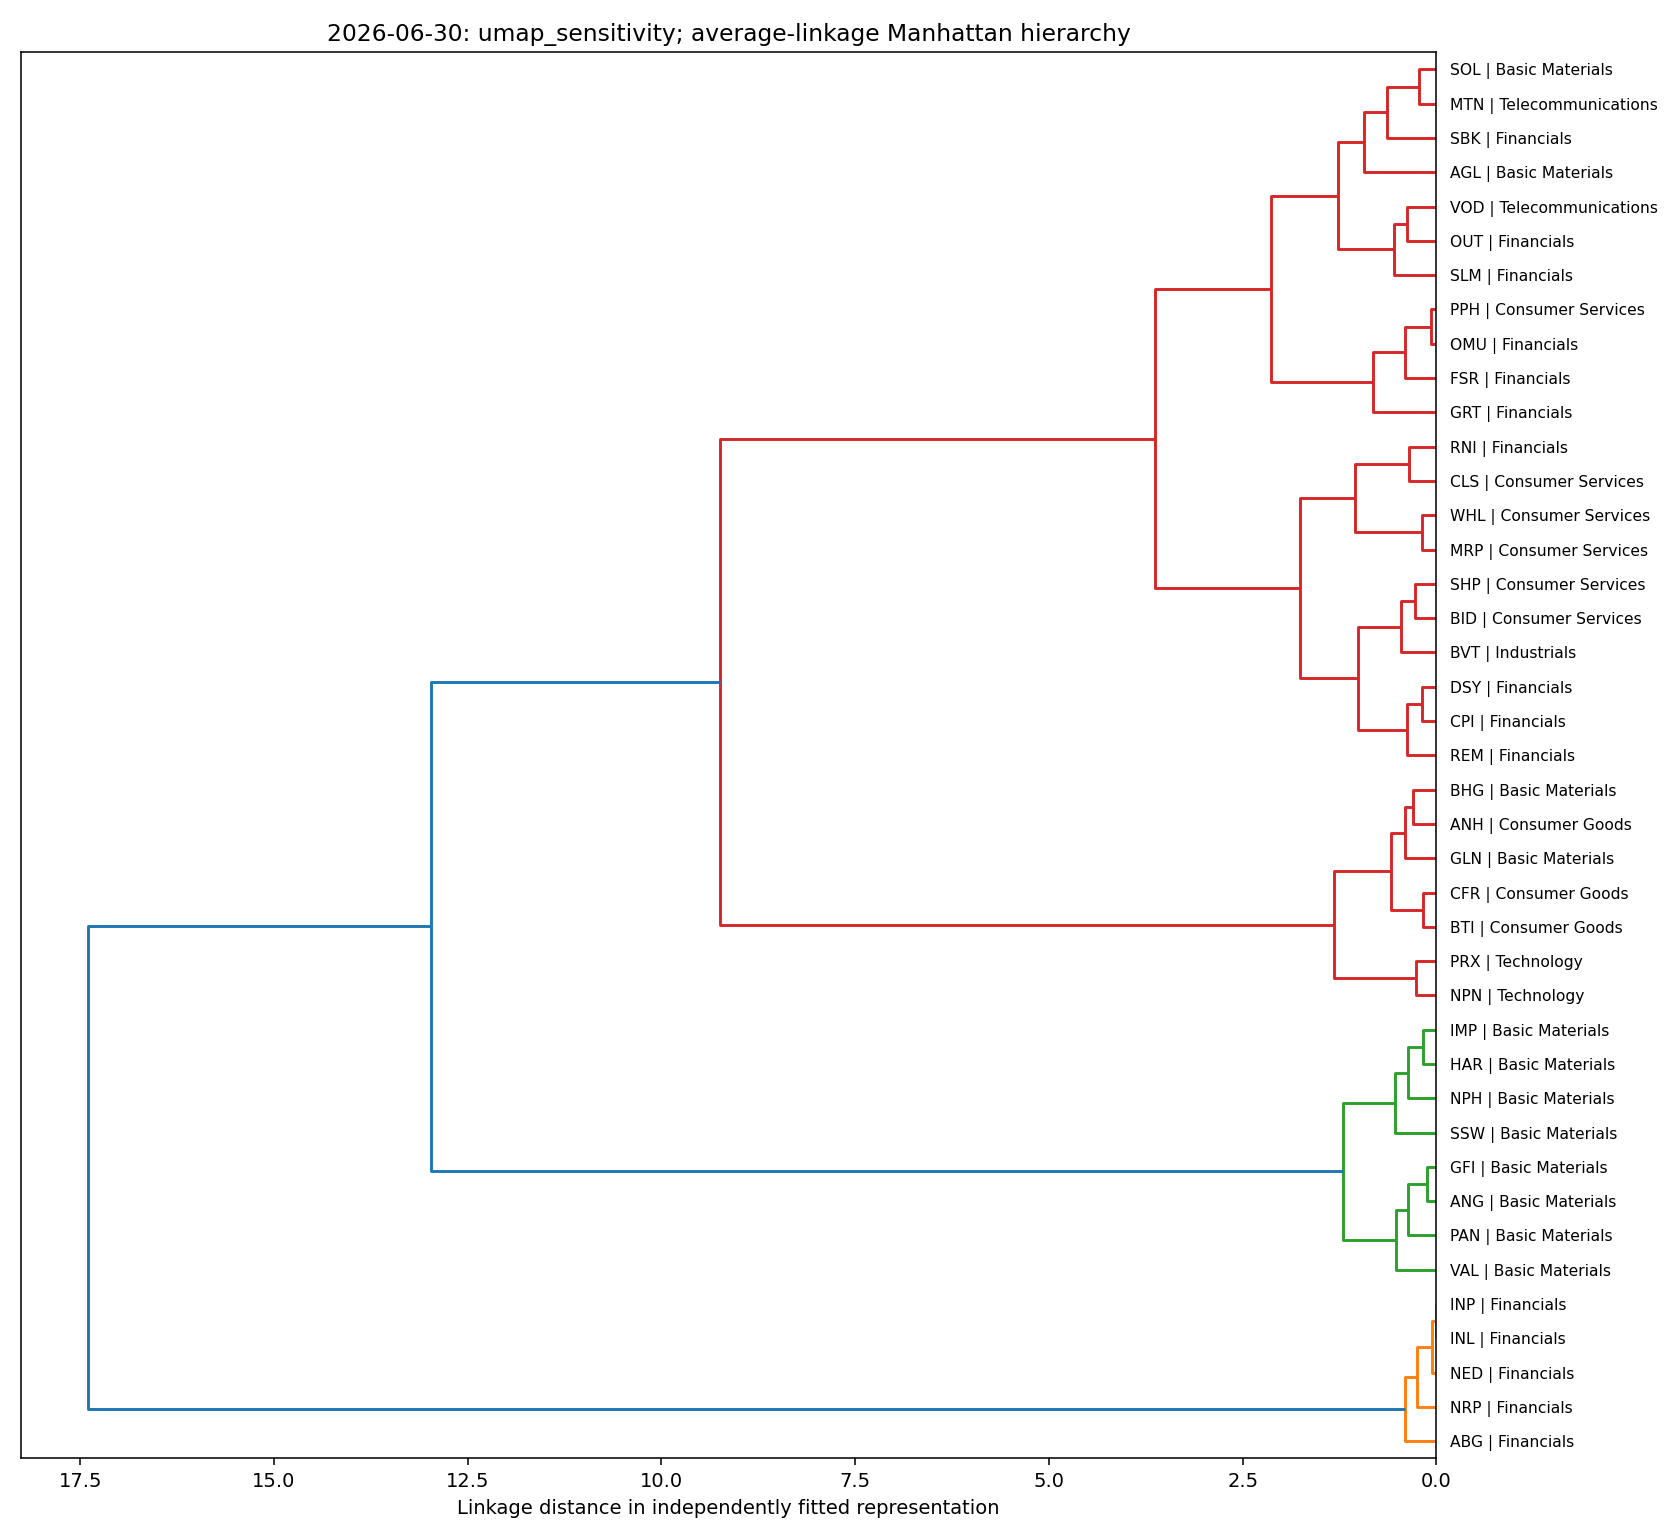

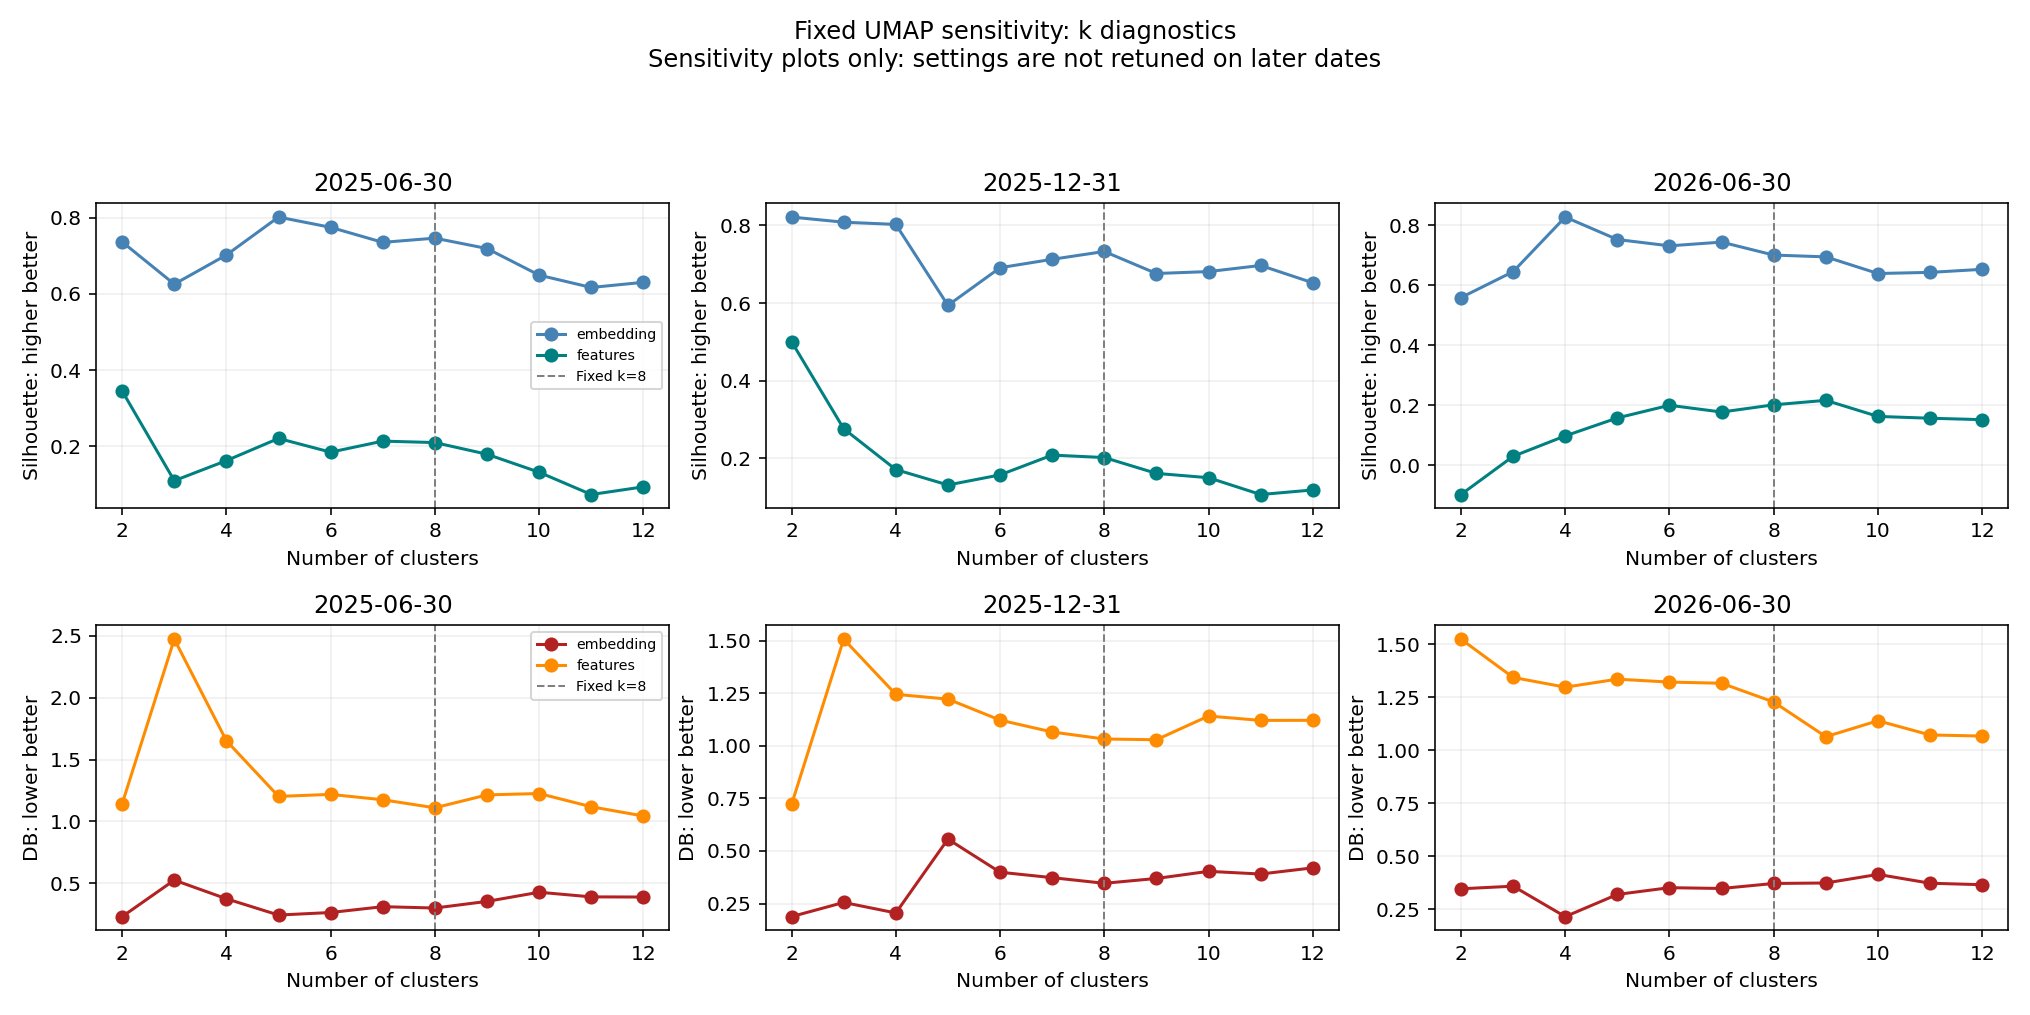

In [5]:
display(pd.read_csv(SOURCE / "primary_model_summary.csv").round(4))
display(pd.read_csv(SOURCE / "model_comparison.csv").round(4))
display(pd.read_csv(SOURCE / "seed_stability.csv").groupby(["study_model", "decision_date"])
        .agg(mean_ari=("ari", "mean"), min_ari=("ari", "min"), mean_nmi=("nmi", "mean")).round(4))
for name, folder in MODELS.items():
    display(Markdown(f"### {name}: saved maps, profiles and trees"))
    for date in DATES:
        display(Markdown(f"**{date}**"))
        for figure in ["cluster_map.png", "feature_profile.png", "dendrogram.png"]:
            show(SOURCE / folder / date / figure)
    show(SOURCE / folder / "cluster_count_sensitivity.png")


## SHAP and attribute profiles
These are saved explanations of supervised cluster-membership surrogates. OOF fidelity is not independent validation of clustering; singleton explanations may have no estimable OOF fidelity. They are associations, not causal explanations of movement or investment returns.

,study_model,decision_date,in_sample_accuracy,oof_accuracy,oof_status,minimum_cluster_size,shap_max_additivity_error
0,baseline,2025-06-30,1.0,0.536585,estimated,2,0.000001
1,baseline,2025-12-31,1.0,NaN,not estimable: singleton cluster,1,0.000002
2,baseline,2026-06-30,1.0,0.731707,estimated,2,0.000002
3,umap_sensitivity,2025-06-30,1.0,0.609756,estimated,3,0.000003
4,umap_sensitivity,2025-12-31,1.0,0.634146,estimated,2,0.000002
5,umap_sensitivity,2026-06-30,1.0,0.707317,estimated,2,0.000001


### baseline: saved SHAP

**2025-06-30**

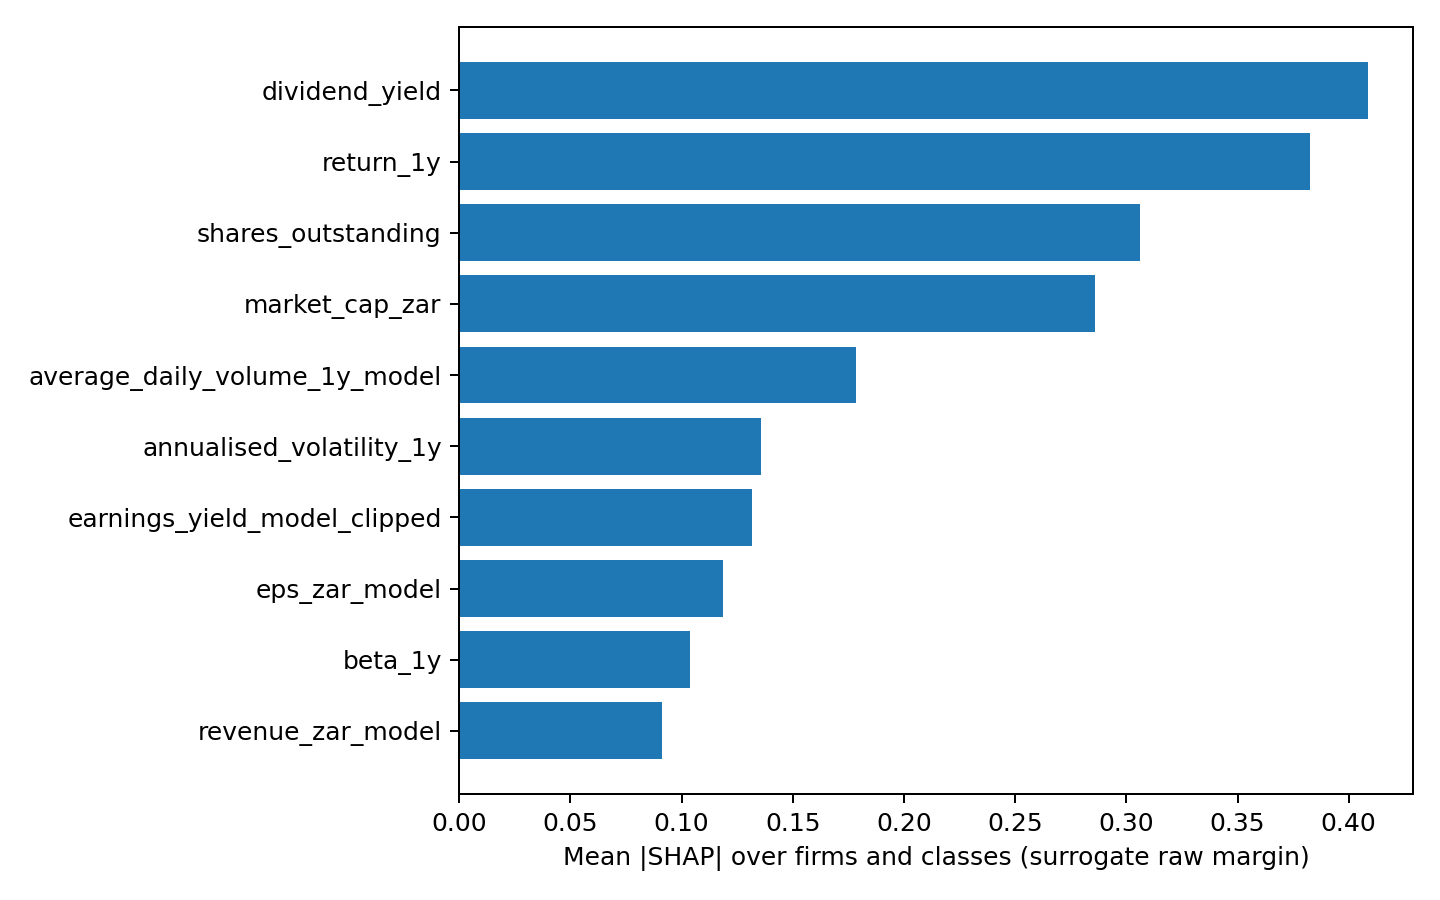

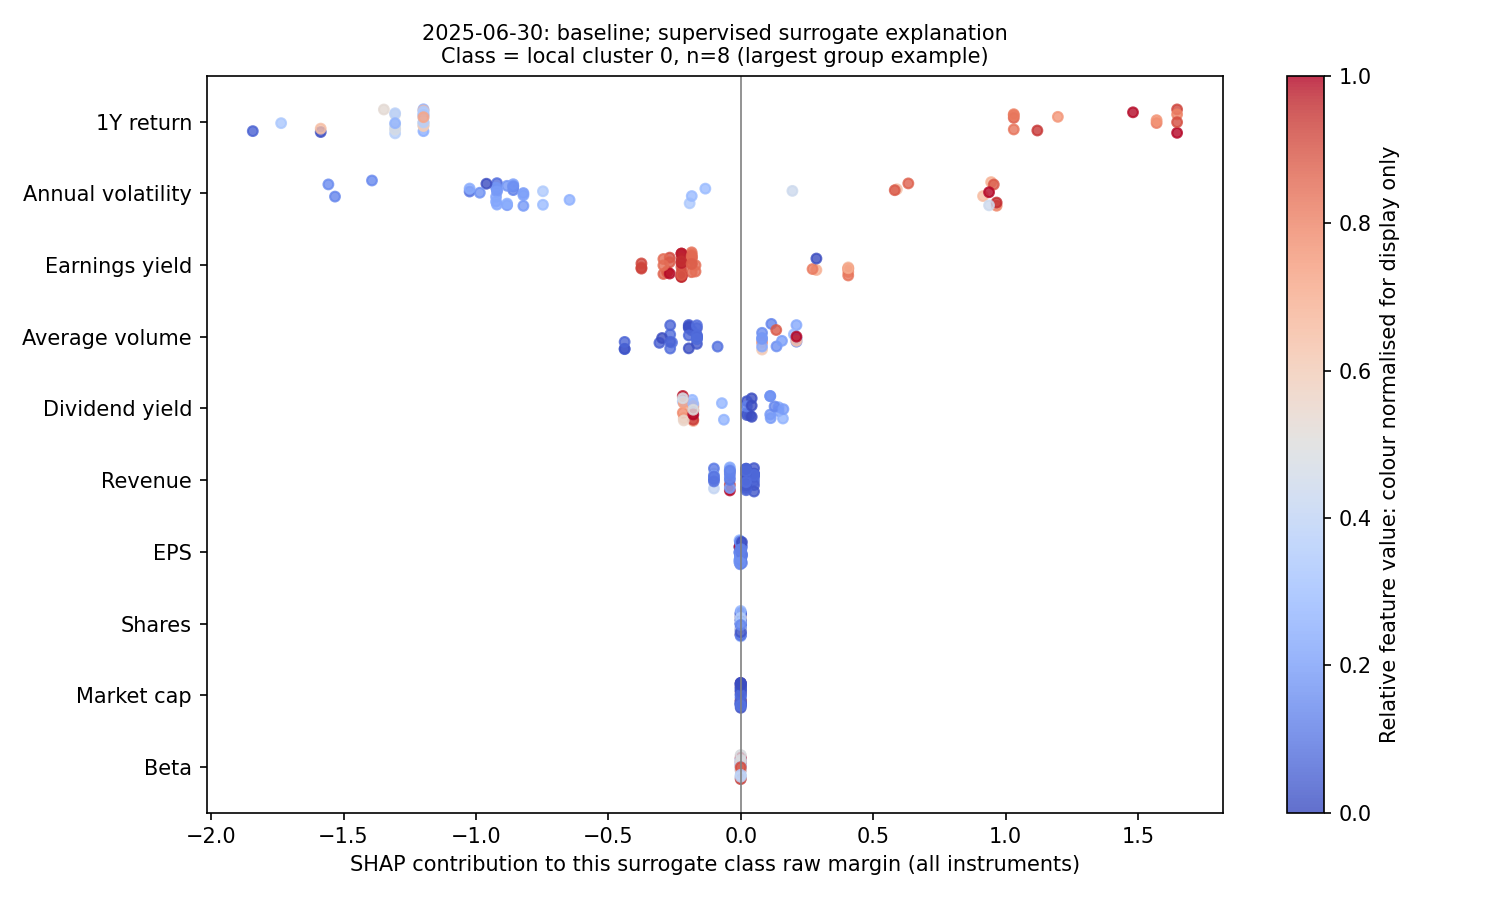

,cluster,n,rank_correlation,status
0,0,8,0.742387,descriptive rank comparison; no p-value
1,1,5,0.574163,descriptive rank comparison; no p-value
2,2,8,0.460157,descriptive rank comparison; no p-value
3,3,5,0.878788,descriptive rank comparison; no p-value
4,4,3,0.747724,descriptive rank comparison; no p-value
5,5,7,0.725959,descriptive rank comparison; no p-value
6,6,3,0.374261,descriptive rank comparison; no p-value
7,7,2,0.420230,descriptive rank comparison; no p-value


**2025-12-31**

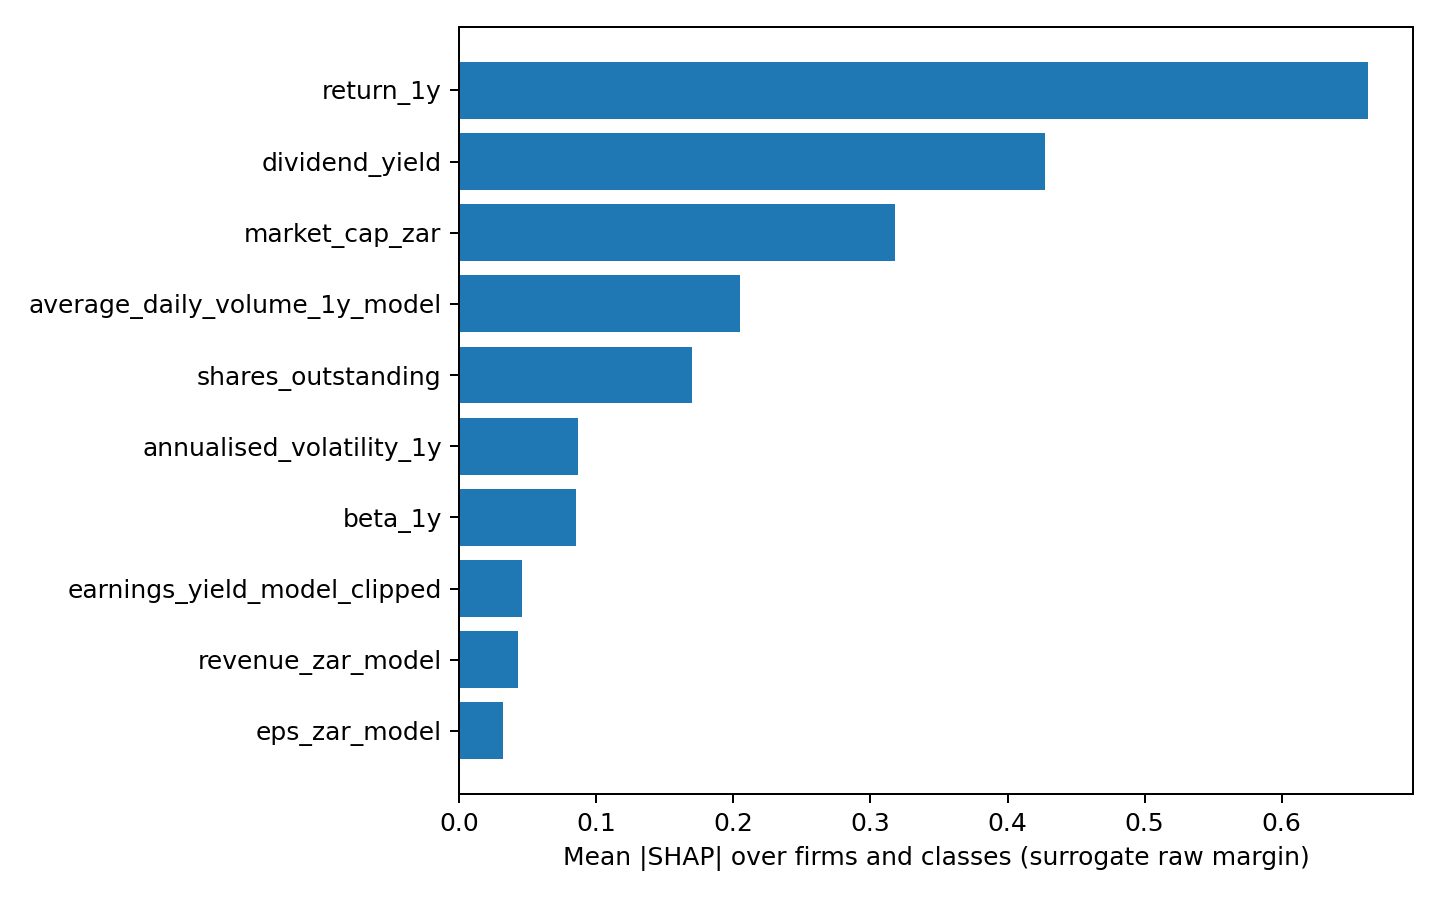

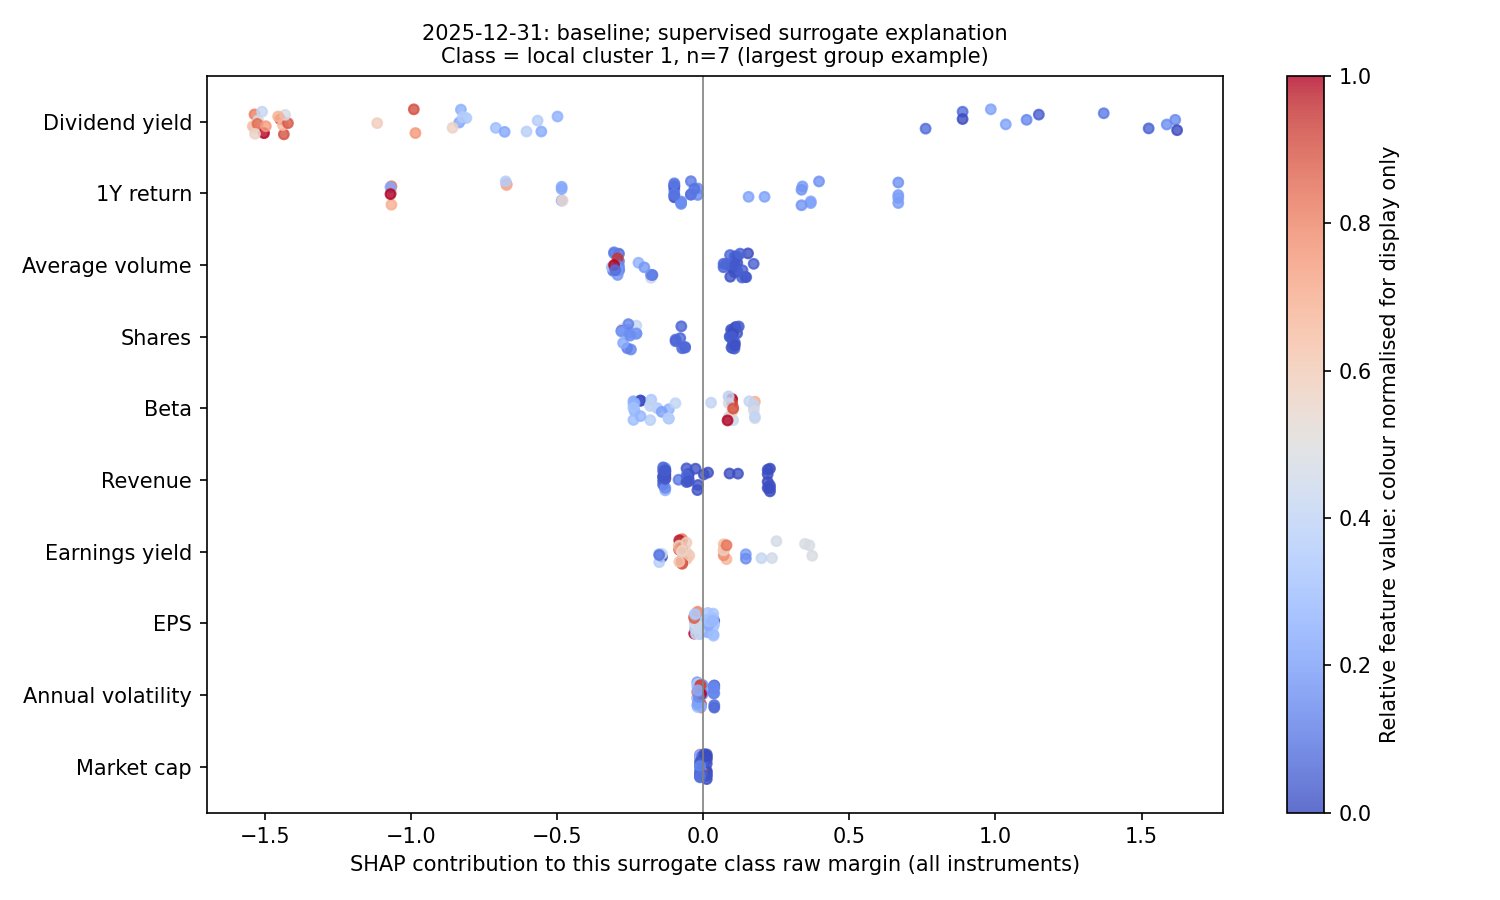

,cluster,n,rank_correlation,status
0,0,6,0.924507,descriptive rank comparison; no p-value
1,1,7,0.551515,descriptive rank comparison; no p-value
2,2,6,0.594026,descriptive rank comparison; no p-value
3,3,7,0.778379,descriptive rank comparison; no p-value
4,4,5,0.660606,descriptive rank comparison; no p-value
5,5,5,0.693304,descriptive rank comparison; no p-value
6,6,4,0.885716,descriptive rank comparison; no p-value
7,7,1,0.200418,descriptive rank comparison; no p-value


**2026-06-30**

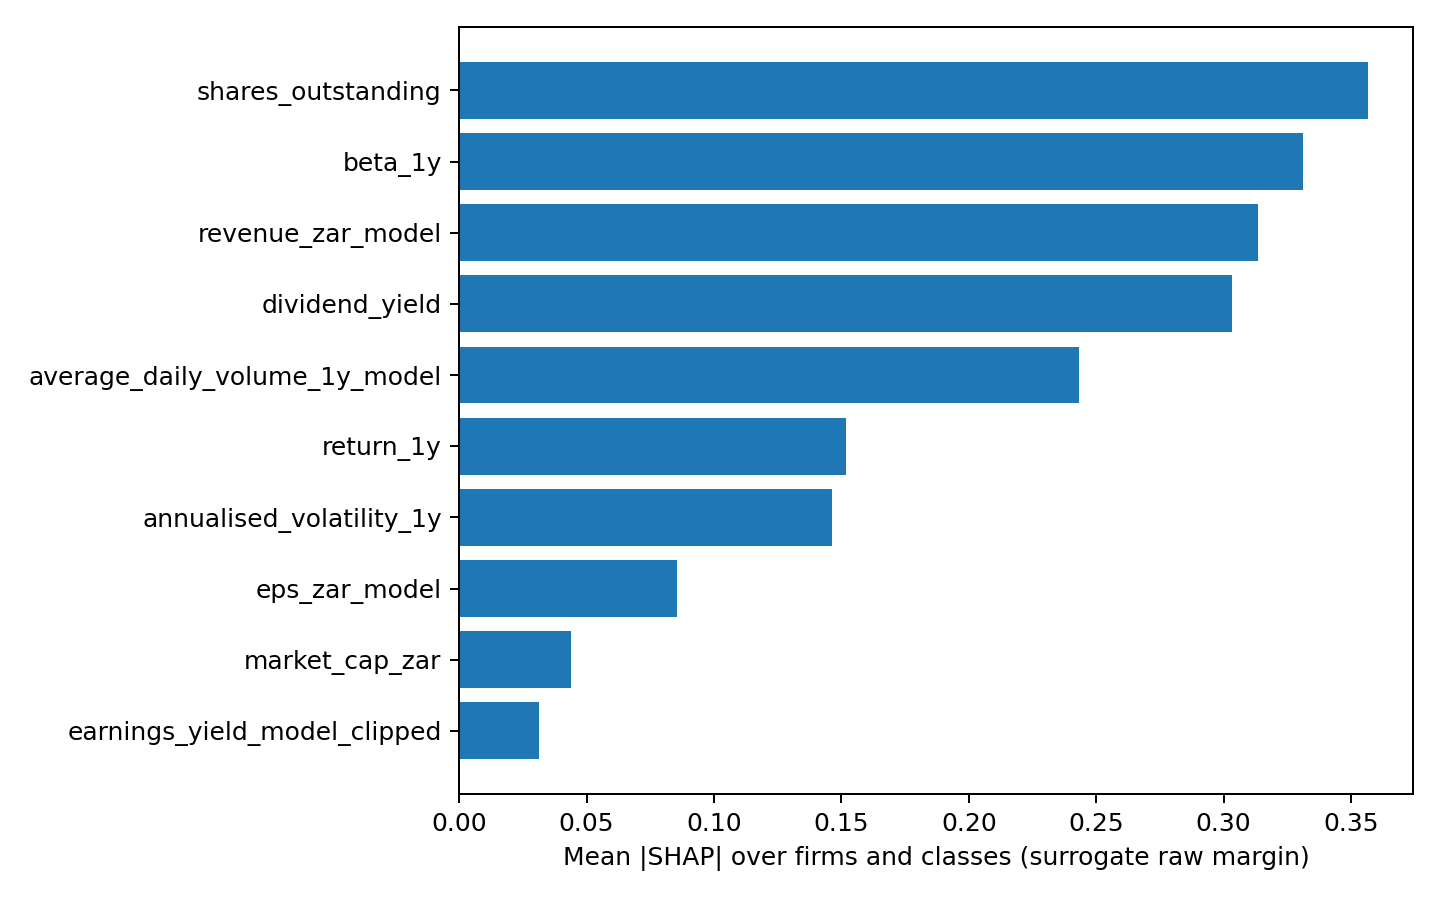

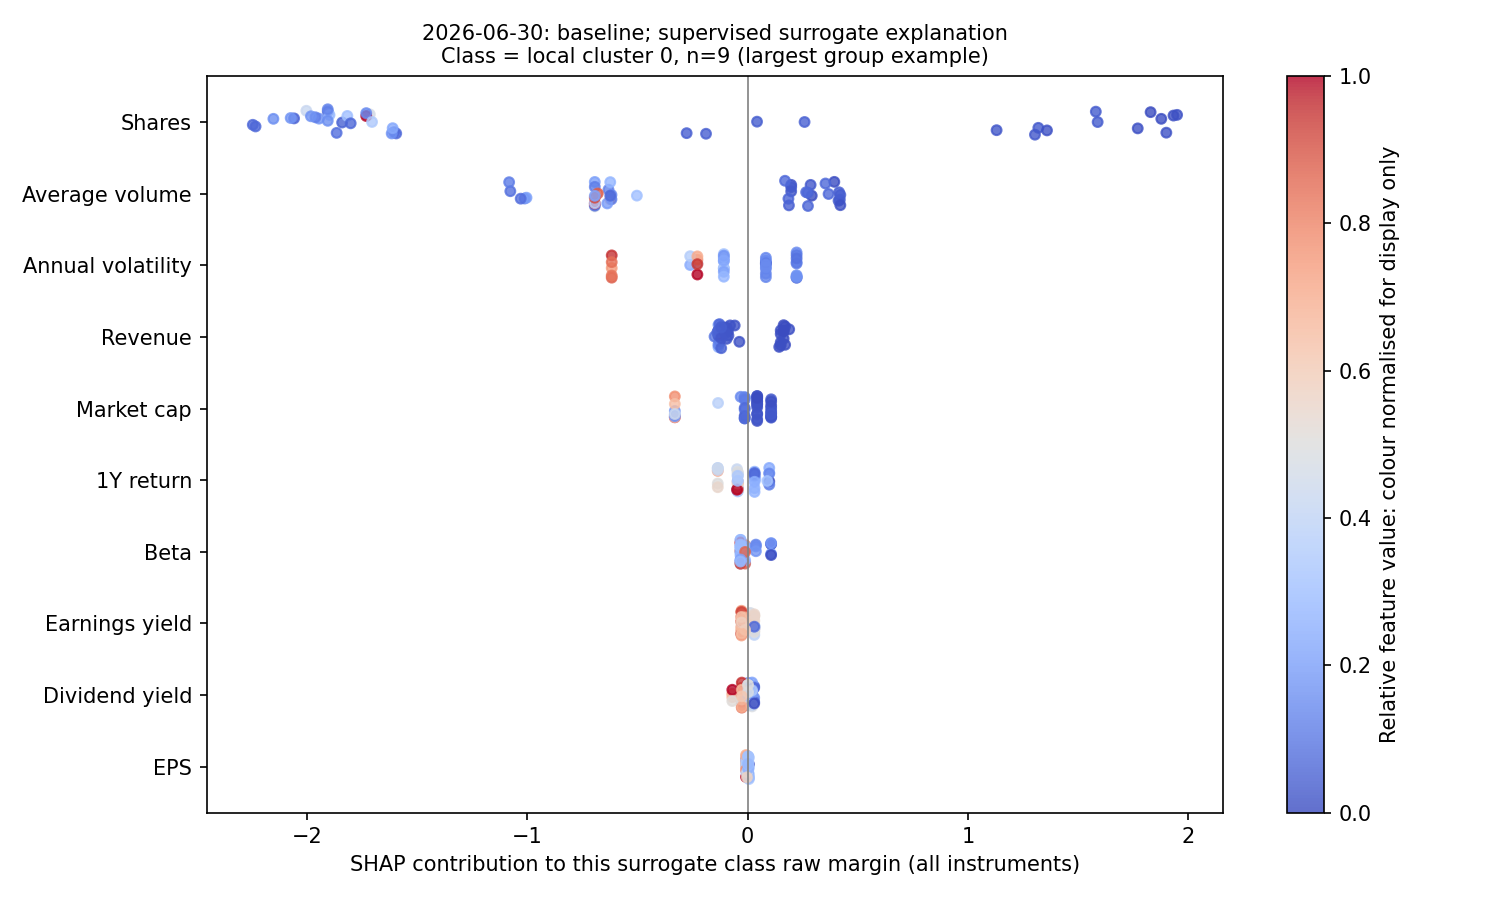

,cluster,n,rank_correlation,status
0,0,9,0.393939,descriptive rank comparison; no p-value
1,1,5,0.693012,descriptive rank comparison; no p-value
2,2,4,0.656491,descriptive rank comparison; no p-value
3,3,8,0.683349,descriptive rank comparison; no p-value
4,4,5,0.092031,descriptive rank comparison; no p-value
5,5,3,0.660606,descriptive rank comparison; no p-value
6,6,5,0.406181,descriptive rank comparison; no p-value
7,7,2,0.487738,descriptive rank comparison; no p-value


### umap_sensitivity: saved SHAP

**2025-06-30**

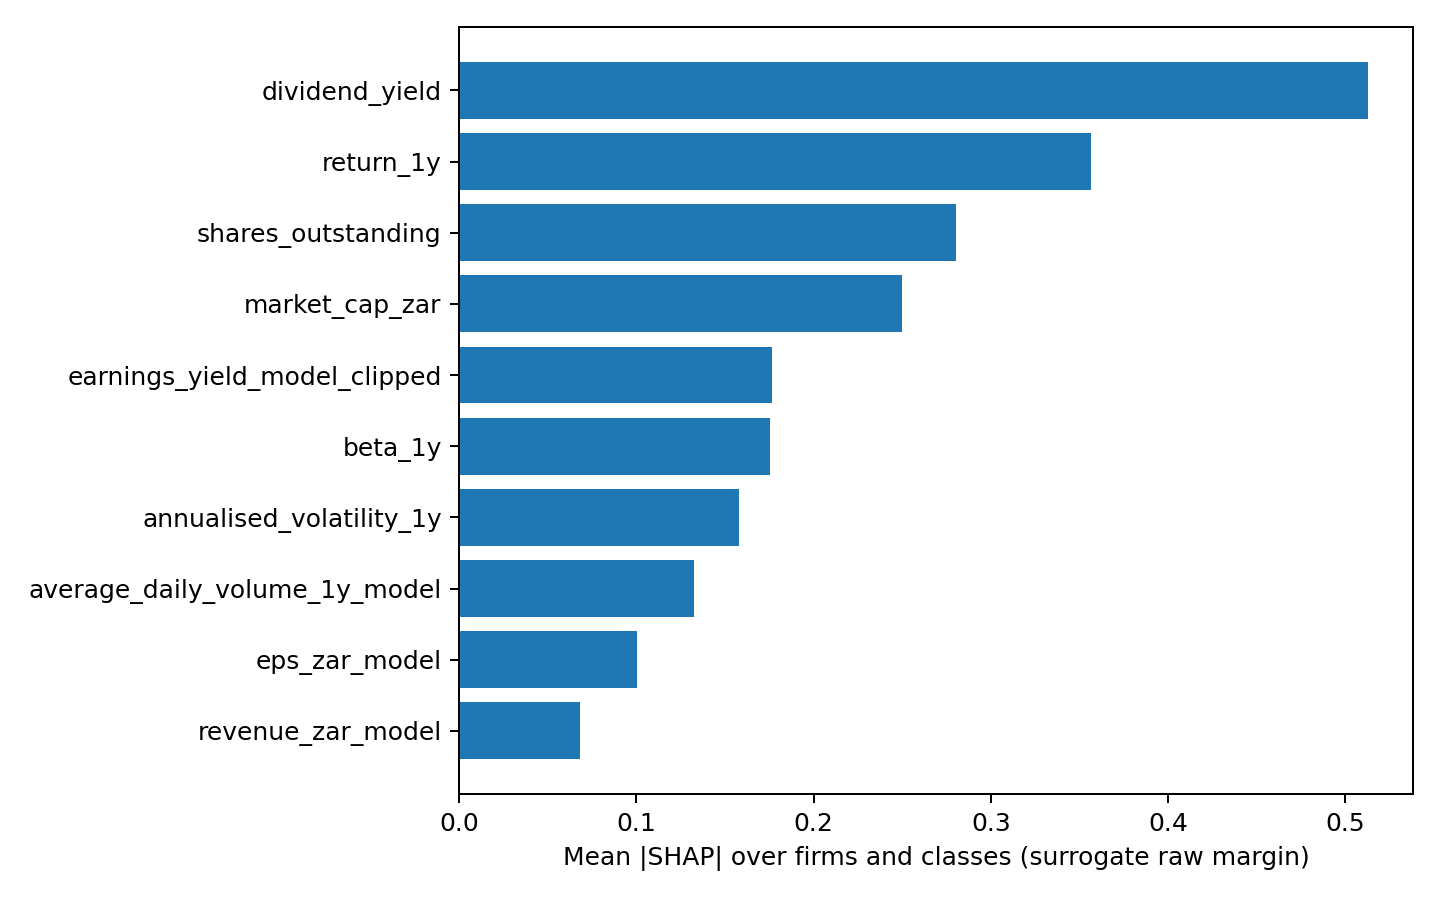

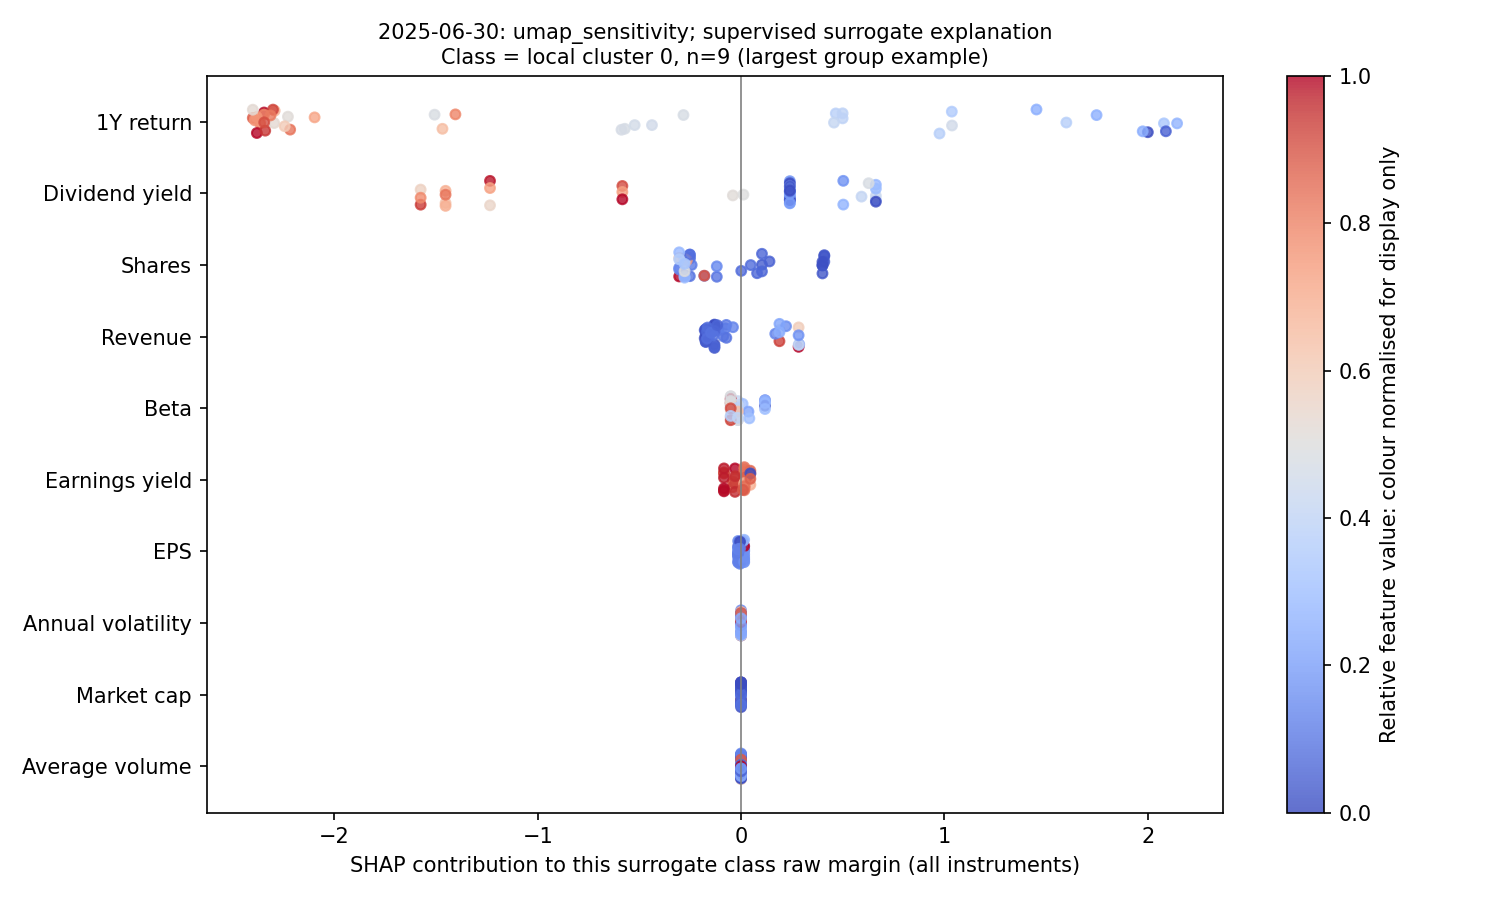

,cluster,n,rank_correlation,status
0,0,9,0.619679,descriptive rank comparison; no p-value
1,1,8,0.575281,descriptive rank comparison; no p-value
2,2,5,0.706595,descriptive rank comparison; no p-value
3,3,3,0.820672,descriptive rank comparison; no p-value
4,4,5,0.499597,descriptive rank comparison; no p-value
5,5,3,0.273557,descriptive rank comparison; no p-value
6,6,5,0.218857,descriptive rank comparison; no p-value
7,7,3,0.570595,descriptive rank comparison; no p-value


**2025-12-31**

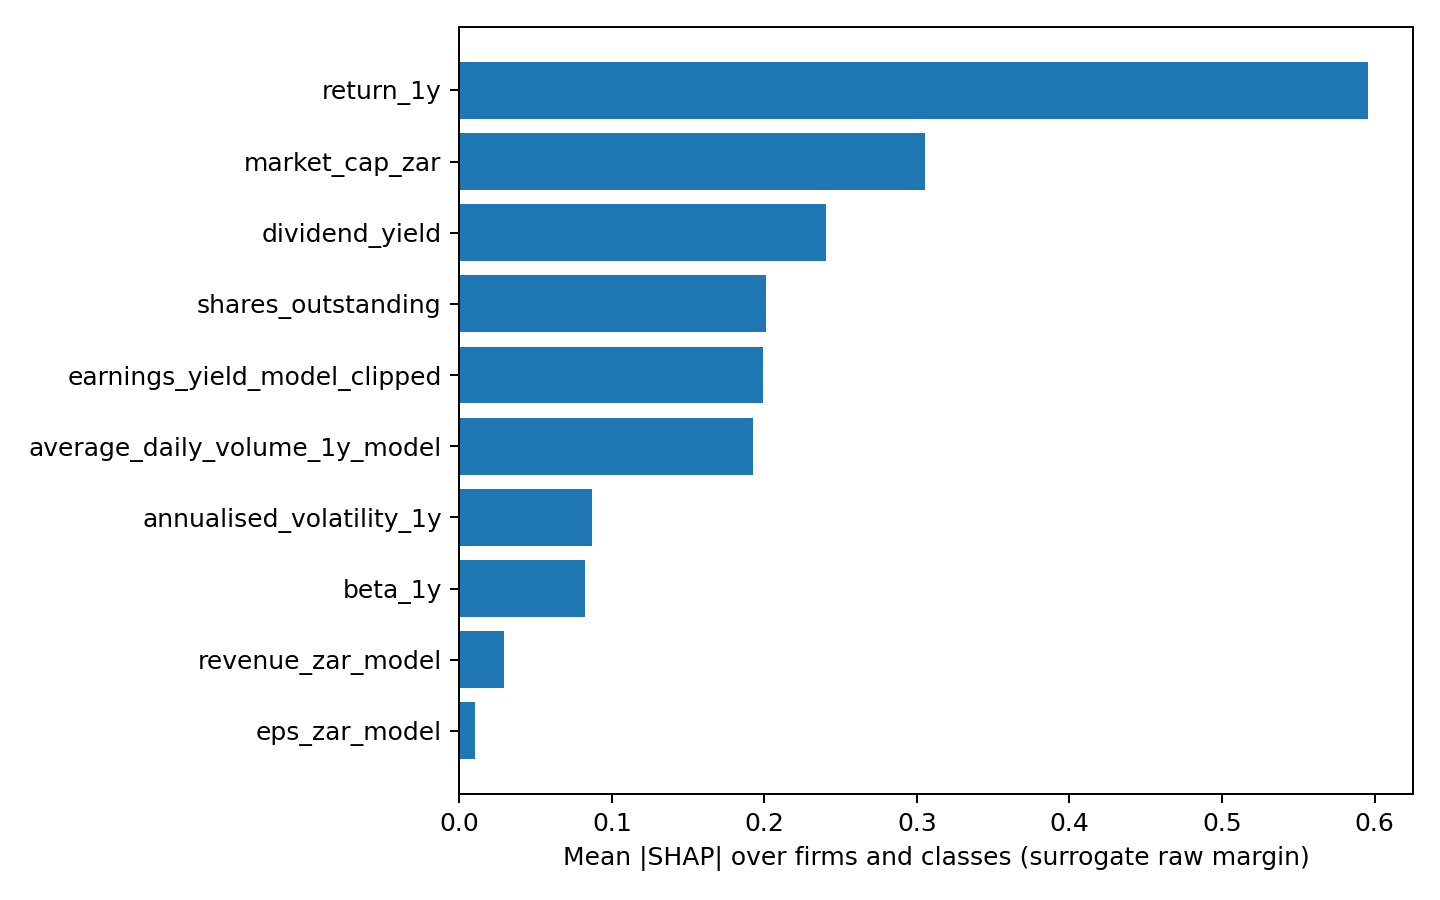

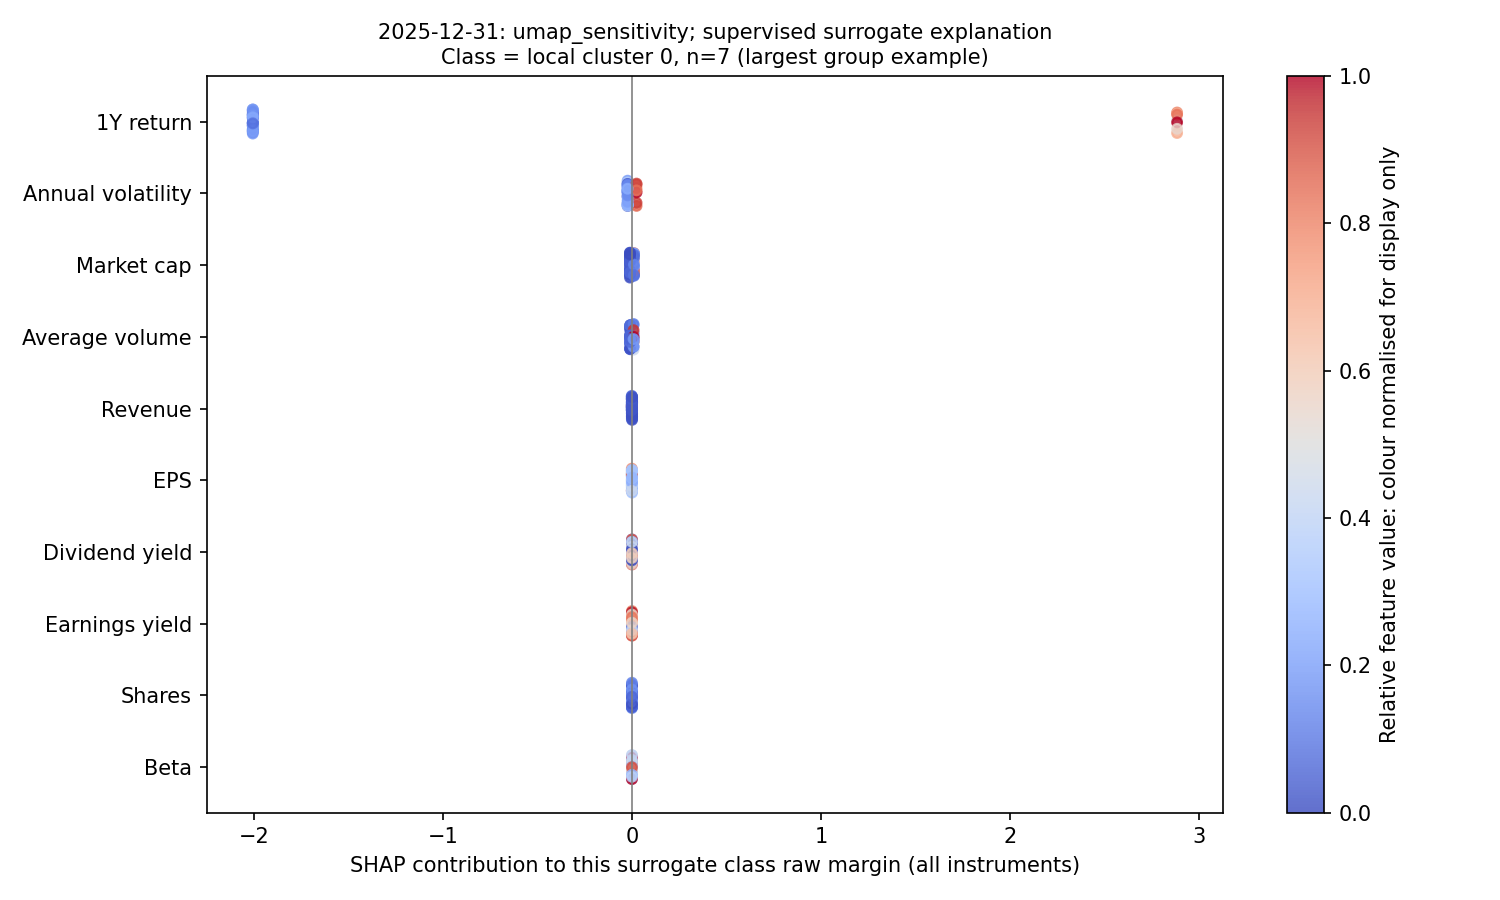

,cluster,n,rank_correlation,status
0,0,7,0.256375,descriptive rank comparison; no p-value
1,1,7,0.793939,descriptive rank comparison; no p-value
2,2,7,0.406061,descriptive rank comparison; no p-value
3,3,6,0.573543,descriptive rank comparison; no p-value
4,4,5,0.459021,descriptive rank comparison; no p-value
5,5,4,0.588199,descriptive rank comparison; no p-value
6,6,3,0.633817,descriptive rank comparison; no p-value
7,7,2,0.887625,descriptive rank comparison; no p-value


**2026-06-30**

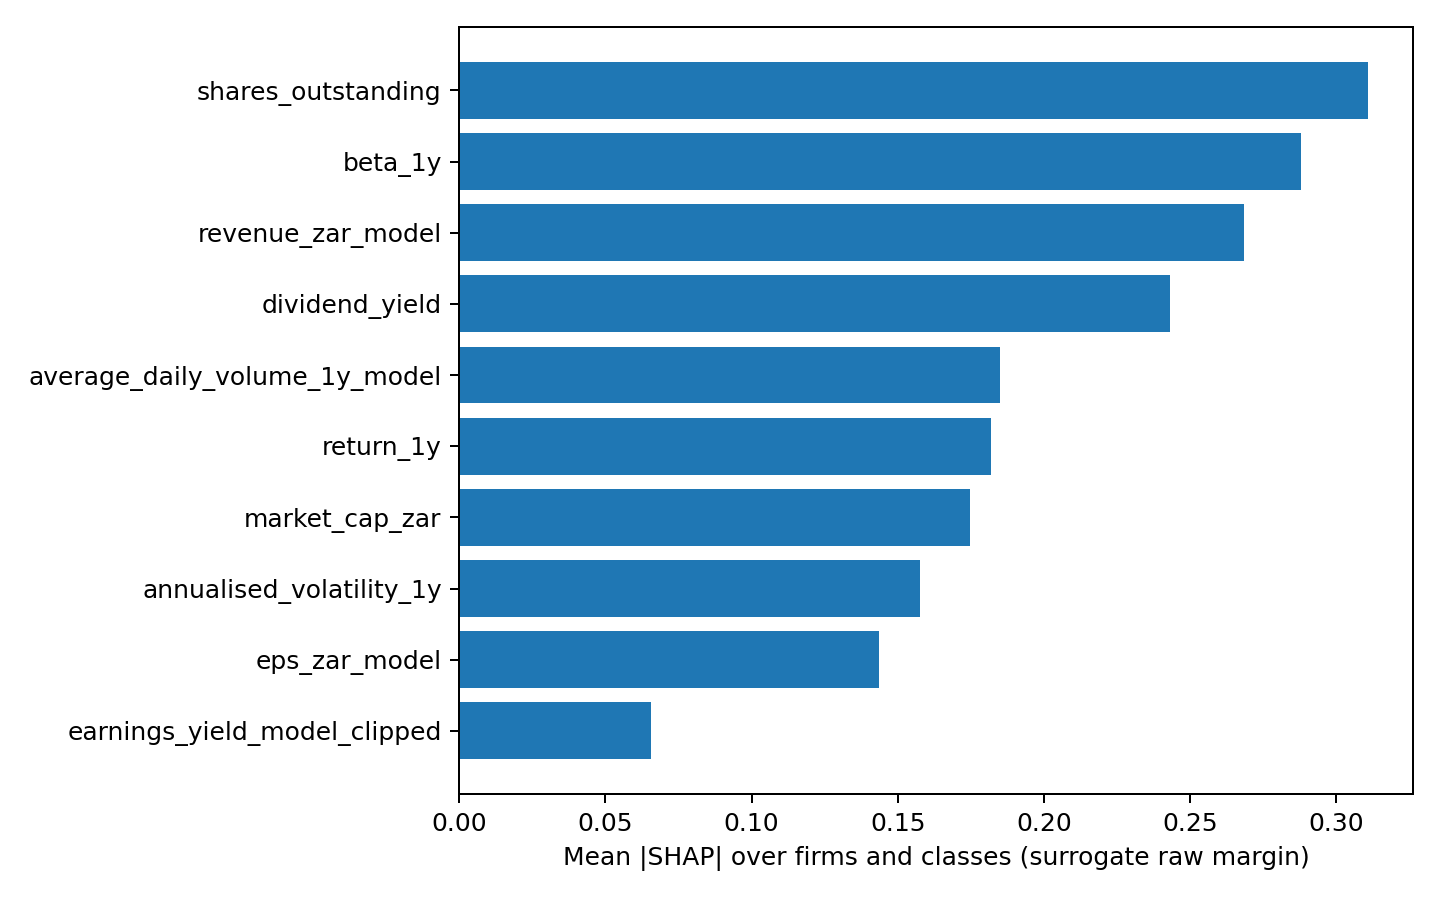

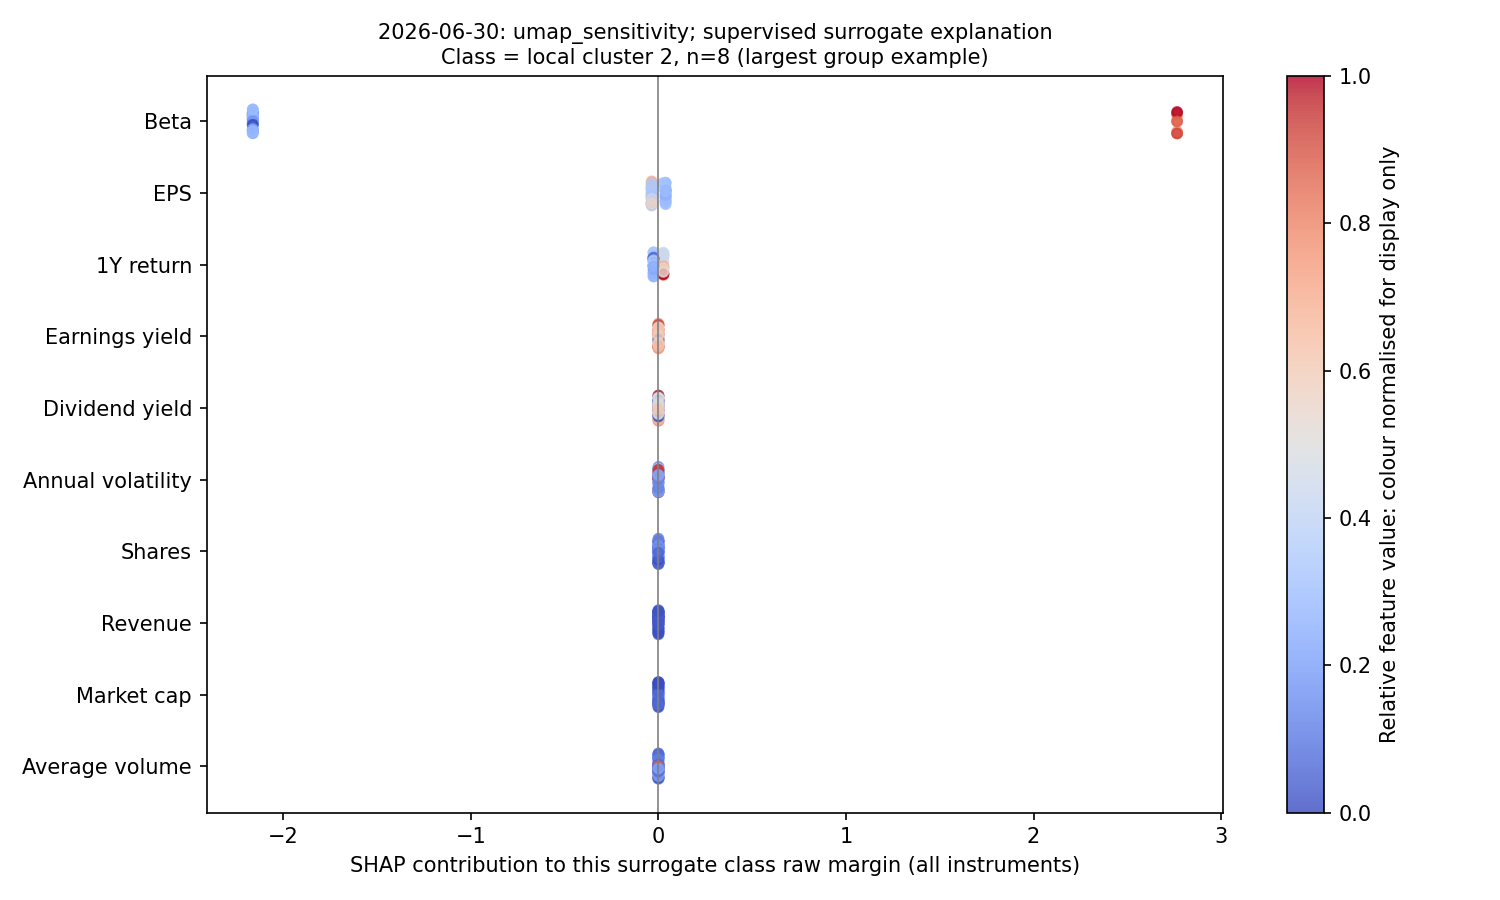

,cluster,n,rank_correlation,status
0,0,7,0.600000,descriptive rank comparison; no p-value
1,1,4,0.478788,descriptive rank comparison; no p-value
2,2,8,0.201330,descriptive rank comparison; no p-value
3,3,5,0.018759,descriptive rank comparison; no p-value
4,4,5,0.449799,descriptive rank comparison; no p-value
5,5,4,0.693470,descriptive rank comparison; no p-value
6,6,6,0.606546,descriptive rank comparison; no p-value
7,7,2,0.487738,descriptive rank comparison; no p-value


In [6]:
display(pd.read_csv(SOURCE / "surrogate_fidelity.csv"))
for name, folder in MODELS.items():
    display(Markdown(f"### {name}: saved SHAP"))
    for date in DATES:
        display(Markdown(f"**{date}**"))
        show(SOURCE / folder / date / "shap_global.png")
        show(SOURCE / folder / date / "shap_distribution.png")
        display(pd.read_csv(SOURCE / folder / date / "shap_univariate_rank_summary.csv"))


## Cluster histories, actual Jaccard and instrument movement
Each heatmap of **Jaccard similarity** shows intersection / union on continuing instruments, on a fixed 0-1 scale. These are not transition probabilities; rows need not sum to one. Empty unions are NA. Adjacent pairs have 40 continuing instruments, while the history panel uses the 39 instruments at all dates.

Cluster IDs are sequentially aligned using maximum Jaccard overlap, not permanent economic identities. A separate count heatmap shows how many instruments move. Existing maximum-overlap alignment is retained separately; the sensitivity table identifies differing shift interpretations.

,study_model,observed_all_three,stable,shifted,membership_gaps,screen_candidates,multi_seed_supported_candidates,interpretation
0,baseline,39,21,18,4,0,0,Additional descriptive reporting; original mod...
1,umap_sensitivity,39,20,19,4,0,0,Additional descriptive reporting; original mod...


,study_model,before,after,continuing,entries,exits,ari,nmi
0,baseline,2025-06-30,2025-12-31,40,1,1,0.4502,0.7138
1,baseline,2025-12-31,2026-06-30,40,1,1,0.6045,0.7878
2,umap_sensitivity,2025-06-30,2025-12-31,40,1,1,0.3831,0.6860
3,umap_sensitivity,2025-12-31,2026-06-30,40,1,1,0.5687,0.7549


### baseline

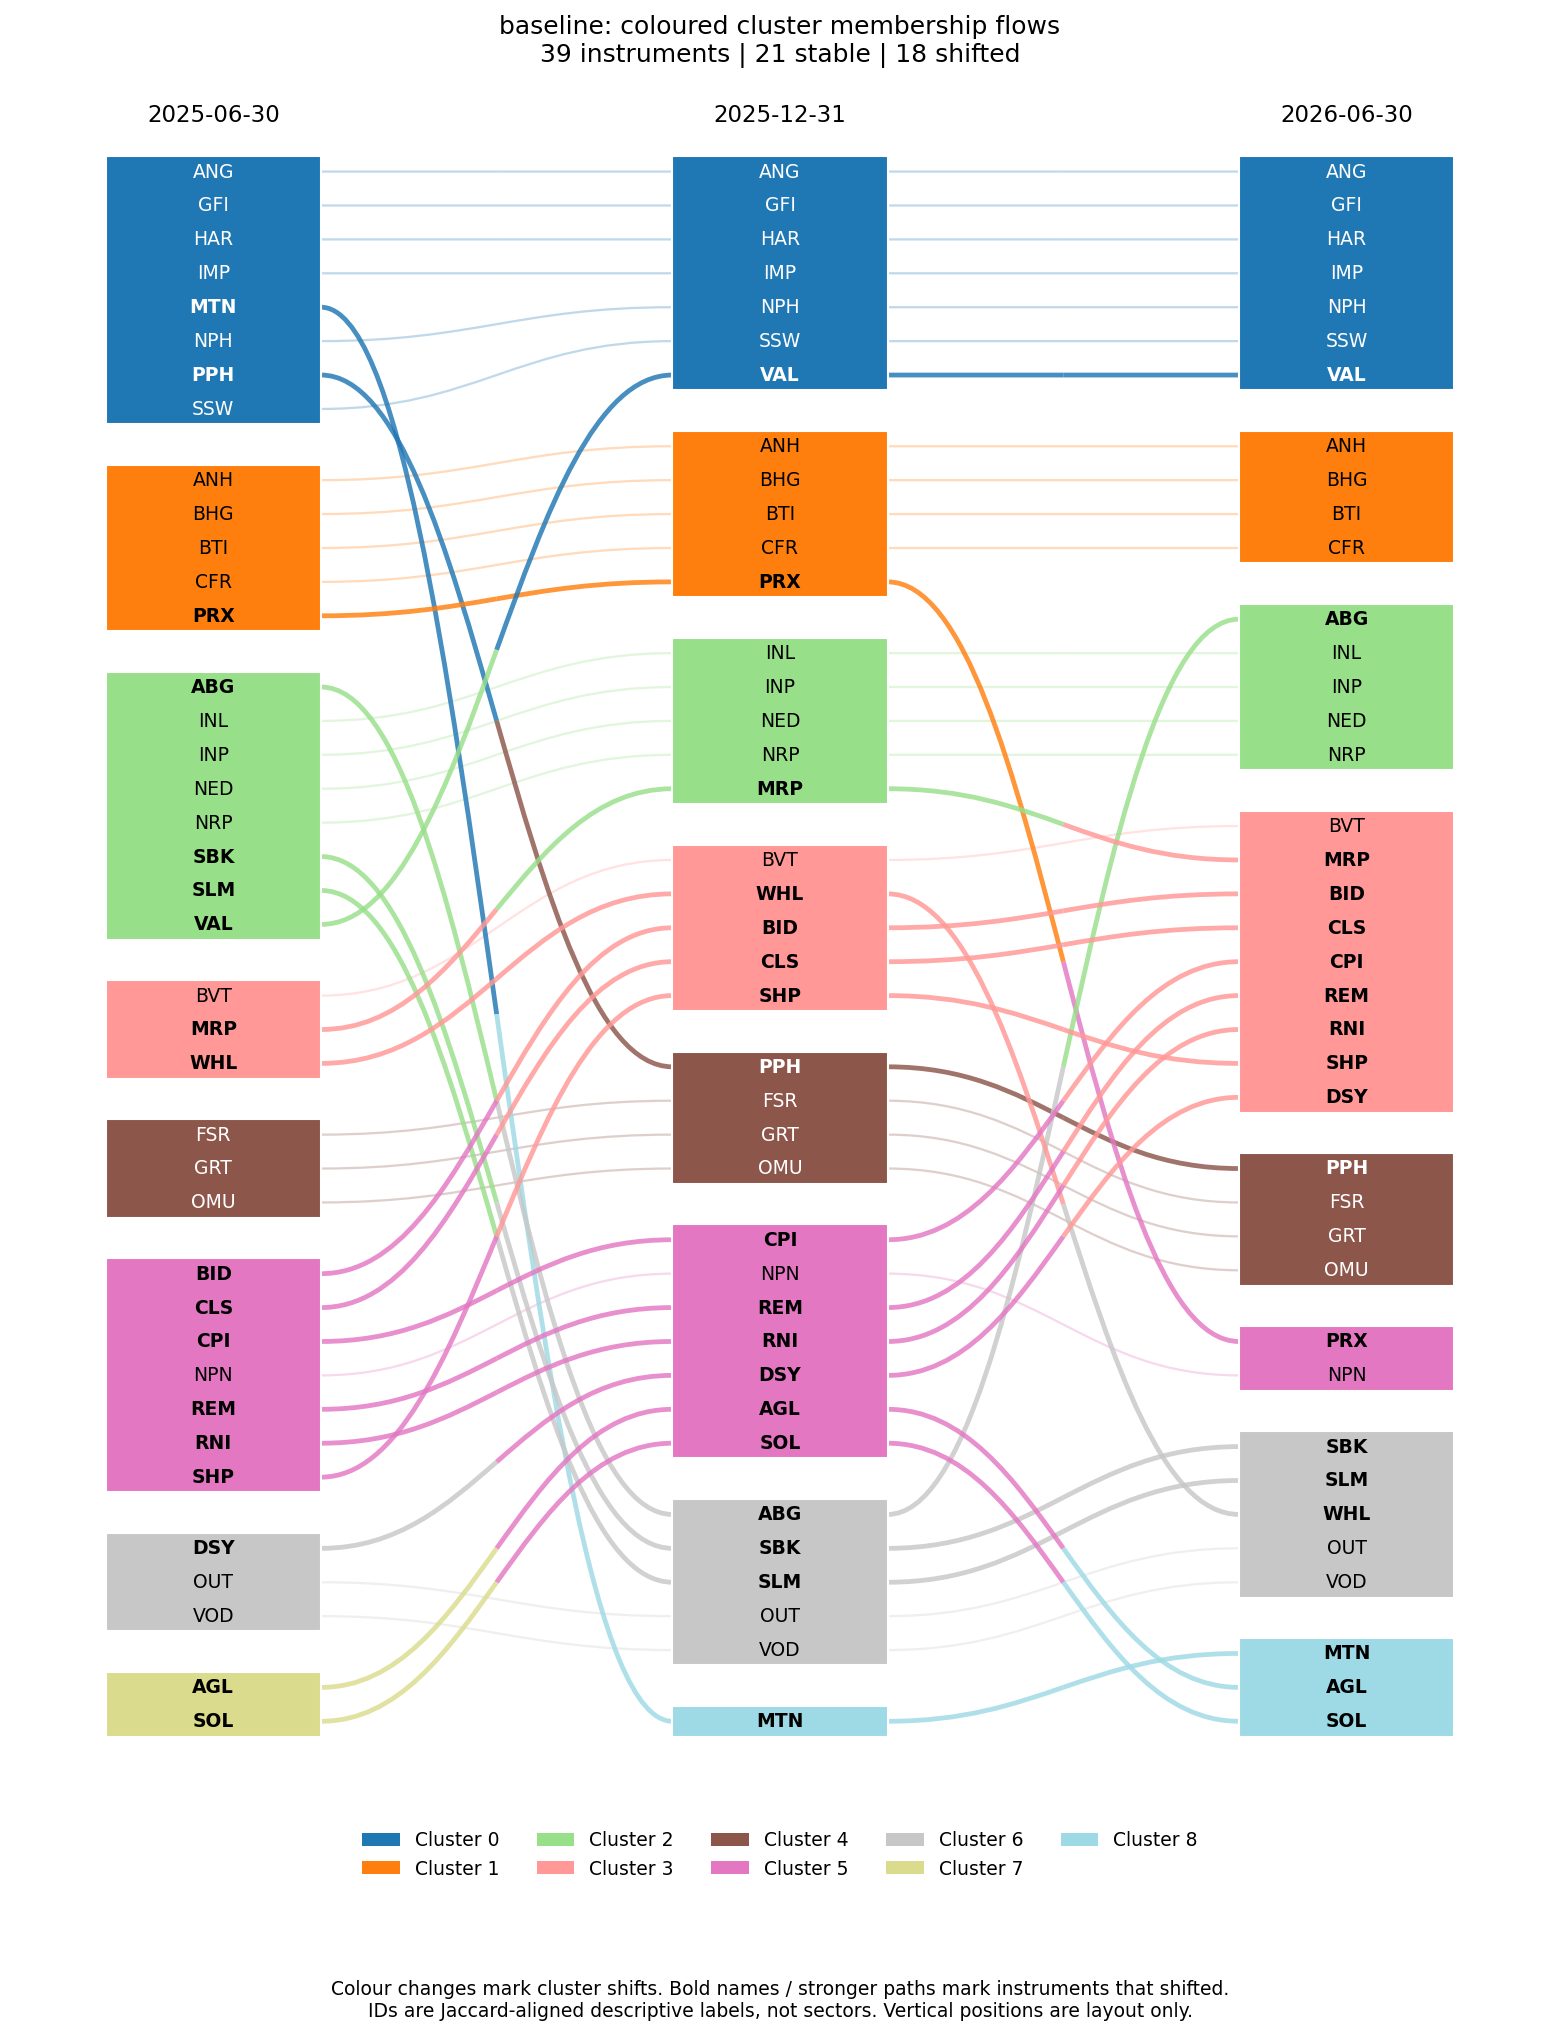

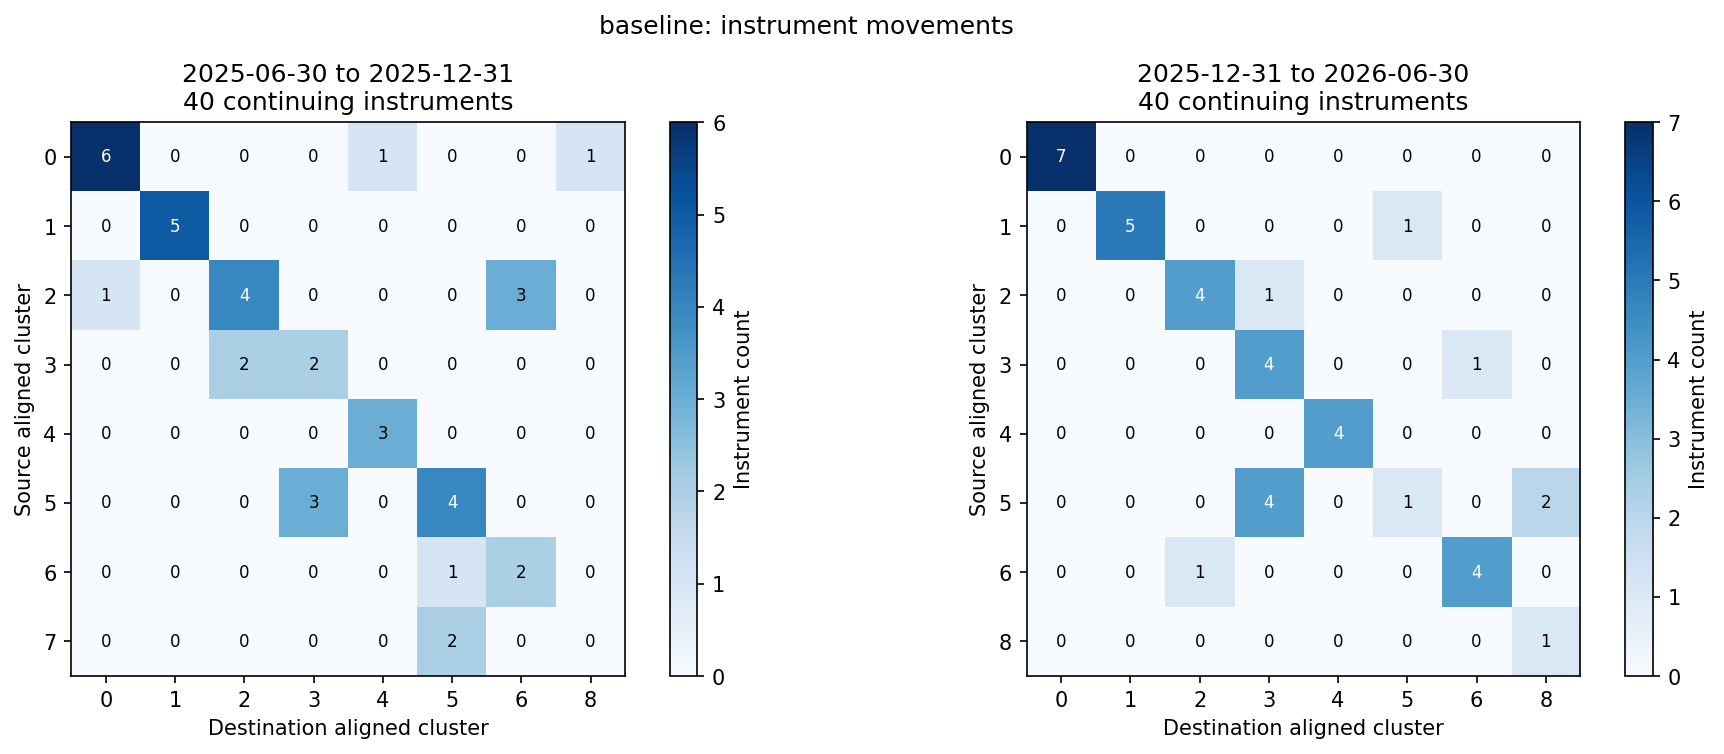

**Stable across all dates**

,ticker,2025-06-30,2025-12-31,2026-06-30,observed_all_three,stability_status,baseline_to_current_changed,direct_baseline_to_current_changed
0,ANG,0.0,0.0,0.0,True,stable all three,False,False
1,ANH,1.0,1.0,1.0,True,stable all three,False,False
2,BHG,1.0,1.0,1.0,True,stable all three,False,False
3,BTI,1.0,1.0,1.0,True,stable all three,False,False
4,BVT,3.0,3.0,3.0,True,stable all three,False,True
5,CFR,1.0,1.0,1.0,True,stable all three,False,False
6,FSR,4.0,4.0,4.0,True,stable all three,False,False
7,GFI,0.0,0.0,0.0,True,stable all three,False,False
8,GRT,4.0,4.0,4.0,True,stable all three,False,False
9,HAR,0.0,0.0,0.0,True,stable all three,False,False


**Shifted at least once**

,ticker,2025-06-30,2025-12-31,2026-06-30,observed_all_three,stability_status,baseline_to_current_changed,direct_baseline_to_current_changed
0,ABG,2.0,6.0,2.0,True,shifted at least once,False,False
1,AGL,7.0,5.0,8.0,True,shifted at least once,True,False
2,BID,5.0,3.0,3.0,True,shifted at least once,True,False
3,CLS,5.0,3.0,3.0,True,shifted at least once,True,False
4,CPI,5.0,5.0,3.0,True,shifted at least once,True,False
5,DSY,6.0,5.0,3.0,True,shifted at least once,True,True
6,MRP,3.0,2.0,3.0,True,shifted at least once,False,True
7,MTN,0.0,8.0,8.0,True,shifted at least once,True,True
8,PPH,0.0,4.0,4.0,True,shifted at least once,True,True
9,PRX,1.0,1.0,5.0,True,shifted at least once,True,True


**Index entries / exits**

,before,after,ticker,membership_event,cluster_before,cluster_after,cluster_changed
4,2025-06-30,2025-12-31,APN,exit,3.0,NaN,NaN
15,2025-06-30,2025-12-31,GLN,entry,NaN,1.0,NaN
62,2025-12-31,2026-06-30,MNP,exit,2.0,NaN,NaN
71,2025-12-31,2026-06-30,PAN,entry,NaN,0.0,NaN


**Alignment-objective differences**

,before,after,ticker,jaccard_changed,overlap_changed
41,2025-12-31,2026-06-30,AGL,True,False
61,2025-12-31,2026-06-30,MTN,False,True
64,2025-12-31,2026-06-30,NPN,False,True
75,2025-12-31,2026-06-30,SOL,True,False


### umap_sensitivity

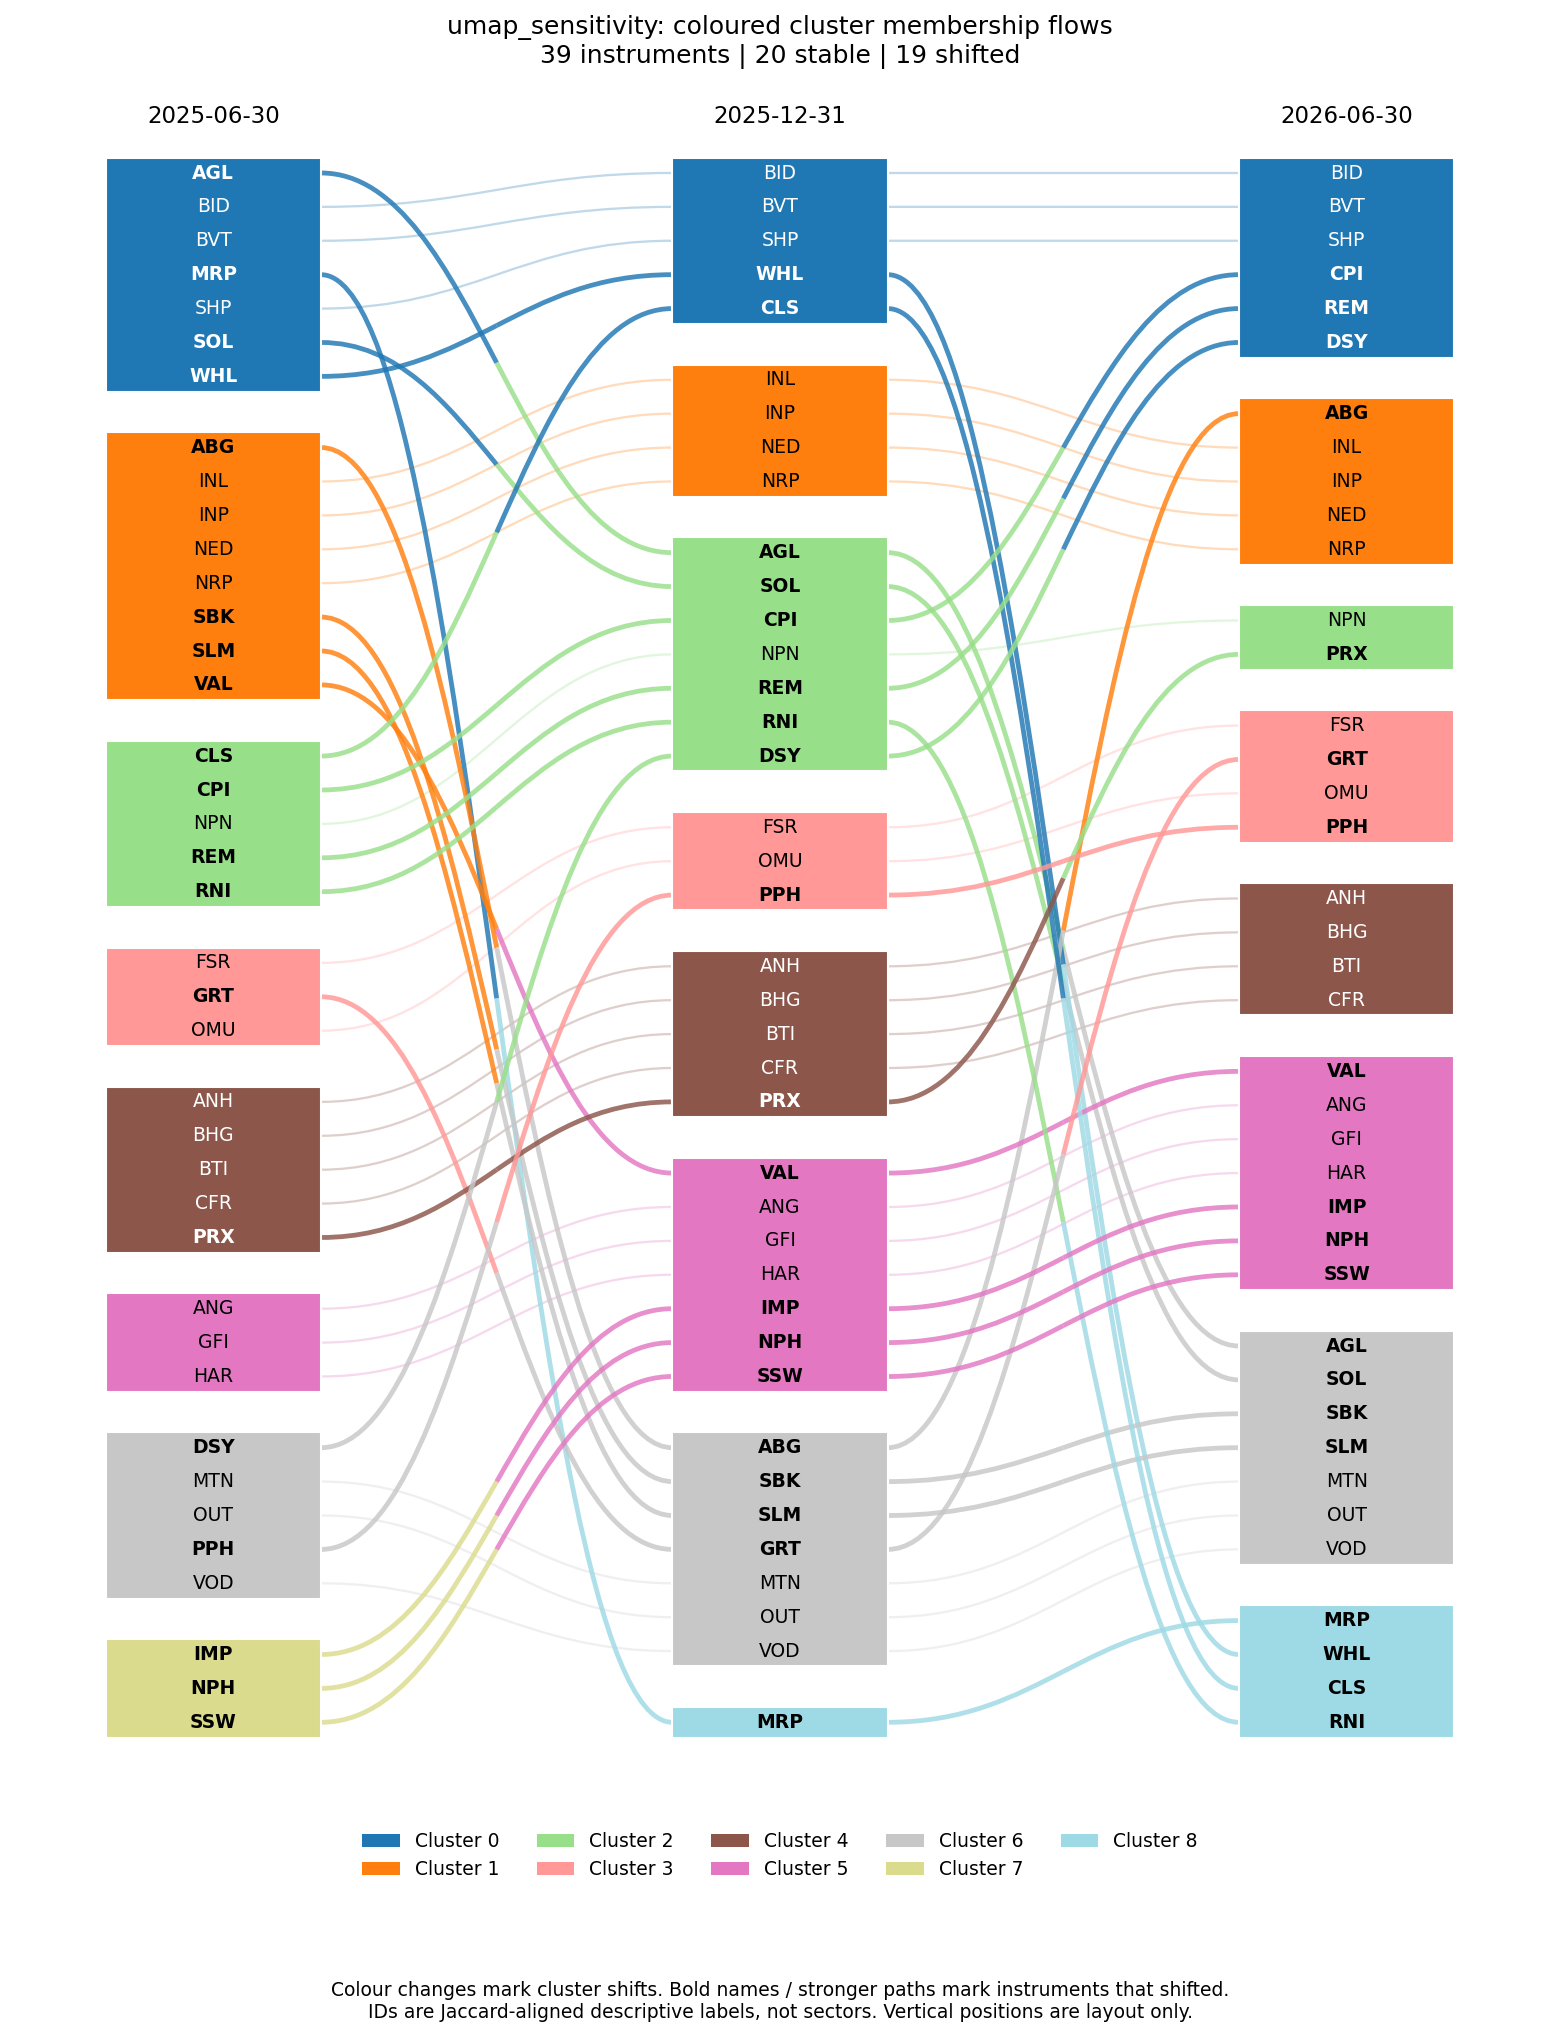

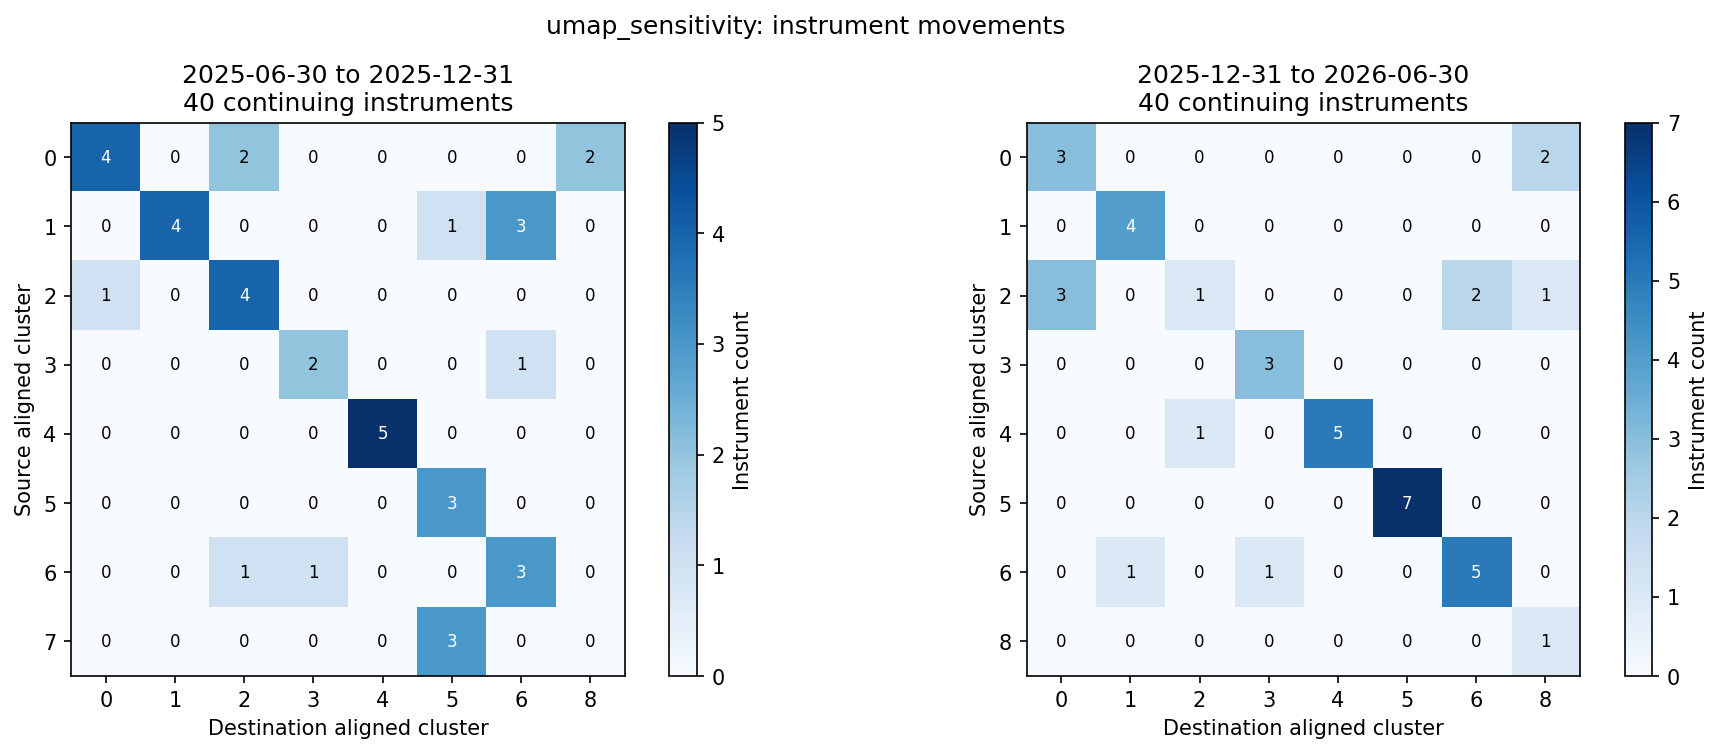

**Stable across all dates**

,ticker,2025-06-30,2025-12-31,2026-06-30,observed_all_three,stability_status,baseline_to_current_changed,direct_baseline_to_current_changed
0,ANG,5.0,5.0,5.0,True,stable all three,False,False
1,ANH,4.0,4.0,4.0,True,stable all three,False,False
2,BHG,4.0,4.0,4.0,True,stable all three,False,False
3,BID,0.0,0.0,0.0,True,stable all three,False,False
4,BTI,4.0,4.0,4.0,True,stable all three,False,False
5,BVT,0.0,0.0,0.0,True,stable all three,False,False
6,CFR,4.0,4.0,4.0,True,stable all three,False,False
7,FSR,3.0,3.0,3.0,True,stable all three,False,False
8,GFI,5.0,5.0,5.0,True,stable all three,False,False
9,HAR,5.0,5.0,5.0,True,stable all three,False,False


**Shifted at least once**

,ticker,2025-06-30,2025-12-31,2026-06-30,observed_all_three,stability_status,baseline_to_current_changed,direct_baseline_to_current_changed
0,ABG,1.0,6.0,1.0,True,shifted at least once,False,False
1,AGL,0.0,2.0,6.0,True,shifted at least once,True,True
2,CLS,2.0,0.0,8.0,True,shifted at least once,True,False
3,CPI,2.0,2.0,0.0,True,shifted at least once,True,True
4,DSY,6.0,2.0,0.0,True,shifted at least once,True,True
5,GRT,3.0,6.0,3.0,True,shifted at least once,False,False
6,IMP,7.0,5.0,5.0,True,shifted at least once,True,True
7,MRP,0.0,8.0,8.0,True,shifted at least once,True,True
8,NPH,7.0,5.0,5.0,True,shifted at least once,True,True
9,PPH,6.0,3.0,3.0,True,shifted at least once,True,True


**Index entries / exits**

,before,after,ticker,membership_event,cluster_before,cluster_after,cluster_changed
4,2025-06-30,2025-12-31,APN,exit,0.0,NaN,NaN
15,2025-06-30,2025-12-31,GLN,entry,NaN,4.0,NaN
62,2025-12-31,2026-06-30,MNP,exit,8.0,NaN,NaN
71,2025-12-31,2026-06-30,PAN,entry,NaN,5.0,NaN


**Alignment-objective differences**

,before,after,ticker,jaccard_changed,overlap_changed
45,2025-12-31,2026-06-30,BID,False,True
47,2025-12-31,2026-06-30,BVT,False,True
49,2025-12-31,2026-06-30,CLS,True,False
50,2025-12-31,2026-06-30,CPI,True,False
51,2025-12-31,2026-06-30,DSY,True,False
60,2025-12-31,2026-06-30,MRP,False,True
64,2025-12-31,2026-06-30,NPN,False,True
70,2025-12-31,2026-06-30,REM,True,False
73,2025-12-31,2026-06-30,SHP,False,True
79,2025-12-31,2026-06-30,WHL,True,False


In [7]:
display(pd.read_csv(REPORT / "longitudinal_summary.csv"))
display(pd.read_csv(SOURCE / "temporal_agreement.csv").round(4))
for name in MODELS:
    folder = REPORT / name
    display(Markdown(f"### {name}"))
    for figure in ["cluster_histories.png", "movement_counts_heatmaps.png"]:
        show(FLOW_REPORT / f"{name}_cluster_flows.png" if figure == "cluster_histories.png" else folder / figure)
    display(Markdown("**Stable across all dates**"))
    display(pd.read_csv(folder / "stable_instruments.csv"))
    display(Markdown("**Shifted at least once**"))
    display(pd.read_csv(folder / "shifted_instruments.csv"))
    display(Markdown("**Index entries / exits**"))
    display(pd.read_csv(folder / "membership_transitions.csv").query("membership_event != 'continuing'"))
    sensitivity = pd.read_csv(folder / "alignment_objective_sensitivity.csv")
    display(Markdown("**Alignment-objective differences**"))
    display(sensitivity.loc[sensitivity.jaccard_changed != sensitivity.overlap_changed])


## Descriptive sector and geometric screens
Individual squared Mahalanobis distance has **no n multiplier**. The paper-style F reference is descriptive and is not a calibrated individual-outlier test on learned coordinates. Internal-Beta sensitivity, seed estimability and support are retained. No confirmed outlier is declared. Singular covariance remains undefined.

Singleton, leave-one-out sector divergence and geometric extremes are separate. Cluster SHAP does not explain the distance statistic. No new temporal-outlier taxonomy is introduced. Legacy sector/source-certification and imputation limitations remain.

In [8]:
for name in MODELS:
    display(Markdown(f"### {name}: sector and screen diagnostics"))
    diagnostics = pd.read_csv(REPORT / name / "sector_and_screen_diagnostics.csv")
    display(diagnostics.groupby("decision_date").agg(
        instruments=("ticker", "size"), singletons=("singleton", "sum"),
        geometric_candidates=("screen_flag", "sum"), supported_candidates=("multi_seed_supported", "sum")))
    with pd.option_context("display.max_rows", None, "display.max_columns", None):
        for date in DATES:
            display(Markdown(f"**{date}**"))
            display(diagnostics.loc[diagnostics.decision_date == date])


### baseline: sector and screen diagnostics

,instruments,singletons,geometric_candidates,supported_candidates
decision_date,,,,
2025-06-30,41,0,0,0
2025-12-31,41,1,0,0
2026-06-30,41,0,0,0


**2025-06-30**

,ticker,sector_label,other_member_majority,sector_divergence,sector_status,cluster_size,singleton,raw_cluster,decision_date,individual_d2,f_reference,internal_beta_reference,screen_flag,multi_seed_supported,estimable_seeds,reference_exceeding_seeds,total_seeds,screen_status,fundamentals_imputed,volume_imputed
0,ABG,Financials,Financials,False,contextual comparison,8,False,2,2025-06-30,2.403558,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False
1,AGL,Basic Materials,Basic Materials,False,contextual comparison,2,False,7,2025-06-30,1.253902,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,True
2,ANG,Basic Materials,Basic Materials,False,contextual comparison,8,False,0,2025-06-30,1.222136,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False
3,ANH,Consumer Goods,Consumer Goods,False,contextual comparison,5,False,1,2025-06-30,3.393663,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False
4,APN,Health Care,Consumer Services,True,contextual comparison,5,False,3,2025-06-30,3.105989,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False
5,BHG,Basic Materials,Consumer Goods,True,contextual comparison,5,False,1,2025-06-30,4.029379,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False
6,BID,Consumer Services,Financials,True,contextual comparison,7,False,5,2025-06-30,0.974887,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False
7,BTI,Consumer Goods,Consumer Goods,False,contextual comparison,5,False,1,2025-06-30,3.018786,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False
8,BVT,Industrials,Consumer Services,True,contextual comparison,5,False,3,2025-06-30,2.776490,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False
9,CFR,Consumer Goods,Consumer Goods,False,contextual comparison,5,False,1,2025-06-30,2.324922,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False


**2025-12-31**

,ticker,sector_label,other_member_majority,sector_divergence,sector_status,cluster_size,singleton,raw_cluster,decision_date,individual_d2,f_reference,internal_beta_reference,screen_flag,multi_seed_supported,estimable_seeds,reference_exceeding_seeds,total_seeds,screen_status,fundamentals_imputed,volume_imputed
41,ABG,Financials,Financials,False,contextual comparison,5,False,4,2025-12-31,0.831622,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False
42,AGL,Basic Materials,Financials,True,contextual comparison,7,False,1,2025-12-31,0.708782,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,True
43,ANG,Basic Materials,Basic Materials,False,contextual comparison,7,False,3,2025-12-31,3.798010,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False
44,ANH,Consumer Goods,Basic Materials; Consumer Goods,NaN,ambiguous: tied majority,6,False,2,2025-12-31,4.476090,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False
45,BHG,Basic Materials,Consumer Goods,True,contextual comparison,6,False,2,2025-12-31,5.287403,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False
46,BID,Consumer Services,Consumer Services,False,contextual comparison,5,False,5,2025-12-31,0.809027,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False
47,BTI,Consumer Goods,Basic Materials; Consumer Goods,NaN,ambiguous: tied majority,6,False,2,2025-12-31,3.979563,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False
48,BVT,Industrials,Consumer Services,True,contextual comparison,5,False,5,2025-12-31,0.529634,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False
49,CFR,Consumer Goods,Basic Materials; Consumer Goods,NaN,ambiguous: tied majority,6,False,2,2025-12-31,2.920831,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False
50,CLS,Consumer Services,Consumer Services,False,contextual comparison,5,False,5,2025-12-31,0.507817,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False


... (6 outputs left out)

**2025-12-31**

,ticker,sector_label,other_member_majority,sector_divergence,sector_status,cluster_size,singleton,raw_cluster,decision_date,individual_d2,f_reference,internal_beta_reference,screen_flag,multi_seed_supported,estimable_seeds,reference_exceeding_seeds,total_seeds,screen_status,fundamentals_imputed,volume_imputed
41,ABG,Financials,Financials,False,contextual comparison,7,False,1,2025-12-31,1.664145,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False
42,AGL,Basic Materials,Financials,True,contextual comparison,7,False,2,2025-12-31,1.203675,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,True
43,ANG,Basic Materials,Basic Materials,False,contextual comparison,7,False,0,2025-12-31,4.558159,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False
44,ANH,Consumer Goods,Basic Materials; Consumer Goods,NaN,ambiguous: tied majority,6,False,3,2025-12-31,3.475917,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False
45,BHG,Basic Materials,Consumer Goods,True,contextual comparison,6,False,3,2025-12-31,3.366483,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False
46,BID,Consumer Services,Consumer Services,False,contextual comparison,5,False,4,2025-12-31,0.051049,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False
47,BTI,Consumer Goods,Basic Materials; Consumer Goods,NaN,ambiguous: tied majority,6,False,3,2025-12-31,3.732738,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False
48,BVT,Industrials,Consumer Services,True,contextual comparison,5,False,4,2025-12-31,0.290496,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False
49,CFR,Consumer Goods,Basic Materials; Consumer Goods,NaN,ambiguous: tied majority,6,False,3,2025-12-31,3.426981,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False
50,CLS,Consumer Services,Consumer Services,False,contextual comparison,5,False,4,2025-12-31,0.032714,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False


**2026-06-30**

,ticker,sector_label,other_member_majority,sector_divergence,sector_status,cluster_size,singleton,raw_cluster,decision_date,individual_d2,f_reference,internal_beta_reference,screen_flag,multi_seed_supported,estimable_seeds,reference_exceeding_seeds,total_seeds,screen_status,fundamentals_imputed,volume_imputed
82,ABG,Financials,Financials,False,contextual comparison,5,False,3,2026-06-30,3.806156,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False
83,AGL,Basic Materials,Financials,True,contextual comparison,7,False,0,2026-06-30,1.322889,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False
84,ANG,Basic Materials,Basic Materials,False,contextual comparison,8,False,2,2026-06-30,3.213437,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False
85,ANH,Consumer Goods,Basic Materials; Consumer Goods,NaN,ambiguous: tied majority,5,False,4,2026-06-30,1.878133,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False
86,BHG,Basic Materials,Consumer Goods,True,contextual comparison,5,False,4,2026-06-30,2.076499,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False
87,BID,Consumer Services,Financials,True,contextual comparison,6,False,6,2026-06-30,0.407329,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False
88,BTI,Consumer Goods,Basic Materials; Consumer Goods,NaN,ambiguous: tied majority,5,False,4,2026-06-30,1.963145,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False
89,BVT,Industrials,Financials,True,contextual comparison,6,False,6,2026-06-30,0.605858,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False
90,CFR,Consumer Goods,Basic Materials; Consumer Goods,NaN,ambiguous: tied majority,5,False,4,2026-06-30,2.082802,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False
91,CLS,Consumer Services,Consumer Services,False,contextual comparison,4,False,1,2026-06-30,0.162890,6.642248,5.692429,False,False,5,0,5,descriptive only; no calibrated individual sig...,False,False


## Provenance and preservation
All new tables/plots are derived from verified saved assignments and embeddings. The completed source run is unchanged. No new clustering, surrogate fitting, optimisation or model-selection promotion occurred. These remain descriptive historical cross-sections with unresolved source-certification limitations.

In [9]:
import sys, json, hashlib
sys.path.insert(0, str(ROOT / "scripts"))
from verify_run import verify_completed
print("Verified original source artifacts:", verify_completed(SOURCE))
manifest = json.loads((REPORT / "manifest.json").read_text(encoding="utf-8"))
for name, expected in json.loads((REPORT / "artifact_checksums.json").read_text(encoding="utf-8")).items():
    actual = hashlib.sha256((REPORT / name).read_bytes()).hexdigest()
    assert actual == expected, name
print("Derived report hashes verified. Model refits:", manifest["models_refitted"])
display(manifest)


Verified original source artifacts: 289
Derived report hashes verified. Model refits: 0


{'source': 'C:\\Users\\HP\\Documents\\GitHub\\JSE-Top-40-Clustering\\experiments\\runs\\three-cross-section-population-clarified-02',
 'source_artifact_index_sha256': 'ec618f868292ff2c8751c325eaee010b1829f52ae2339d3eaf918a83cb3eb6bf',
 'source_artifacts_verified': 289,
 'models_refitted': 0,
 'searches_run': 0,
 'model_settings_changed': False,
 'source_run_modified': False,
 'purpose': 'Reporting cherry-picked from Paper Experiments for the fixed Three Cross Sections models',
 'config': {'experiment': 'three-cross-section-study-walkthrough',
  'dates': ['2025-06-30', '2025-12-31', '2026-06-30'],
  'seed': 42,
  'stability_runs': 5,
  'include_umap_sensitivity': True,
  'umap_sensitivity_k': [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12],
  'baseline': 'configs/baseline.json',
  'umap_sensitivity': {'n_neighbors': 3,
   'min_dist': 0.01,
   'n_components': 2,
   'metric': 'euclidean',
   'n_jobs': 1,
   'n_clusters': 8,
   'linkage': 'average',
   'clustering_metric': 'manhattan',
   'selection_